# 📊 QUY TRÌNH KHAI PHÁ DỮ LIỆU TUYỂN DỤNG NGÀNH DATA & AI TẠI VIỆT NAM (END-TO-END KDD PIPELINE)
**Học phần:** Khai Phá Dữ Liệu (`ITEC3417`) — **Sản phẩm nộp Mục 5 (Deliverable #3):** `NhomXX_MiningPipeline.ipynb`  
**Đề tài:** *Thu thập và Khai phá Dữ liệu Tuyển dụng Thực tế nhóm ngành Dữ liệu & Trí tuệ Nhân tạo (Data Analytics, Data Engineering, Data Science, BI, AI/ML) tại Việt Nam*  

---
### 🧭 Cấu trúc Quy trình KDD Tổng hợp (Chạy liền mạch từ đầu đến cuối 0 lỗi):
1. **PHẦN 1 (Bước 2.1 — Thành viên 1):** Tiền xử lý, Làm sạch dữ liệu bằng Regex, Điền khuyết kép & Bóc tách Ma trận One-Hot 60 Kỹ năng (`1.547 tin × 86 cột`).
2. **PHẦN 2 (Bước 2.2, 2.3, 2.4 — Thành viên 2):** Phân tích Khám phá (EDA đa chiều), Gom cụm Phân khúc Thị trường (`K-Means`, `Elbow`, `Silhouette`, `PCA`) & Khai phá Luật kết hợp Kỹ năng (`Apriori`, `Support`, `Confidence`, `Lift > 1.2`, `Conviction`).
3. **PHẦN 3 (Bước 2.5 — Thành viên 3):** Phân lớp & Dự báo Khoảng lương (`Decision Tree` kèm cắt tỉa cành `ccp_alpha`, đối sánh `Random Forest` & `Logistic Regression`, kiểm soát `Data Leakage`, `Confusion Matrix`, `Macro F1-Score` & Truy vết lỗi sai).


# 🧹 PIPELINE TIỀN XỬ LÝ & LÀM SẠCH DỮ LIỆU TUYỂN DỤNG NGÀNH DATA & AI (BƯỚC 2.1)
**Đồ án môn học:** Khai Phá Dữ Liệu (`ITEC3417`)  
**Thực hiện:** Thành viên 1 — Giai đoạn 1 (Thu thập dữ liệu) & Giai đoạn 2 - Bước 2.1 (Tiền xử lý, Làm sạch dữ liệu)  
**Đề tài:** *Thu thập và Khai phá Dữ liệu Tuyển dụng Thực tế nhóm ngành Dữ liệu & Trí tuệ Nhân tạo (Data Analytics, Data Engineering, Data Science, BI, AI/ML) tại Việt Nam*

---
### 📌 Mục tiêu của Notebook này:
1. **Đọc và kiểm tra chất lượng dữ liệu thô (`data/raw_data.csv`)** thu thập từ 4 nền tảng tuyển dụng lớn tại Việt Nam (`ITviec`, `TopCV`, `VietnamWorks`, `TopDev`).
2. **Phân nhóm Vị trí Nghề nghiệp trong Hệ sinh thái Data (`Nhom_Nganh_Data`)** thành 5 phân khúc chuyên sâu bằng Biểu thức chính quy (Regex).
3. **Chuẩn hóa Mức lương bằng Regex (`Luong_Min`, `Luong_Max`, `Luong_Trung_Binh`)** về đơn vị **Triệu VNĐ**, xử lý ngoại lai và thực hiện **Điền khuyết Kép** (`NaN` cho EDA + `Median Imputation` theo `(Nhom_Nganh_Data, Cap_Bac)` cho Machine Learning).
4. **Chuẩn hóa Địa điểm (`Dia_Diem_Chuan`), Mô hình làm việc (`Mo_Hinh_Lam_Viec`), Số năm kinh nghiệm (`So_Nam_Kinh_Nghiem`) và 5 bậc Cấp bậc (`Cap_Bac`)**.
5. **Làm sạch văn bản JD & Trích xuất Từ điển 60 Kỹ năng Chuyên sâu Ngành Data (6 Nhóm)** kèm thuật toán chống bắt nhầm từ khóa ngắn (`R`, `C/C++`, `BI`, `AI`) -> Biến đổi thành **Ma trận Nhị phân One-Hot (`0`/`1`)**.
6. **Xuất tệp `data/clean_data.csv`** bàn giao cho Thành viên 2 (EDA, K-Means, Apriori) và Thành viên 3 (Decision Tree).

In [1]:
# Ô 1: Khai báo thư viện và đọc dữ liệu thô ngành Data (data/raw_data.csv)
import html
import re
import sys
from pathlib import Path
import numpy as np
import pandas as pd

# Đảm bảo import được step_02_clean_data.py dù chạy từ thư mục gốc hay notebooks/
PROJECT_ROOT = Path.cwd().parent if (Path.cwd().parent / "step_02_clean_data.py").exists() else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Cấu hình hiển thị Pandas trực quan
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)

RAW_CSV_PATH = PROJECT_ROOT / "data" / "raw_data.csv"
df_raw = pd.read_csv(RAW_CSV_PATH, encoding="utf-8-sig")

print(f"✅ Đã tải tệp dữ liệu thô: {RAW_CSV_PATH}")
print(f"📊 Kích thước dữ liệu thô: {df_raw.shape[0]} dòng x {df_raw.shape[1]} cột")
print("\n📌 Thống kê số lượng tin theo từng nền tảng (Site):")
print(df_raw["Site"].value_counts().to_frame("So_Luong_Tin"))
df_raw[["Job_ID", "Site", "Tieu_De", "Cong_Ty", "Dia_Diem_Goc", "Muc_Luong_Goc", "Kinh_Nghiem_Goc"]].head(5)

✅ Đã tải tệp dữ liệu thô: c:\crawl data\data\raw_data.csv
📊 Kích thước dữ liệu thô: 1547 dòng x 11 cột

📌 Thống kê số lượng tin theo từng nền tảng (Site):
              So_Luong_Tin
Site                      
topcv                  640
itviec                 439
vietnamworks           397
topdev                  71


,Job_ID,Site,Tieu_De,Cong_Ty,Dia_Diem_Goc,Muc_Luong_Goc,Kinh_Nghiem_Goc
0,DATA_0001,topcv,Chuyên Viên Dữ Liệu Lớn (Big Data),ProNgân hàng TMCP Đông Nam Á - SEABANK,Hà Nội,Thoả thuận,1 năm
1,DATA_0002,topdev,DATA ENGINEER / DATA PLATFORM ENGINEER,CÔNG TY TNHH AZIWORLD,Việt Nam,Login to view salary,3 years of experience
2,DATA_0003,topcv,Lead Data Engineer,CÔNG TY CỔ PHẦN CÔNG NGHỆ SICIX,Hà Nội,20 - 40 triệu,3 năm
3,DATA_0004,vietnamworks,Database Administrator,Navigos Group,Hồ Chí Minh,"$ 1,000-1,500 /tháng",Experienced (non-manager)
4,DATA_0005,vietnamworks,Trưởng Phòng Kiến Trúc Và Nền Tảng Dữ Liệu,Ngân Hàng TMCP Phương Đông ( OCB ),Hồ Chí Minh,Thương lượng,Manager


---
## 🔹 Bước 1: Phân nhóm Vị trí Nghề nghiệp trong Hệ sinh thái Data (`Nhom_Nganh_Data`)
Sử dụng Biểu thức chính quy (Regex) quét trên `Tieu_De` (ưu tiên 1) và `Mo_Ta_Cong_Viec` (ưu tiên 2) để phân loại từng tin tuyển dụng vào **5 phân khúc nghề nghiệp chuẩn của ngành Data**:
- `Data Analyst / BI`: Data Analyst, BI Analyst/Developer, Business Analyst (Data-driven), Product/Financial/Marketing/Risk Analyst.
- `Data Engineer / Big Data`: Data Engineer, Big Data Engineer, ETL/Data Warehouse Engineer, Analytics Engineer, Data Architect.
- `Data Scientist / AI & ML`: Data Scientist, AI Engineer, Machine Learning Engineer, Deep Learning, Computer Vision, NLP, LLM/GenAI, MLOps.
- `Database / Data Platform & Ops`: Database Administrator (DBA), Data Governance, Data Quality, Cloud/System Data Infrastructure.
- `Data-Driven Software Engineer`: Kỹ sư phần mềm/Backend làm việc trực tiếp với cơ sở dữ liệu lớn và đường ống dữ liệu.

In [2]:
# Ô 2: Thực thi hàm Regex phân nhóm vị trí nghề nghiệp ngành Data
from step_02_clean_data import classify_data_role_group

df = df_raw.copy()
df["Nhom_Nganh_Data"] = [
    classify_data_role_group(t, d)
    for t, d in zip(df["Tieu_De"], df["Mo_Ta_Cong_Viec"])
]

role_stats = df["Nhom_Nganh_Data"].value_counts().to_frame("So_Luong")
role_stats["Ty_Le_%"] = (role_stats["So_Luong"] / len(df) * 100).round(2)
print("📊 Phân bổ 5 nhóm nghề trong Hệ sinh thái Data:")
print(role_stats)
df[["Job_ID", "Tieu_De", "Nhom_Nganh_Data"]].head(8)

📊 Phân bổ 5 nhóm nghề trong Hệ sinh thái Data:
                                So_Luong  Ty_Le_%
Nhom_Nganh_Data                                  
Database / Data Platform & Ops       528    34.13
Data Scientist / AI & ML             308    19.91
Data Analyst / BI                    296    19.13
Data Engineer / Big Data             285    18.42
Data-Driven Software Engineer        130     8.40


,Job_ID,Tieu_De,Nhom_Nganh_Data
0,DATA_0001,Chuyên Viên Dữ Liệu Lớn (Big Data),Data Engineer / Big Data
1,DATA_0002,DATA ENGINEER / DATA PLATFORM ENGINEER,Data Engineer / Big Data
2,DATA_0003,Lead Data Engineer,Data Engineer / Big Data
3,DATA_0004,Database Administrator,Database / Data Platform & Ops
4,DATA_0005,Trưởng Phòng Kiến Trúc Và Nền Tảng Dữ Liệu,Data Engineer / Big Data
5,DATA_0006,Data Engineer,Data Engineer / Big Data
6,DATA_0007,Data Engineer (SQL / Spark / ETL),Data Engineer / Big Data
7,DATA_0008,Senior Data Analyst Databricks / Modern Data Platform,Data Engineer / Big Data


---
## 🔹 Bước 2: Chuẩn hóa Mức lương bằng Biểu thức Chính quy (`Regex Salary Normalization`)
- **Quy đổi đơn vị:** Toàn bộ mức lương USD được quy đổi sang **Triệu VNĐ** theo tỷ giá chuẩn `1 USD = 0.0254 Triệu VNĐ` (`1,000 USD = 25.4 Triệu VNĐ`).
- **Xử lý 3 cấu trúc chuỗi lương:**
  1. *Khoảng lương (`Min - Max`):* `"15 - 25 triệu"`, `"$1,000 - $2,000"`, `"15M - 25M"` -> Lấy trực tiếp `Luong_Min` và `Luong_Max`.
  2. *Lương cận trên (`Up to / Tới / Đến`):* `"Up to 30M"`, `"Tới 2000$"` -> `Luong_Max = cận trên`, ước lượng `Luong_Min = Luong_Max * 0.7`.
  3. *Lương cận dưới (`Từ / Trên / Over`):* `"Từ 20 triệu"`, `"Over $1500"` -> `Luong_Min = cận dưới`, ước lượng `Luong_Max = Luong_Min * 1.3`.
- **Chiến lược Điền khuyết Kép (Dual Handling Strategy):**
  - Giữ nguyên `NaN` ở cột `Luong_Trung_Binh` đối với các tin `"Thoa_Thuan"` để **Thành viên 2** vẽ biểu đồ phân phối lương thực tế (Histogram/Boxplot) không bị biến dạng.
  - Tạo cột `Luong_Trung_Binh_Imputed` điền khuyết bằng **Trung vị (Median)** theo tổ hợp `(Nhom_Nganh_Data, Cap_Bac)` và cột nhãn `Khoang_Luong_Phan_Lop` (`"Dưới 15M"`, `"15M - 30M"`, `"Trên 30M"`) để **Thành viên 2 & 3** chạy K-Means và Decision Tree.

In [3]:
# Ô 3: Chuẩn hóa Địa điểm, Mô hình làm việc, Kinh nghiệm, Cấp bậc & Mức lương
from step_02_clean_data import (
    normalize_location,
    normalize_work_model,
    extract_experience_and_seniority,
    parse_salary_record,
    classify_salary_bracket,
)

df["Dia_Diem_Chuan"] = [
    normalize_location(loc, wm)
    for loc, wm in zip(df["Dia_Diem_Goc"], df["Hinh_Thuc_Lam_Viec_Goc"])
]
df["Mo_Hinh_Lam_Viec"] = [
    normalize_work_model(wm, loc, desc)
    for wm, loc, desc in zip(df["Hinh_Thuc_Lam_Viec_Goc"], df["Dia_Diem_Goc"], df["Mo_Ta_Cong_Viec"])
]

exp_and_level = [
    extract_experience_and_seniority(exp, title, desc)
    for exp, title, desc in zip(df["Kinh_Nghiem_Goc"], df["Tieu_De"], df["Mo_Ta_Cong_Viec"])
]
df["So_Nam_Kinh_Nghiem"] = [item[0] for item in exp_and_level]
df["Cap_Bac"] = [item[1] for item in exp_and_level]

sal_parsed = [
    parse_salary_record(sal, title, desc)
    for sal, title, desc in zip(df["Muc_Luong_Goc"], df["Tieu_De"], df["Mo_Ta_Cong_Viec"])
]
df["Luong_Min"] = [item[0] for item in sal_parsed]
df["Luong_Max"] = [item[1] for item in sal_parsed]
df["Trang_Thai_Luong"] = [item[2] for item in sal_parsed]
df["Luong_Trung_Binh"] = [item[3] for item in sal_parsed]

# Điền khuyết bằng Trung vị (Median Imputation) theo tổ hợp (Nhom_Nganh_Data, Cap_Bac)
group_medians = df.groupby(["Nhom_Nganh_Data", "Cap_Bac"])["Luong_Trung_Binh"].transform("median")
role_medians = df.groupby("Nhom_Nganh_Data")["Luong_Trung_Binh"].transform("median")
level_medians = df.groupby("Cap_Bac")["Luong_Trung_Binh"].transform("median")
global_median = float(df["Luong_Trung_Binh"].median())

df["Luong_Trung_Binh_Imputed"] = (
    df["Luong_Trung_Binh"]
    .fillna(group_medians)
    .fillna(role_medians)
    .fillna(level_medians)
    .fillna(global_median)
    .round(2)
)
df["Khoang_Luong_Phan_Lop"] = [classify_salary_bracket(v) for v in df["Luong_Trung_Binh_Imputed"]]
df["Khoang_Luong_Thuc"] = [classify_salary_bracket(v) if pd.notna(v) else np.nan for v in df["Luong_Trung_Binh"]]

print("📊 Thống kê lương trung bình theo Nhóm ngành Data (Đơn vị: Triệu VNĐ/tháng):")
sal_summary = df.groupby("Nhom_Nganh_Data").agg(
    So_Tin=("Job_ID", "count"),
    Tin_Co_Luong=("Luong_Trung_Binh", "count"),
    Luong_TB_Thuc=("Luong_Trung_Binh", lambda s: round(s.mean(), 2)),
    Trung_Vi_Thuc=("Luong_Trung_Binh", lambda s: round(s.median(), 2)),
    Luong_TB_Imputed=("Luong_Trung_Binh_Imputed", lambda s: round(s.mean(), 2)),
)
print(sal_summary)
df[df["Trang_Thai_Luong"] == "Co_Cong_Bo"][
    ["Job_ID", "Tieu_De", "Muc_Luong_Goc", "Luong_Min", "Luong_Max", "Luong_Trung_Binh", "Khoang_Luong_Thuc"]
].head(8)

📊 Thống kê lương trung bình theo Nhóm ngành Data (Đơn vị: Triệu VNĐ/tháng):
                                So_Tin  Tin_Co_Luong  Luong_TB_Thuc  \
Nhom_Nganh_Data                                                       
Data Analyst / BI                  296            85          26.25   
Data Engineer / Big Data           285            75          30.84   
Data Scientist / AI & ML           308            70          30.95   
Data-Driven Software Engineer      130            41          22.94   
Database / Data Platform & Ops     528           123          26.39   

                                Trung_Vi_Thuc  Luong_TB_Imputed  
Nhom_Nganh_Data                                                  
Data Analyst / BI                        25.0             25.78  
Data Engineer / Big Data                 30.0             28.41  
Data Scientist / AI & ML                 27.5             29.64  
Data-Driven Software Engineer            22.5             23.20  
Database / Data Platform & Ops

,Job_ID,Tieu_De,Muc_Luong_Goc,Luong_Min,Luong_Max,Luong_Trung_Binh,Khoang_Luong_Thuc
2,DATA_0003,Lead Data Engineer,20 - 40 triệu,20.00,40.00,30.00,15M - 30M
3,DATA_0004,Database Administrator,"$ 1,000-1,500 /tháng",25.40,38.10,31.75,Trên 30M
10,DATA_0011,Data Engineer - Upto 27 Tr (Gross) - T2 - T6 - Onsite Bank,20 - 27 triệu,20.00,27.00,23.50,15M - 30M
21,DATA_0022,Database Engineer,"Tới $ 1,700 /tháng",30.23,43.18,36.70,Trên 30M
28,DATA_0029,Trưởng Nhóm Data Scientist,20 - 35 triệu,20.00,35.00,27.50,15M - 30M
34,DATA_0035,Data Engineer (Middle),22tr-50tr ₫/tháng,22.00,50.00,36.00,Trên 30M
36,DATA_0037,Data Engineer Leader,Tới 60 triệu,42.00,60.00,51.00,Trên 30M
40,DATA_0041,Quản Trị Cơ Sở Dữ Liệu (Database Administrator),15 - 30 triệu,15.00,30.00,22.50,15M - 30M


---
## 🔹 Bước 3: Làm sạch Văn bản & Bóc tách Từ điển 60 Kỹ năng Ngành Data (One-Hot Matrix)
- **Làm sạch văn bản (`Mo_Ta_Lam_Sach`):** Loại bỏ thẻ HTML, URL, ký tự đặc biệt, chuẩn hóa chữ thường và loại bỏ từ dừng (Stop words) tiếng Việt/Anh.
- **Từ điển Kỹ năng Chuyên sâu Ngành Data (6 Nhóm - 60 Kỹ năng):**
  1. *Programming & Query Languages:* `Python`, `SQL`, `R`, `Scala`, `Java`, `C_Cpp`, `JavaScript`, `Bash_Shell`
  2. *BI, Visualization & Analytics:* `PowerBI`, `Tableau`, `Looker`, `Excel`, `Statistics`, `AB_Testing`, `Data_Storytelling`
  3. *Big Data, ETL & Data Engineering:* `Spark`, `Hadoop`, `Kafka`, `Airflow`, `dbt`, `ETL`, `Data_Warehouse`, `Data_Lake`, `Data_Modeling`
  4. *Data Science, AI & Machine Learning:* `Machine_Learning`, `Deep_Learning`, `Pandas`, `NumPy`, `Scikit_Learn`, `PyTorch`, `TensorFlow`, `NLP`, `Computer_Vision`, `LLM_GenAI`, `MLOps`
  5. *Databases, Cloud & DevOps for Data:* `PostgreSQL`, `MySQL`, `SQL_Server`, `Oracle`, `MongoDB`, `Redis`, `Elasticsearch`, `BigQuery`, `Snowflake`, `Databricks`, `Redshift`, `Cloud_AWS`, `Cloud_Azure`, `Cloud_GCP`, `Docker`, `Kubernetes`, `Git`, `Linux`, `CI_CD`
  6. *Soft Skills & Governance:* `English`, `Communication`, `Problem_Solving`, `Teamwork`, `Agile_Scrum`, `Data_Governance`
- **Chống bắt nhầm (Zero False-Positives):** Với từ khóa ngắn như `R`, biểu thức Regex chỉ khớp khi xuất hiện trong ngữ cảnh `Python/R`, `R/SQL`, `RStudio`, `R programming`, `ngôn ngữ R`, `ggplot2`, `tidyverse`.

In [4]:
# Ô 4: Làm sạch văn bản JD và trích xuất Ma trận Nhị phân One-Hot 60 kỹ năng ngành Data
from step_02_clean_data import clean_jd_text, extract_skills_from_text, FLAT_SKILL_PATTERNS

df["Mo_Ta_Lam_Sach"] = [clean_jd_text(desc) for desc in df["Mo_Ta_Cong_Viec"]]

skill_dicts = [
    extract_skills_from_text(title, desc)
    for title, desc in zip(df["Tieu_De"], df["Mo_Ta_Cong_Viec"])
]

danh_sach_ky_nang = []
so_luong_ky_nang = []
for sdict in skill_dicts:
    present = [k for k, v in sdict.items() if v == 1]
    danh_sach_ky_nang.append("; ".join(present) if present else "Chưa ghi nhận")
    so_luong_ky_nang.append(len(present))

df["Danh_Sach_Ky_Nang"] = danh_sach_ky_nang
df["So_Luong_Ky_Nang"] = so_luong_ky_nang

skill_cols = [f"Skill_{k}" for k in FLAT_SKILL_PATTERNS.keys()]
skill_df = pd.DataFrame([{f"Skill_{k}": v for k, v in sdict.items()} for sdict in skill_dicts], index=df.index)
df = pd.concat([df, skill_df], axis=1)

top20_skills = df[skill_cols].sum().sort_values(ascending=False).head(20).to_frame("So_Tin_Yeu_Cau")
top20_skills["Ty_Le_%"] = (top20_skills["So_Tin_Yeu_Cau"] / len(df) * 100).round(2)
print("🏆 Top 20 Kỹ năng cốt lõi được săn đón nhiều nhất trong ngành Data & AI:")
print(top20_skills)
df[["Job_ID", "Tieu_De", "Nhom_Nganh_Data", "Danh_Sach_Ky_Nang", "So_Luong_Ky_Nang", "Skill_Python", "Skill_SQL", "Skill_PowerBI", "Skill_Spark", "Skill_Machine_Learning"]].head(8)

🏆 Top 20 Kỹ năng cốt lõi được săn đón nhiều nhất trong ngành Data & AI:
                         So_Tin_Yeu_Cau  Ty_Le_%
Skill_SQL                           901    58.24
Skill_Python                        553    35.75
Skill_English                       543    35.10
Skill_Communication                 509    32.90
Skill_CI_CD                         422    27.28
Skill_PostgreSQL                    357    23.08
Skill_Git                           344    22.24
Skill_Docker                        335    21.65
Skill_Problem_Solving               322    20.81
Skill_Data_Governance               305    19.72
Skill_Cloud_AWS                     301    19.46
Skill_JavaScript                    296    19.13
Skill_Java                          288    18.62
Skill_Teamwork                      276    17.84
Skill_MySQL                         274    17.71
Skill_Data_Storytelling             264    17.07
Skill_LLM_GenAI                     258    16.68
Skill_Kubernetes                    258    16.

,Job_ID,Tieu_De,Nhom_Nganh_Data,Danh_Sach_Ky_Nang,So_Luong_Ky_Nang,Skill_Python,Skill_SQL,Skill_PowerBI,Skill_Spark,Skill_Machine_Learning
0,DATA_0001,Chuyên Viên Dữ Liệu Lớn (Big Data),Data Engineer / Big Data,Python; SQL; Scala; PowerBI; Tableau; Looker; Data_Storytelling; Spark; Hado...,21,1,1,1,1,0
1,DATA_0002,DATA ENGINEER / DATA PLATFORM ENGINEER,Data Engineer / Big Data,Python; SQL; Looker; Data_Storytelling; Spark; Kafka; Airflow; dbt; ETL; Dat...,25,1,1,0,1,0
2,DATA_0003,Lead Data Engineer,Data Engineer / Big Data,Python; SQL; Scala; Java; Statistics; Data_Storytelling; Spark; Hadoop; Kafk...,24,1,1,0,1,0
3,DATA_0004,Database Administrator,Database / Data Platform & Ops,Python; SQL; Bash_Shell; PowerBI; Tableau; Looker; Data_Storytelling; Kafka;...,26,1,1,1,0,0
4,DATA_0005,Trưởng Phòng Kiến Trúc Và Nền Tảng Dữ Liệu,Data Engineer / Big Data,Python; SQL; Data_Storytelling; Spark; Hadoop; Kafka; Airflow; dbt; ETL; Dat...,24,1,1,0,1,0
5,DATA_0006,Data Engineer,Data Engineer / Big Data,Python; SQL; Scala; Java; Spark; Hadoop; Kafka; Airflow; ETL; PostgreSQL; Or...,20,1,1,0,1,0
6,DATA_0007,Data Engineer (SQL / Spark / ETL),Data Engineer / Big Data,Python; SQL; Data_Storytelling; Spark; Kafka; Airflow; dbt; ETL; Data_Wareho...,16,1,1,0,1,0
7,DATA_0008,Senior Data Analyst Databricks / Modern Data Platform,Data Engineer / Big Data,Python; SQL; PowerBI; Spark; Airflow; ETL; Data_Warehouse; Data_Lake; Data_M...,20,1,1,1,1,1


---
## 🔹 Bước 4: Kiểm định Chất lượng Tự động & Xuất file `data/clean_data.csv`
Kiểm tra tính toàn vẹn của dữ liệu trước khi bàn giao cho Thành viên 2 và Thành viên 3.

In [5]:
# Ô 5: Kiểm định chất lượng dữ liệu (Verification) và xác nhận tệp clean_data.csv
OUT_CLEAN_PATH = PROJECT_ROOT / "data" / "clean_data.csv"

assert len(df) >= 900, f"Quy mô mẫu ({len(df)}) phải >= 900 tin!"
assert df["Job_ID"].is_unique, "Job_ID phải là duy nhất!"
assert df["URL_Goc"].is_unique, "URL_Goc không được trùng lặp!"
assert df["Luong_Trung_Binh_Imputed"].isna().sum() == 0, "Cột Luong_Trung_Binh_Imputed không được có NaN!"
assert set(df["Cap_Bac"].unique()).issubset({"Fresher", "Junior", "Middle", "Senior", "Lead"}), "Cấp bậc phải thuộc 5 nhóm chuẩn!"

print("✅ KIỂM ĐỊNH TỰ ĐỘNG THÀNH CÔNG 100% (0 ERRORS)!")
print(f"   • Tổng số dòng hợp lệ : {len(df)} dòng")
print(f"   • Tổng số cột đầu ra  : {len(df.columns)} cột ({len(df.columns) - 60} cột thông tin + 60 cột One-Hot Skill_*)")
print(f"   • Tệp bàn giao        : {OUT_CLEAN_PATH.resolve()}")

✅ KIỂM ĐỊNH TỰ ĐỘNG THÀNH CÔNG 100% (0 ERRORS)!
   • Tổng số dòng hợp lệ : 1547 dòng
   • Tổng số cột đầu ra  : 86 cột (26 cột thông tin + 60 cột One-Hot Skill_*)
   • Tệp bàn giao        : C:\crawl data\data\clean_data.csv


# THÀNH VIÊN 2 – PHÂN TÍCH KHÁM PHÁ DỮ LIỆU

## Phân tích thị trường tuyển dụng ngành Data

### Nội dung thực hiện
- 2.2. Exploratory Data Analysis (EDA)
- 2.3. K-Means Clustering
- 2.4. Association Rules (Apriori / FP-Growth)

Nguồn dữ liệu: data/clean_data.csv

In [6]:
import warnings
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# seaborn 0.13.2 (bản mới nhất trên PyPI) vẫn truyền `vert=` vào ax.bxp()
# bên trong sns.boxplot, trong khi Matplotlib >= 3.10 đã thay bằng `orientation=`.
# Đây là cảnh báo nội bộ của seaborn, KHÔNG ảnh hưởng tới biểu đồ, nên chỉ ẩn
# đúng cảnh báo này (mọi cảnh báo khác vẫn hiển thị bình thường).
# - Matplotlib 3.10: PendingDeprecationWarning
# - Matplotlib >= 3.11: MatplotlibDeprecationWarning (lớp con của DeprecationWarning)
for _category in (DeprecationWarning, PendingDeprecationWarning):
    warnings.filterwarnings("ignore", message=r"vert: bool", category=_category)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [7]:
# Tìm data/clean_data.csv dù notebook được mở từ thư mục gốc hay từ notebooks/
# (dùng pathlib nên chạy giống nhau trên Windows, macOS và Linux)
DATA_FILE = Path("data") / "clean_data.csv"

data_path = next(
    (base / DATA_FILE for base in (Path.cwd(), *Path.cwd().parents)
     if (base / DATA_FILE).exists()),
    None
)

if data_path is None:
    raise FileNotFoundError(
        f"Không tìm thấy {DATA_FILE}. Hãy chạy notebook bên trong thư mục dự án."
    )

# utf-8-sig: đọc đúng file CSV có BOM do step_02_clean_data.py xuất ra
df = pd.read_csv(data_path, encoding="utf-8-sig")

print("Số tin tuyển dụng:", df.shape[0])
print("Số thuộc tính:", df.shape[1])

df.head()

Số tin tuyển dụng: 1547
Số thuộc tính: 86


,Job_ID,Site,Tieu_De,Cong_Ty,Nhom_Nganh_Data,Dia_Diem_Goc,Dia_Diem_Chuan,Hinh_Thuc_Lam_Viec_Goc,Mo_Hinh_Lam_Viec,Kinh_Nghiem_Goc,So_Nam_Kinh_Nghiem,Cap_Bac,Muc_Luong_Goc,Trang_Thai_Luong,Luong_Min,Luong_Max,Luong_Trung_Binh,Luong_Trung_Binh_Imputed,Khoang_Luong_Phan_Lop,Khoang_Luong_Thuc,Danh_Sach_Ky_Nang,So_Luong_Ky_Nang,Mo_Ta_Cong_Viec,Mo_Ta_Lam_Sach,URL_Goc,Timestamp,Skill_Python,Skill_SQL,Skill_R,Skill_Scala,Skill_Java,Skill_C_Cpp,Skill_JavaScript,Skill_Bash_Shell,Skill_PowerBI,Skill_Tableau,Skill_Looker,Skill_Excel,Skill_Statistics,Skill_AB_Testing,Skill_Data_Storytelling,Skill_Spark,Skill_Hadoop,Skill_Kafka,Skill_Airflow,Skill_dbt,Skill_ETL,Skill_Data_Warehouse,Skill_Data_Lake,Skill_Data_Modeling,Skill_Machine_Learning,Skill_Deep_Learning,Skill_Pandas,Skill_NumPy,Skill_Scikit_Learn,Skill_PyTorch,Skill_TensorFlow,Skill_NLP,Skill_Computer_Vision,Skill_LLM_GenAI,Skill_MLOps,Skill_PostgreSQL,Skill_MySQL,Skill_SQL_Server,Skill_Oracle,Skill_MongoDB,Skill_Redis,Skill_Elasticsearch,Skill_BigQuery,Skill_Snowflake,Skill_Databricks,Skill_Redshift,Skill_Cloud_AWS,Skill_Cloud_Azure,Skill_Cloud_GCP,Skill_Docker,Skill_Kubernetes,Skill_Git,Skill_Linux,Skill_CI_CD,Skill_English,Skill_Communication,Skill_Problem_Solving,Skill_Teamwork,Skill_Agile_Scrum,Skill_Data_Governance
0,DATA_0001,topcv,Chuyên Viên Dữ Liệu Lớn (Big Data),ProNgân hàng TMCP Đông Nam Á - SEABANK,Data Engineer / Big Data,Hà Nội,Hà Nội,On-site (Toàn thời gian),On-site,1 năm,1.0,Junior,Thoả thuận,Thoa_Thuan,NaN,NaN,NaN,18.50,15M - 30M,NaN,Python; SQL; Scala; PowerBI; Tableau; Looker; Data_Storytelling; Spark; Hado...,21,"## Company\n\nSoutheast Asia Commercial Joint Stock Bank (SeABank, Ngân hàng...",## company southeast asia commercial joint stock bank seabank ngân hàng tmcp...,https://www.topcv.vn/viec-lam/chuyen-vien-du-lieu-lon-big-data/1037081.html,2026-11-13 10:45:00,1,1,0,1,0,0,0,0,1,1,1,0,0,0,1,1,1,1,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,1,1,1,1,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0
1,DATA_0002,topdev,DATA ENGINEER / DATA PLATFORM ENGINEER,CÔNG TY TNHH AZIWORLD,Data Engineer / Big Data,Việt Nam,Khác,On-site (Toàn thời gian),On-site,3 years of experience,3.0,Middle,Login to view salary,Thoa_Thuan,NaN,NaN,NaN,23.90,15M - 30M,NaN,Python; SQL; Looker; Data_Storytelling; Spark; Kafka; Airflow; dbt; ETL; Dat...,25,## Company\n\nAzIWorld Company Limited (CÔNG TY TNHH AZIWORLD) is a Vietname...,## company aziworld company limited tnhh aziworld vietnamese technology comp...,https://topdev.vn/detail-jobs/data-engineer-data-platform-engineer-cong-ty-t...,2026-10-17 09:00:00,1,1,0,0,0,0,0,0,0,0,1,0,0,0,1,1,0,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,1,1,1,0,1,0,1,1,0,0,0,1,0,1,0,0,1,1,0,0,1,1,0,0,0,0,1
2,DATA_0003,topcv,Lead Data Engineer,CÔNG TY CỔ PHẦN CÔNG NGHỆ SICIX,Data Engineer / Big Data,Hà Nội,Hà Nội,On-site (Toàn thời gian),On-site,3 năm,6.0,Lead,20 - 40 triệu,Co_Cong_Bo,20.0,40.0,30.00,30.00,15M - 30M,15M - 30M,Python; SQL; Scala; Java; Statistics; Data_Storytelling; Spark; Hadoop; Kafk...,24,## Company\n\nSICIX Technology Joint Stock Company (CÔNG TY CỔ PHẦN CÔNG NGH...,## company sicix technology joint stock company cổ phần nghệ sicix computer ...,https://www.topcv.vn/viec-lam/lead-data-engineer/2314150.html,2026-11-13 10:45:00,1,1,0,1,1,0,0,0,0,0,0,0,1,0,1,1,1,1,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,1,1,0,1,1,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,1
3,DATA_0004,vietnamworks,Database Administrator,Navigos Group,Database / Data Platform & Ops,Hồ Chí Minh,TP.HCM,On-site (Toàn thời gian),On-site,Experienced (non-manager),2.5,Middle,"$ 1,000-1,500 /tháng",Co_Cong_Bo,25.4,38.1,31.75,31.75,Trên 30M,Trên 30M,Python; SQL; Bash_Shell; PowerBI; Tableau; Looker; Data_Storytelling; Kafka;...,26,## Company\n\nNavigos Group is a technology company that operates platforms ...,## company navigos group technology company operates platforms including vie...,https://www.vietnamworks.com/database-administrator-1792742505409532145-2123...,2026-10-23 08:01:45,1,1,0,0,0,0,0,1,1,1,1,0,0,0,1,0,0,1,1,1,0,

## 2.2. Phân tích khám phá dữ liệu (EDA)

### 2.2.1. Thống kê mô tả và kiểm tra dữ liệu

In [8]:
print("Số lượng tin tuyển dụng theo nhóm ngành:")

df["Nhom_Nganh_Data"].value_counts()


Số lượng tin tuyển dụng theo nhóm ngành:


Nhom_Nganh_Data
Database / Data Platform & Ops    528
Data Scientist / AI & ML          308
Data Analyst / BI                 296
Data Engineer / Big Data          285
Data-Driven Software Engineer     130
Name: count, dtype: int64

In [9]:
print("Trạng thái mức lương:")
print(df["Trang_Thai_Luong"].value_counts())

print("\nThống kê mức lương:")
print(df["Luong_Trung_Binh"].describe())

print("\nSố mức lương bị thiếu:")
print(df["Luong_Trung_Binh"].isna().sum())

Trạng thái mức lương:
Trang_Thai_Luong
Thoa_Thuan    1153
Co_Cong_Bo     394
Name: count, dtype: int64

Thống kê mức lương:
count    394.000000
mean      27.655990
std       13.804262
min        3.500000
25%       19.000000
50%       25.500000
75%       35.000000
max      130.000000
Name: Luong_Trung_Binh, dtype: float64

Số mức lương bị thiếu:
1153


In [10]:
skill_cols = [
    col for col in df.columns
    if col.startswith("Skill_")
]

print("Số cột kỹ năng:", len(skill_cols))

print("Các giá trị của kỹ năng:")
print(np.unique(df[skill_cols].to_numpy()))

Số cột kỹ năng: 60
Các giá trị của kỹ năng:
[0 1]


### 2.2.2. Phân phối mức lương

- Khảo sát phân phối mức lương của thị trường ngành Data.
- Xác định khoảng lương tập trung phổ biến.
- So sánh mức lương trung bình và trung vị.
- Nhận diện các giá trị lương bất thường.

Phân tích sử dụng 391 tin tuyển dụng có công bố mức lương.

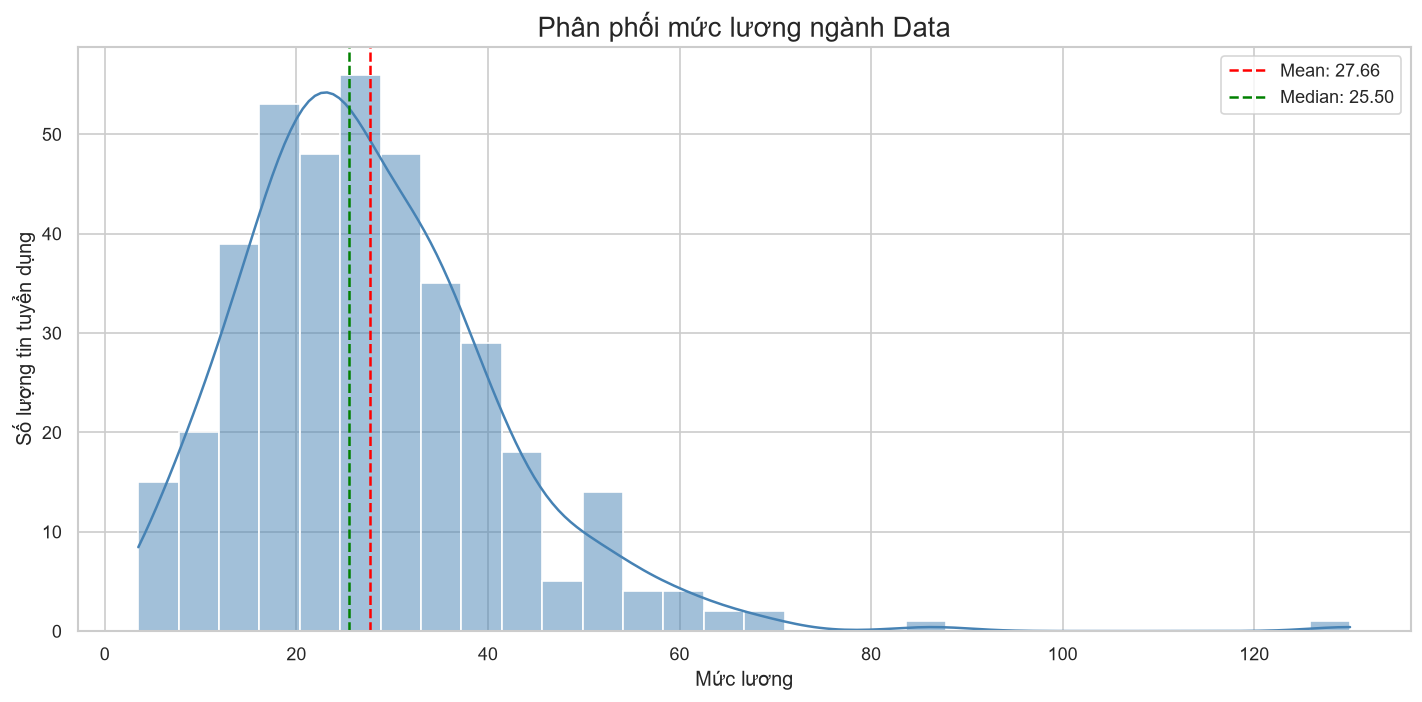

In [11]:
# Lọc các tin tuyển dụng có công bố mức lương
salary = df.loc[
    df["Trang_Thai_Luong"] == "Co_Cong_Bo",
    "Luong_Trung_Binh"
].dropna()

# Vẽ Histogram
plt.figure(figsize=(12, 6))

sns.histplot(
    salary,
    bins=30,
    kde=True,
    color="steelblue"
)

# Đường trung bình
plt.axvline(
    salary.mean(),
    color="red",
    linestyle="--",
    label=f"Mean: {salary.mean():.2f}"
)

# Đường trung vị
plt.axvline(
    salary.median(),
    color="green",
    linestyle="--",
    label=f"Median: {salary.median():.2f}"
)

plt.title("Phân phối mức lương ngành Data", fontsize=16)
plt.xlabel("Mức lương")
plt.ylabel("Số lượng tin tuyển dụng")
plt.legend()
plt.tight_layout()
plt.show()

#### Nhận xét

- Mức lương tập trung chủ yếu trong khoảng từ 15 đến 40.
- Phân phối mức lương có dạng lệch phải.
- Mức lương trung bình (28,04) cao hơn mức lương trung vị (25,50).
- Một số tin tuyển dụng có mức lương đặc biệt cao, với giá trị
  lớn nhất là 215,90.
- Các mức lương cao bất thường có thể kéo giá trị trung bình
  lên cao.
- Kết quả chỉ phản ánh 391 tin tuyển dụng có công bố mức lương,
  tương đương 25,27% tổng số tin tuyển dụng.

### 2.2.3. So sánh mức lương giữa 5 nhóm ngành Data

Sử dụng biểu đồ Boxplot để so sánh mức lương trung vị,
độ phân tán và các giá trị ngoại lệ giữa các nhóm ngành.

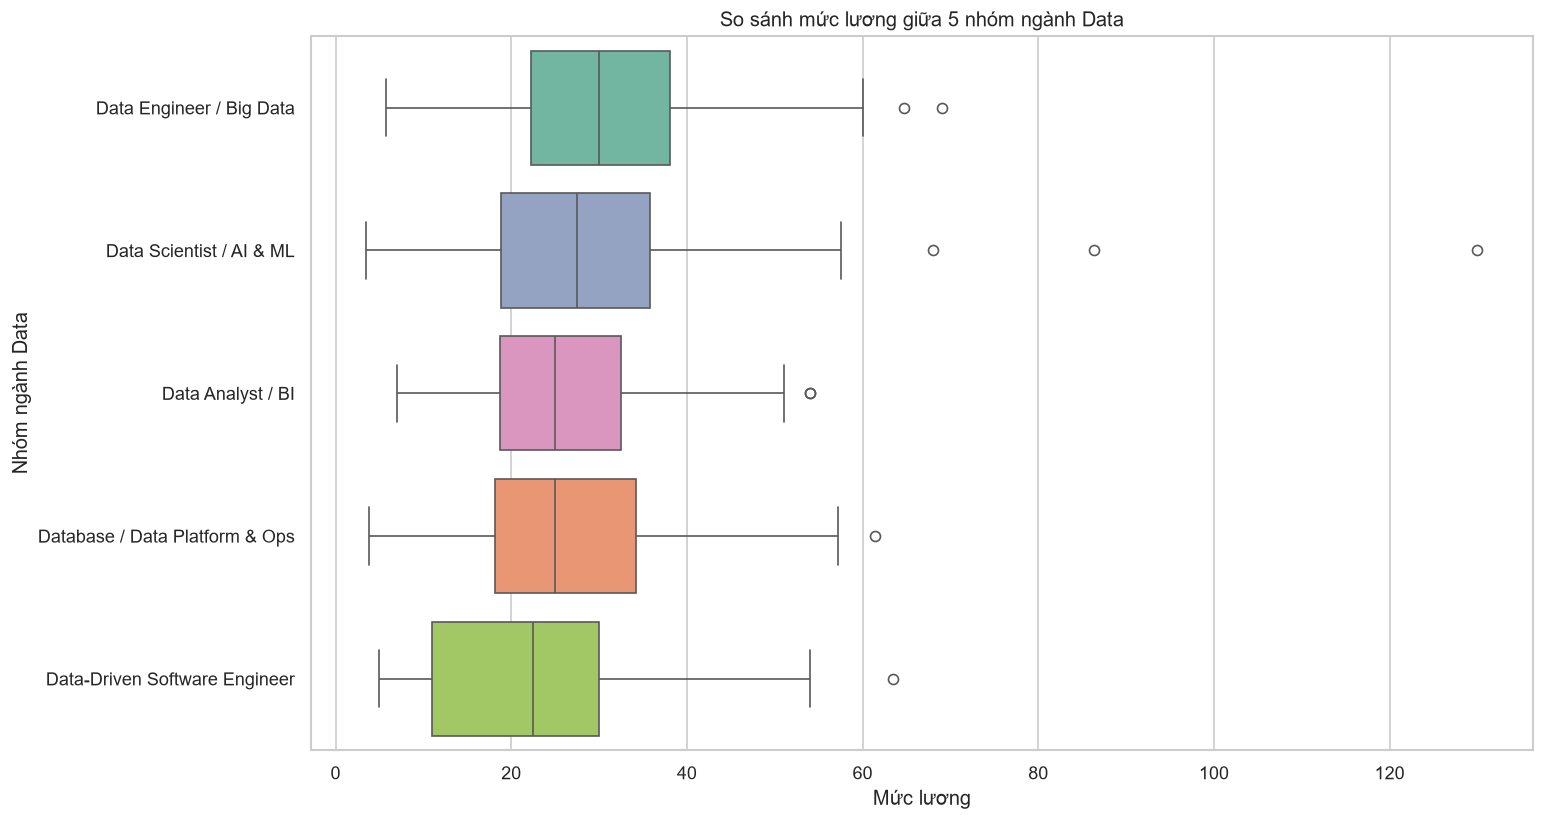

In [12]:
# Lọc dữ liệu có công bố mức lương
df_salary = df.loc[
    (df["Trang_Thai_Luong"] == "Co_Cong_Bo")
    & df["Luong_Trung_Binh"].notna()
].copy()

# Sắp xếp nhóm ngành theo mức lương trung vị
order = (
    df_salary.groupby("Nhom_Nganh_Data")["Luong_Trung_Binh"]
    .median()
    .sort_values(ascending=False)
    .index
)

# Vẽ Boxplot
plt.figure(figsize=(13, 7))

sns.boxplot(
    data=df_salary,
    x="Luong_Trung_Binh",
    y="Nhom_Nganh_Data",
    hue="Nhom_Nganh_Data",
    order=order,
    palette="Set2",
    legend=False
)

plt.title("So sánh mức lương giữa 5 nhóm ngành Data")
plt.xlabel("Mức lương")
plt.ylabel("Nhóm ngành Data")
plt.tight_layout()
plt.show()

### 2.2.4. Phân bố mức lương thực tế theo 5 Cấp bậc (Fresher, Junior, Middle, Senior, Lead)

Đáp ứng yêu cầu Bước 2.2 của đề bài: so sánh phân bố lương thực tế (`Co_Cong_Bo`) theo từng cấp bậc nghề nghiệp.

📊 Bảng thống kê mức lương thực tế (Triệu VNĐ/tháng) theo 5 Cấp bậc:


,So_Tin,Mean,Median,Q1,Q3,Min,Max
Cap_Bac,,,,,,,
Fresher,55,14.80,11.0,7.38,19.50,3.50,64.77
Junior,46,18.73,17.5,15.00,20.00,11.50,34.00
Middle,156,28.69,25.5,21.00,34.51,11.90,130.00
Senior,51,35.97,35.0,30.88,40.00,19.05,69.09
Lead,86,33.85,30.0,24.25,42.50,11.00,68.00


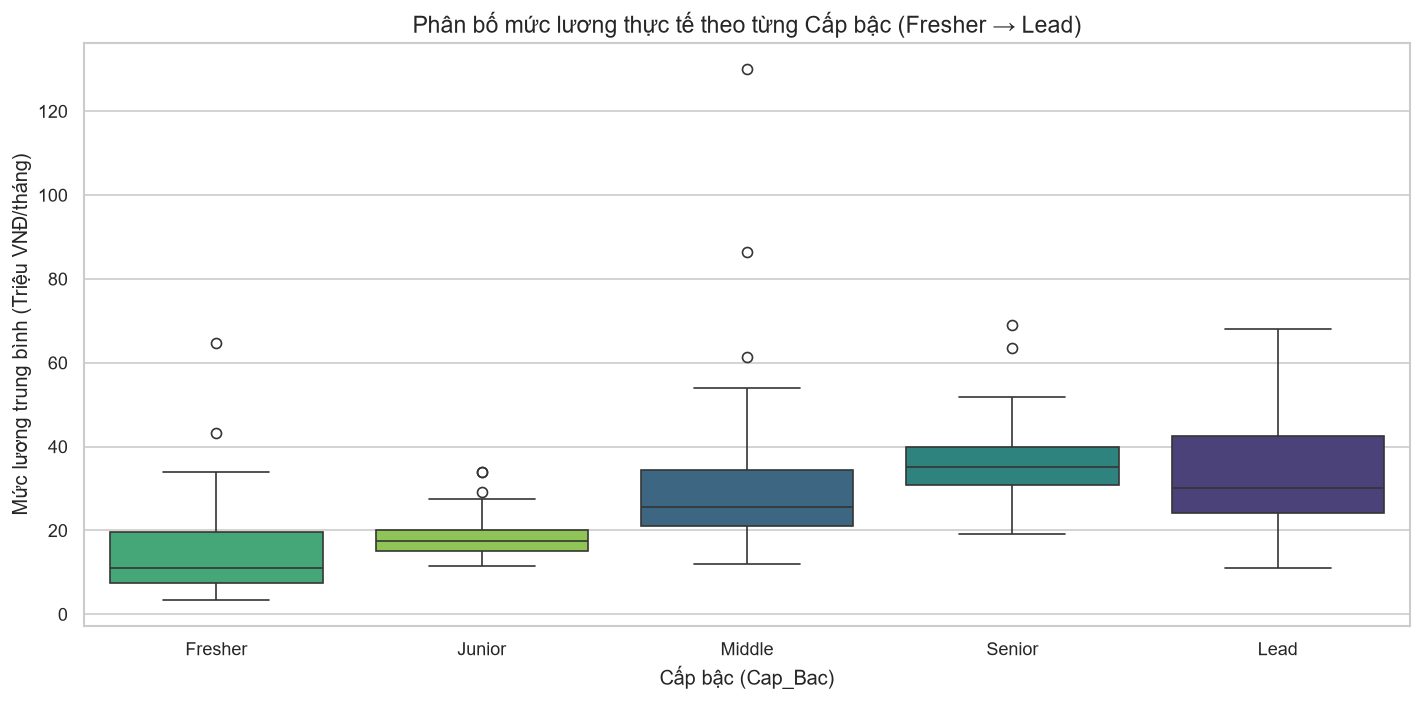

In [13]:
level_order = ["Fresher", "Junior", "Middle", "Senior", "Lead"]
level_stats = (
    df_salary.groupby("Cap_Bac")["Luong_Trung_Binh"]
    .agg(So_Tin="count", Mean="mean", Median="median", Q1=lambda s: s.quantile(0.25), Q3=lambda s: s.quantile(0.75), Min="min", Max="max")
    .reindex(level_order)
)
print("📊 Bảng thống kê mức lương thực tế (Triệu VNĐ/tháng) theo 5 Cấp bậc:")
display(level_stats.round(2))

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df_salary,
    x="Cap_Bac",
    y="Luong_Trung_Binh",
    hue="Cap_Bac",
    order=level_order,
    palette="viridis",
    legend=False
)
plt.title("Phân bố mức lương thực tế theo từng Cấp bậc (Fresher → Lead)", fontsize=14)
plt.xlabel("Cấp bậc (Cap_Bac)")
plt.ylabel("Mức lương trung bình (Triệu VNĐ/tháng)")
plt.tight_layout()
plt.show()

### 2.2.4b. Top 15 kỹ năng/công nghệ được săn đón nhiều nhất trong ngành Data & AI

,Ky_Nang,So_Tin,Ty_Le_%
0,SQL,901,58.24
1,Python,553,35.75
2,English,543,35.10
3,Communication,509,32.90
4,CI_CD,422,27.28
5,PostgreSQL,357,23.08
6,Git,344,22.24
7,Docker,335,21.65
8,Problem_Solving,322,20.81
9,Data_Governance,305,19.72


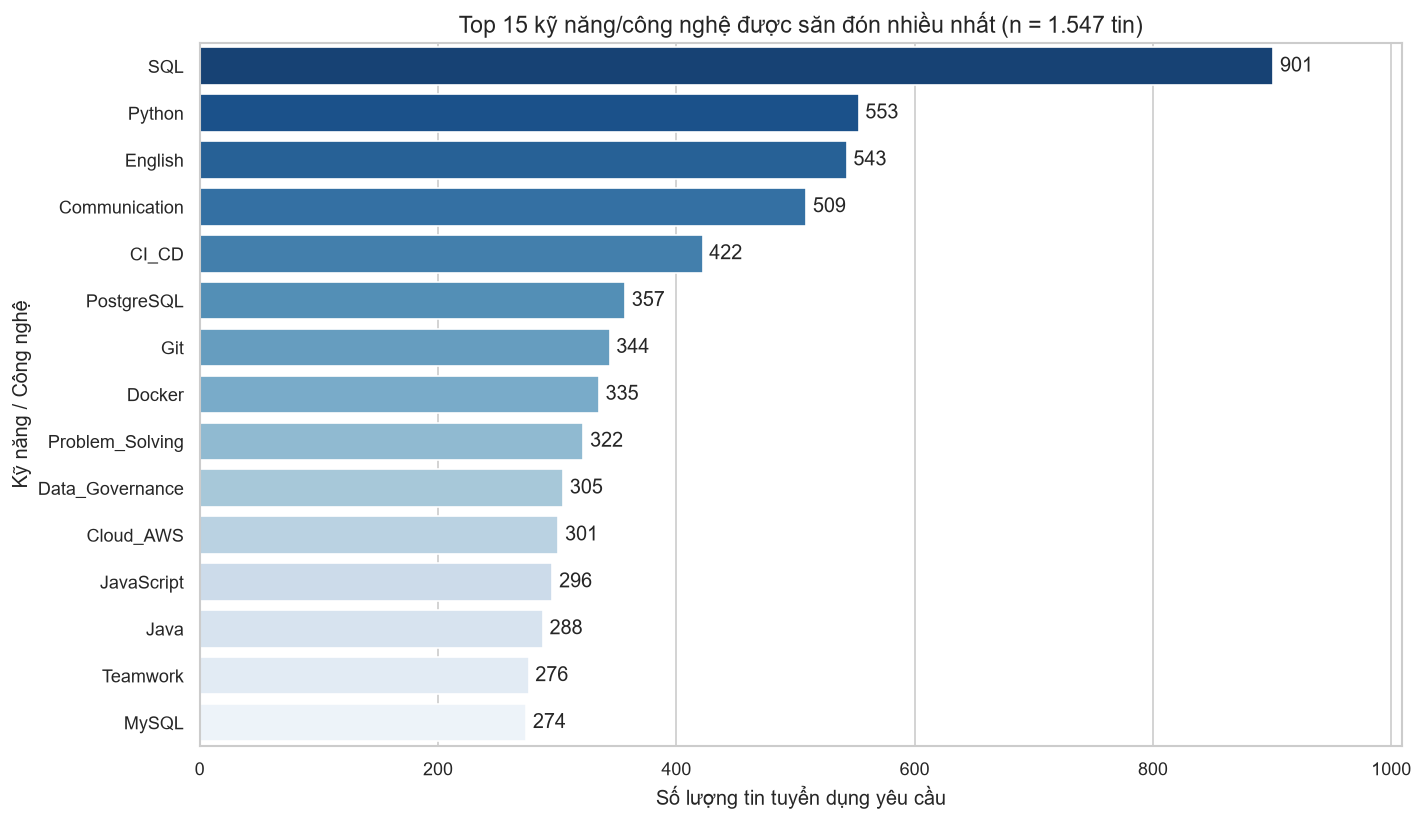

In [14]:
top15_skills = df[skill_cols].sum().sort_values(ascending=False).head(15)
top15_df = pd.DataFrame({
    "Ky_Nang": top15_skills.index.str.replace("Skill_", ""),
    "So_Tin": top15_skills.values,
    "Ty_Le_%": (top15_skills.values / len(df) * 100).round(2)
})
display(top15_df)

plt.figure(figsize=(12, 7))
ax = sns.barplot(data=top15_df, x="So_Tin", y="Ky_Nang", hue="Ky_Nang", palette="Blues_r", legend=False)
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=4)
plt.title("Top 15 kỹ năng/công nghệ được săn đón nhiều nhất (n = 1.547 tin)", fontsize=14)
plt.xlabel("Số lượng tin tuyển dụng yêu cầu")
plt.ylabel("Kỹ năng / Công nghệ")
plt.xlim(0, top15_df["So_Tin"].max() * 1.12)
plt.tight_layout()
plt.show()

### 2.2.4c. So sánh nhu cầu tuyển dụng và mặt bằng đãi ngộ giữa Hà Nội, TP.HCM và Đà Nẵng

📊 So sánh nhu cầu tuyển dụng và mặt bằng lương giữa 3 khu vực trọng điểm:


,Tong_Tin,Ty_Le_Thi_Phan_%,Tin_Co_Luong,Mean_Luong,Median_Luong,Q1,Q3
Dia_Diem_Chuan,,,,,,,
Hà Nội,869,56.17,289,28.27,25.50,20.00,35.00
TP.HCM,561,36.26,85,25.78,24.15,16.50,32.50
Đà Nẵng,21,1.36,4,14.80,15.35,9.88,20.27


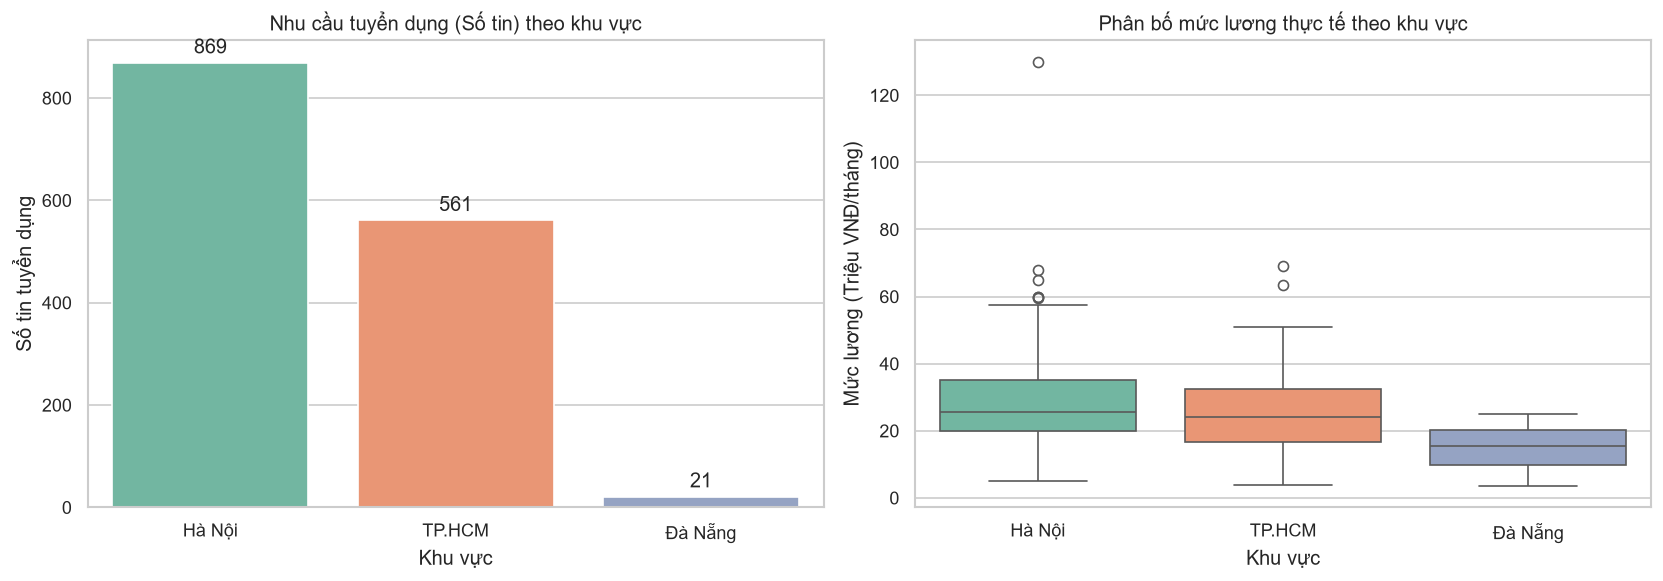

In [15]:
major_cities = ["Hà Nội", "TP.HCM", "Đà Nẵng"]
city_demand = df[df["Dia_Diem_Chuan"].isin(major_cities)]["Dia_Diem_Chuan"].value_counts().reindex(major_cities)
city_salary = (
    df_salary[df_salary["Dia_Diem_Chuan"].isin(major_cities)]
    .groupby("Dia_Diem_Chuan")["Luong_Trung_Binh"]
    .agg(Tin_Co_Luong="count", Mean_Luong="mean", Median_Luong="median", Q1=lambda s: s.quantile(0.25), Q3=lambda s: s.quantile(0.75))
    .reindex(major_cities)
)
city_summary = city_salary.copy()
city_summary.insert(0, "Tong_Tin", city_demand)
city_summary.insert(1, "Ty_Le_Thi_Phan_%", (city_demand / len(df) * 100).round(2))
print("📊 So sánh nhu cầu tuyển dụng và mặt bằng lương giữa 3 khu vực trọng điểm:")
display(city_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax0 = sns.barplot(x=city_summary.index, y=city_summary["Tong_Tin"], hue=city_summary.index, palette="Set2", legend=False, ax=axes[0])
for c in ax0.containers:
    ax0.bar_label(c, padding=3)
axes[0].set_title("Nhu cầu tuyển dụng (Số tin) theo khu vực")
axes[0].set_xlabel("Khu vực")
axes[0].set_ylabel("Số tin tuyển dụng")

sns.boxplot(
    data=df_salary[df_salary["Dia_Diem_Chuan"].isin(major_cities)],
    x="Dia_Diem_Chuan",
    y="Luong_Trung_Binh",
    hue="Dia_Diem_Chuan",
    order=major_cities,
    palette="Set2",
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Phân bố mức lương thực tế theo khu vực")
axes[1].set_xlabel("Khu vực")
axes[1].set_ylabel("Mức lương (Triệu VNĐ/tháng)")
plt.tight_layout()
plt.show()

### 2.2.5. Phân tích tương quan giữa các kỹ năng

Sử dụng Heatmap để khảo sát mối tương quan giữa
60 kỹ năng trong dữ liệu tuyển dụng, từ đó xác định
những kỹ năng có xu hướng xuất hiện cùng nhau.

In [16]:
# Lấy 60 cột kỹ năng
skill_cols = [
    col for col in df.columns
    if col.startswith("Skill_")
]

# Tạo ma trận tương quan Pearson
skill_corr = df[skill_cols].corr(method="pearson")

# Loại bỏ tiền tố Skill_ khi hiển thị
skill_corr.index = skill_corr.index.str.replace("Skill_", "")
skill_corr.columns = skill_corr.columns.str.replace("Skill_", "")

print("Kích thước ma trận:", skill_corr.shape)

skill_corr.head()

Kích thước ma trận: (60, 60)


,Python,SQL,R,Scala,Java,C_Cpp,JavaScript,Bash_Shell,PowerBI,Tableau,Looker,Excel,Statistics,AB_Testing,Data_Storytelling,Spark,Hadoop,Kafka,Airflow,dbt,ETL,Data_Warehouse,Data_Lake,Data_Modeling,Machine_Learning,Deep_Learning,Pandas,NumPy,Scikit_Learn,PyTorch,TensorFlow,NLP,Computer_Vision,LLM_GenAI,MLOps,PostgreSQL,MySQL,SQL_Server,Oracle,MongoDB,Redis,Elasticsearch,BigQuery,Snowflake,Databricks,Redshift,Cloud_AWS,Cloud_Azure,Cloud_GCP,Docker,Kubernetes,Git,Linux,CI_CD,English,Communication,Problem_Solving,Teamwork,Agile_Scrum,Data_Governance
Python,1.000000,0.098249,0.161030,0.112763,0.024429,0.163236,0.113807,0.263307,0.084530,0.084514,0.066282,0.043936,0.158209,0.081382,0.120568,0.160748,0.080947,-0.007472,0.171477,0.115463,0.161372,0.083088,0.100369,0.051312,0.300803,0.215669,0.149502,0.108142,0.118541,0.214515,0.207370,0.122699,0.161751,0.281405,0.158101,-0.011574,-0.035138,-0.115635,-0.133259,0.024307,-0.024881,0.046322,0.126424,0.032768,0.043735,0.083731,0.154694,0.125744,0.132258,0.141624,0.086019,0.168768,0.078434,0.112500,0.126875,0.086262,0.122579,0.082224,-0.056748,0.050761
SQL,0.098249,1.000000,0.079561,0.034917,0.239978,-0.036973,0.231939,-0.029708,0.139639,0.131147,0.093061,0.031864,0.099459,-0.025053,0.094914,0.084002,0.062045,0.154580,0.042634,0.079561,0.141166,0.120224,0.085193,0.177371,-0.128144,-0.114462,0.070620,0.051943,0.015105,-0.126894,-0.084375,-0.081773,-0.136480,-0.120479,-0.101984,0.457561,0.389406,0.345683,0.279167,0.296972,0.243033,0.062208,0.113311,0.056546,-0.017085,0.073606,0.035403,0.033264,0.048622,0.142853,0.083462,0.188017,0.102011,0.147793,0.122889,0.185652,0.150006,0.134386,0.160827,0.060497
R,0.161030,0.079561,1.000000,0.036175,-0.057446,-0.021026,-0.058424,-0.031065,0.130038,0.087874,0.114308,0.087008,0.265979,-0.018005,0.105149,0.059822,0.101881,-0.017263,0.013590,-0.014426,0.012127,0.092849,0.007891,-0.040509,0.097437,0.024765,-0.013393,-0.009688,-0.010620,-0.021951,0.013528,-0.022842,-0.026537,-0.053735,0.033774,-0.065787,-0.027122,-0.049034,0.036261,-0.052732,-0.042202,-0.031065,-0.018539,-0.015394,-0.012279,-0.012279,-0.031451,-0.047601,-0.024561,-0.036637,-0.024444,-0.024841,-0.044266,-0.049047,-0.008259,0.020467,-0.007789,0.029589,-0.047339,0.050260
Scala,0.112763,0.034917,0.036175,1.000000,0.127602,0.015032,-0.024401,-0.028841,-0.021121,0.007563,0.017484,-0.032482,-0.018228,-0.016716,0.058620,0.399595,0.324796,0.190988,0.091469,0.085744,0.152888,0.082084,0.239710,0.001153,-0.000145,-0.024816,-0.012435,-0.008995,-0.009859,-0.020379,-0.018628,-0.021207,-0.024637,-0.018400,0.008887,0.022502,-0.005615,-0.045524,-0.001123,0.094544,0.054647,0.092205,0.177431,0.078799,-0.011400,0.104621,0.063797,0.075749,0.111462,-0.015879,0.028832,-0.045516,-0.041097,-0.002411,0.028663,0.034332,-0.013802,0.009354,-0.009542,0.107009
Java,0.024429,0.239978,-0.057446,0.127602,1.000000,0.121592,0.235981,-0.062051,-0.154495,-0.088370,-0.079899,-0.133136,-0.122921,-0.037716,-0.159570,0.031093,0.041126,0.288363,-0.008483,-0.015368,-0.088412,-0.088760,-0.033915,0.019664,-0.121046,-0.051614,-0.038255,-0.038579,-0.042288,-0.068628,-0.049243,-0.054768,-0.050486,-0.044688,-0.068169,0.285918,0.274009,0.132206,0.254724,0.227653,0.230195,0.116057,0.014298,0.004555,-0.048894,0.000350,0.100530,0.052873,0.061424,0.236406,0.218155,0.187536,0.048924,0.206706,0.051884,0.085679,0.041128,0.098109,0.137657,-0.099265


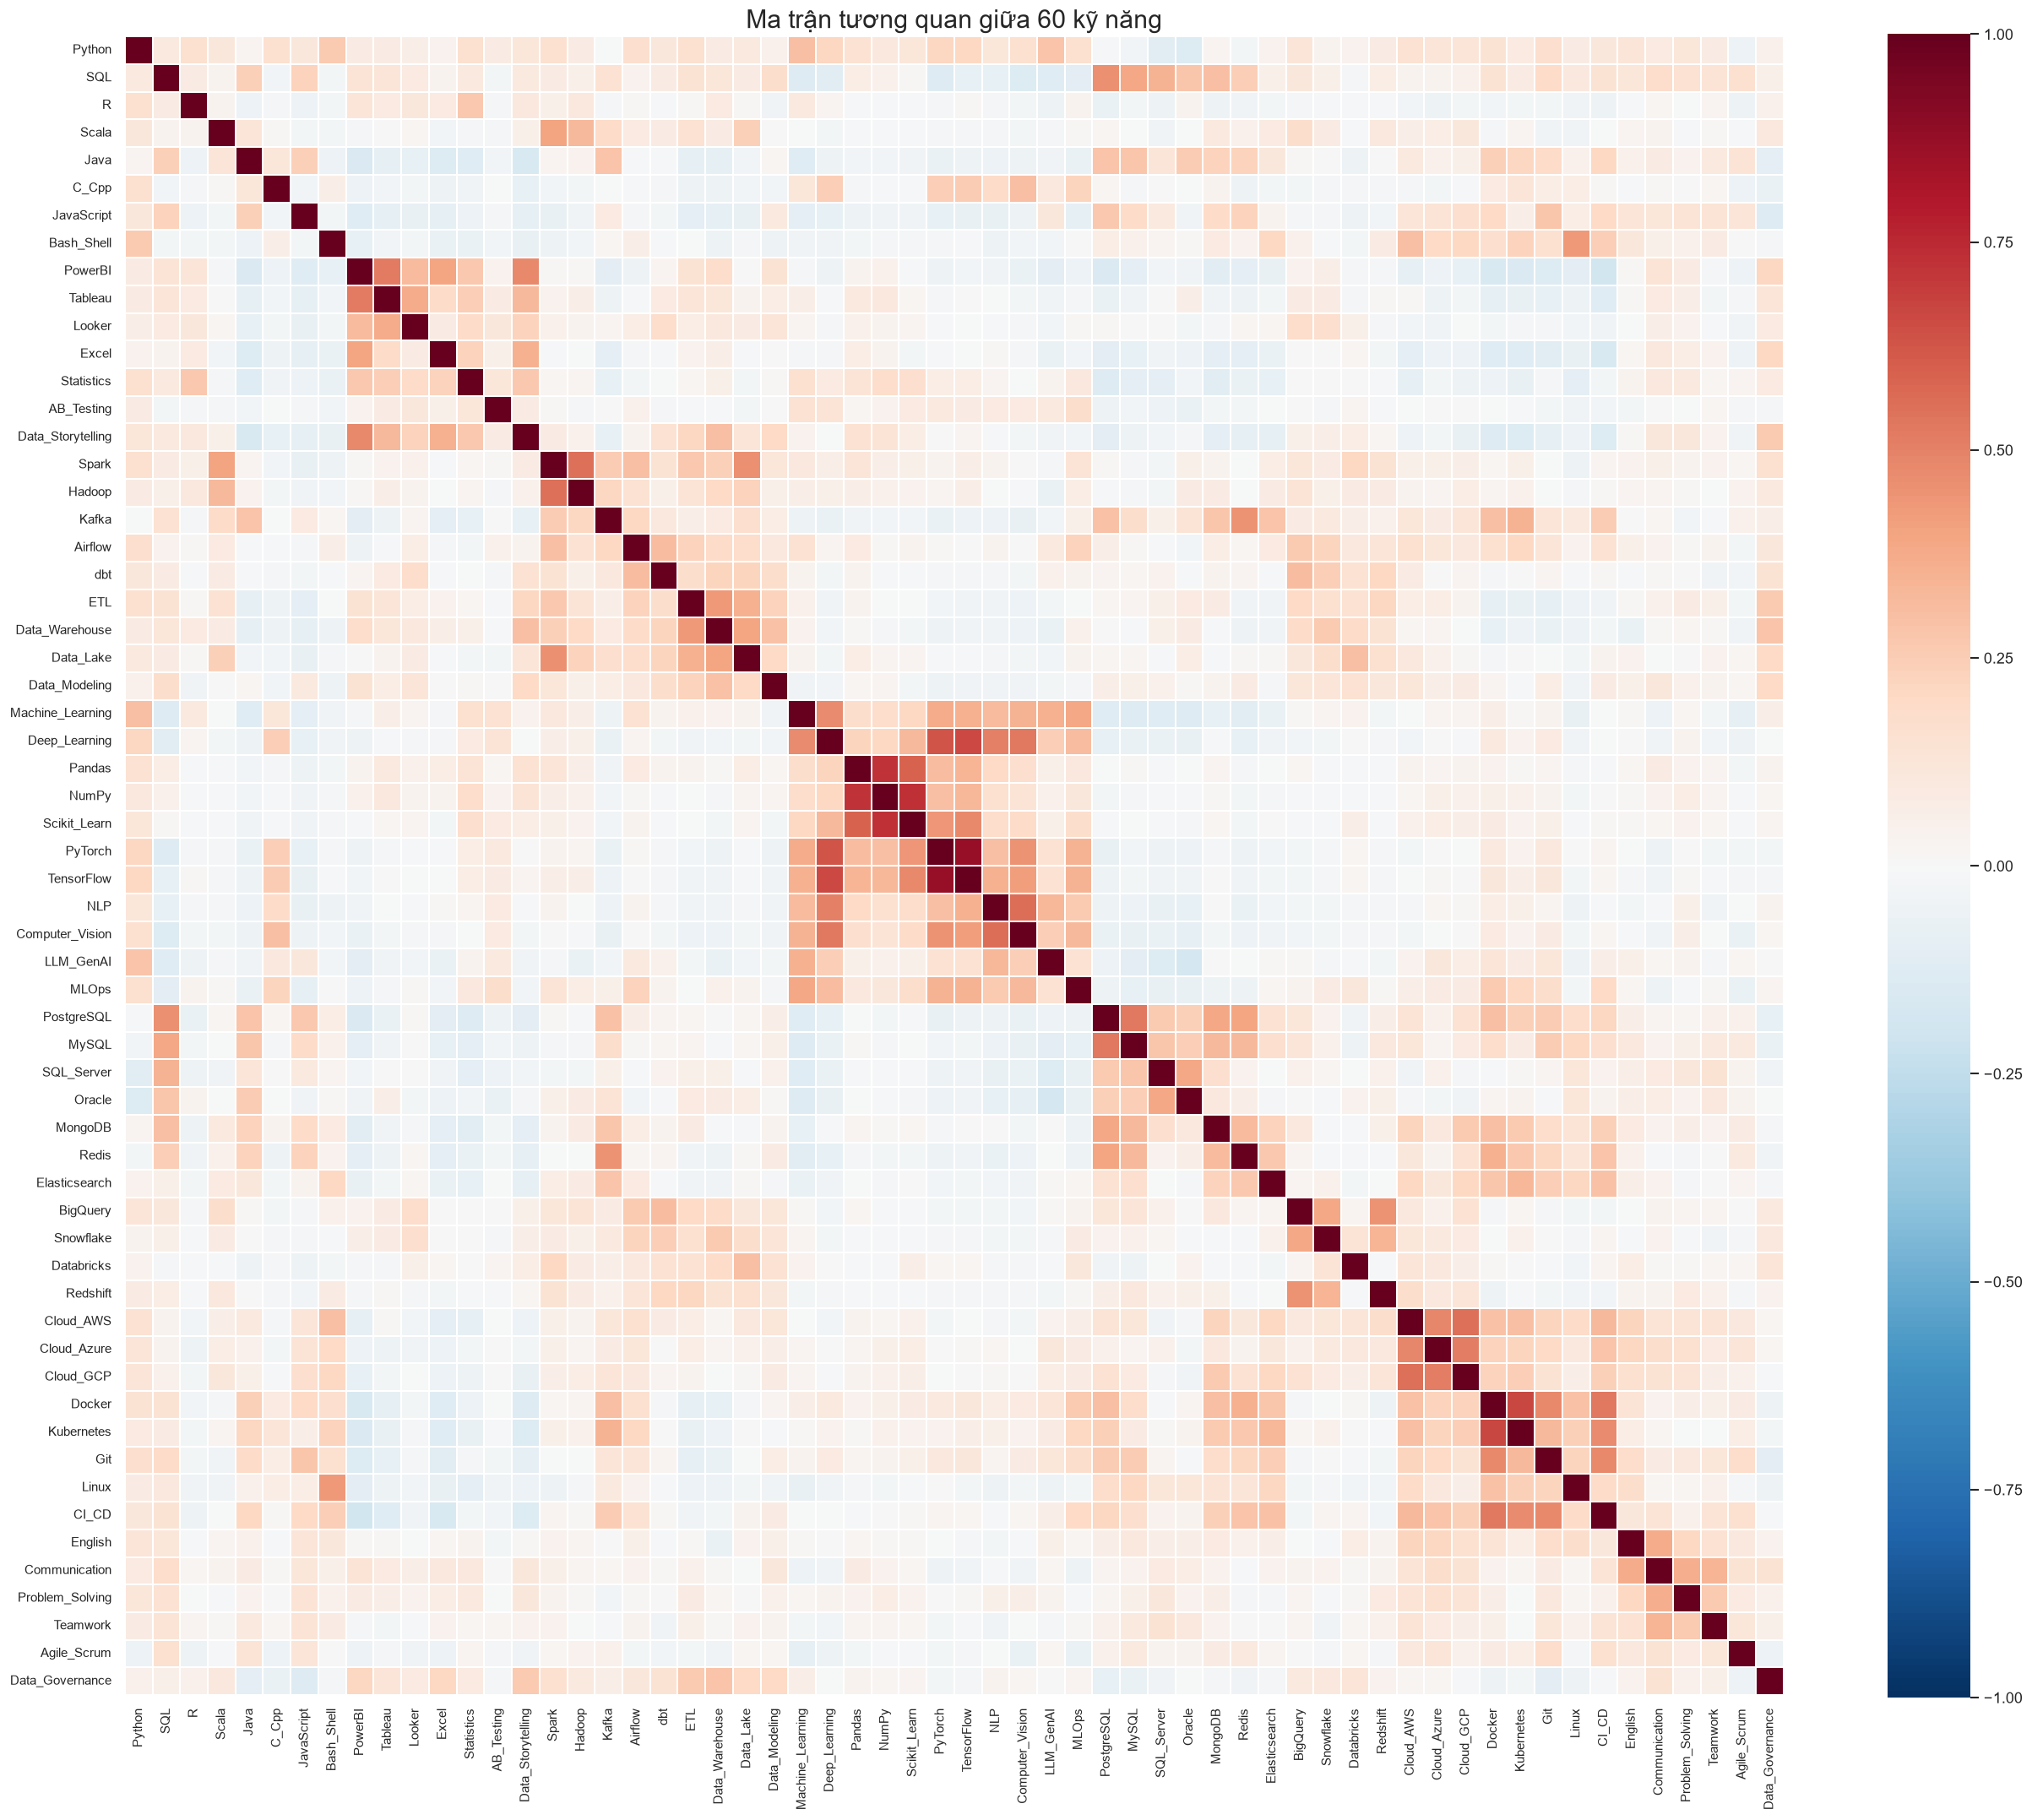

In [17]:
plt.figure(figsize=(22, 18))

sns.heatmap(
    skill_corr,
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    annot=False,
    linewidths=0.1
)

plt.title(
    "Ma trận tương quan giữa 60 kỹ năng",
    fontsize=18
)

plt.xticks(rotation=90, fontsize=9)
plt.yticks(rotation=0, fontsize=9)

plt.tight_layout()
plt.show()

#### Top 10 cặp kỹ năng có tương quan dương cao nhất

In [18]:
# Chỉ lấy nửa trên của ma trận, loại bỏ đường chéo
mask = np.triu(
    np.ones(skill_corr.shape, dtype=bool),
    k=1
)

# Trích xuất các cặp kỹ năng có tương quan dương
pairs = skill_corr.where(mask).stack()

top_corr = (
    pairs[pairs > 0]
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

top_corr.columns = [
    "Ky_Nang_1",
    "Ky_Nang_2",
    "He_So_Tuong_Quan"
]

top_corr.round(4)

,Ky_Nang_1,Ky_Nang_2,He_So_Tuong_Quan
0,PyTorch,TensorFlow,0.8691
1,NumPy,Scikit_Learn,0.7284
2,Pandas,NumPy,0.7233
3,Docker,Kubernetes,0.6657
4,Deep_Learning,TensorFlow,0.6569
5,Deep_Learning,PyTorch,0.6316
6,Pandas,Scikit_Learn,0.5922
7,NLP,Computer_Vision,0.5599
8,Cloud_AWS,Cloud_GCP,0.5502
9,Spark,Hadoop,0.5496


### 2.2.7. Phân tích phân bố địa lý

Khảo sát nhu cầu tuyển dụng ngành Data theo địa điểm,
xác định những khu vực tập trung nhiều tin tuyển dụng nhất.

In [19]:
location_counts = df["Dia_Diem_Chuan"].value_counts()

location_counts

Dia_Diem_Chuan
Hà Nội     869
TP.HCM     561
Khác        92
Đà Nẵng     21
Remote       4
Name: count, dtype: int64

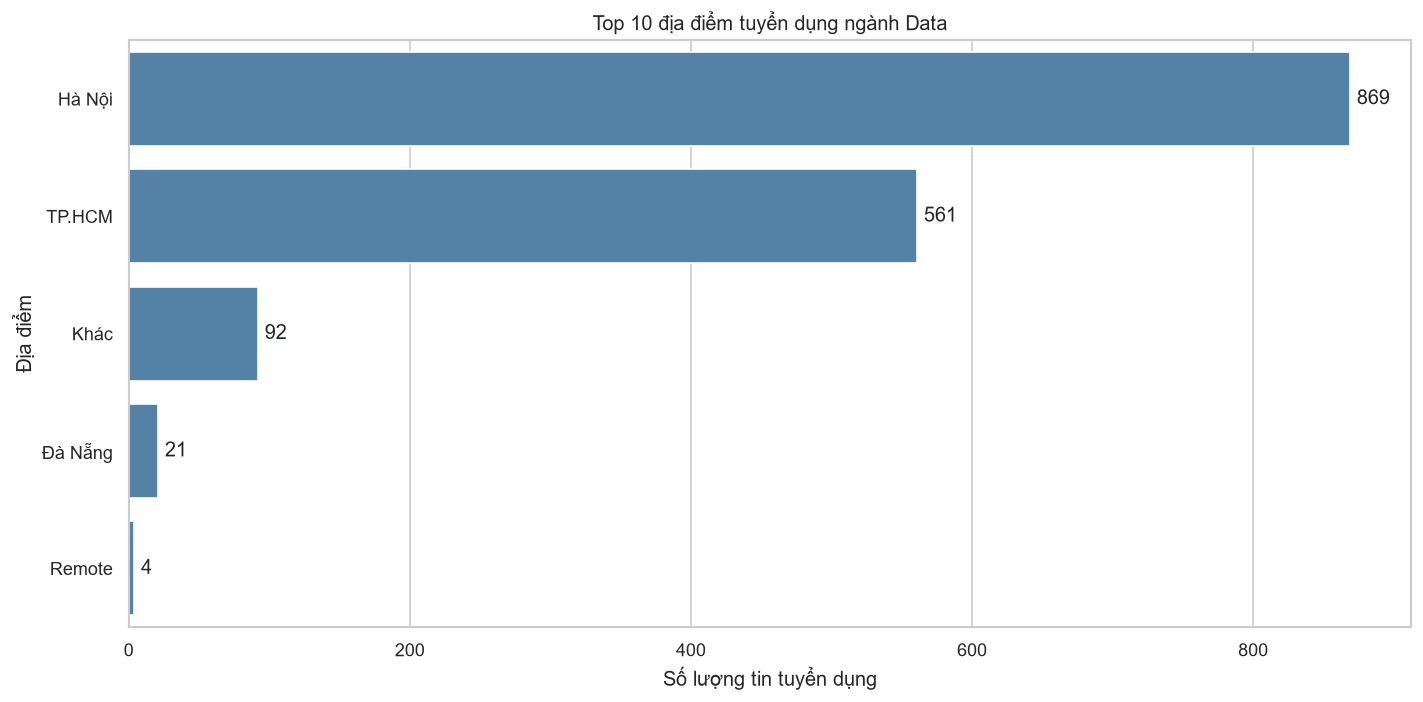

In [20]:
top_locations = location_counts.head(10)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=top_locations.values,
    y=top_locations.index,
    color="steelblue"
)

ax.bar_label(ax.containers[0], padding=4)

plt.title("Top 10 địa điểm tuyển dụng ngành Data")
plt.xlabel("Số lượng tin tuyển dụng")
plt.ylabel("Địa điểm")
plt.tight_layout()
plt.show()

### 2.2.8. Phân tích mô hình làm việc

Khảo sát tỷ lệ các mô hình làm việc trong ngành Data,
bao gồm Onsite, Hybrid và Remote. Qua đó xác định
xu hướng tổ chức công việc của các doanh nghiệp.

In [21]:
work_counts = df["Mo_Hinh_Lam_Viec"].value_counts()

work_summary = pd.DataFrame({
    "So_Luong": work_counts,
    "Ty_Le (%)": (work_counts / len(df) * 100).round(2)
})

work_summary

,So_Luong,Ty_Le (%)
Mo_Hinh_Lam_Viec,,
On-site,1401,90.56
Hybrid,102,6.59
Remote,44,2.84


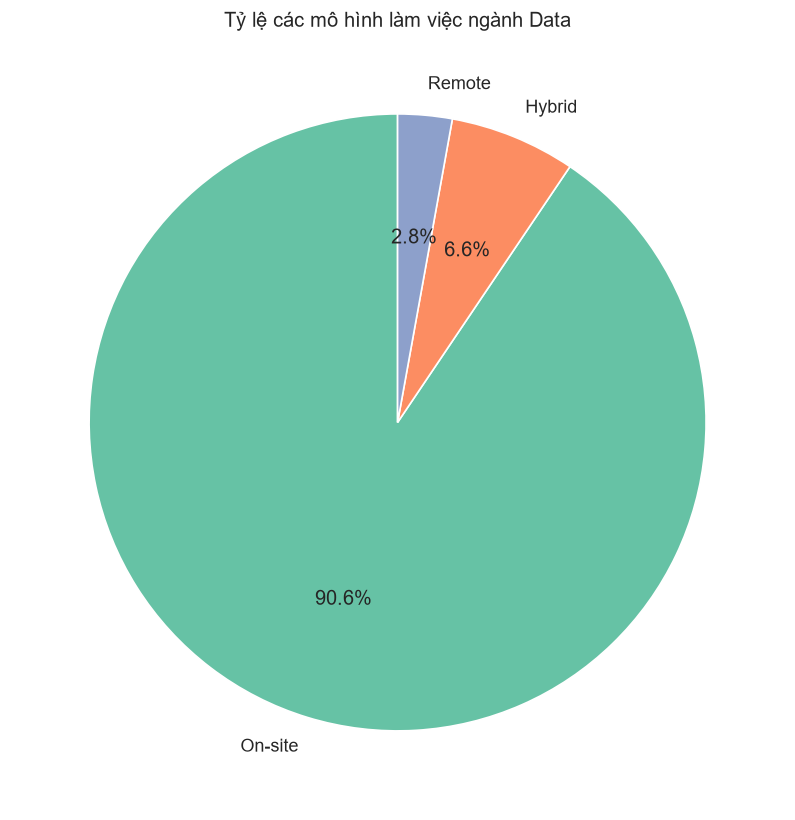

In [22]:
plt.figure(figsize=(9, 7))

plt.pie(
    work_counts.values,
    labels=work_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=sns.color_palette("Set2", len(work_counts)),
    wedgeprops={"edgecolor": "white"}
)

plt.title("Tỷ lệ các mô hình làm việc ngành Data")
plt.tight_layout()
plt.show()

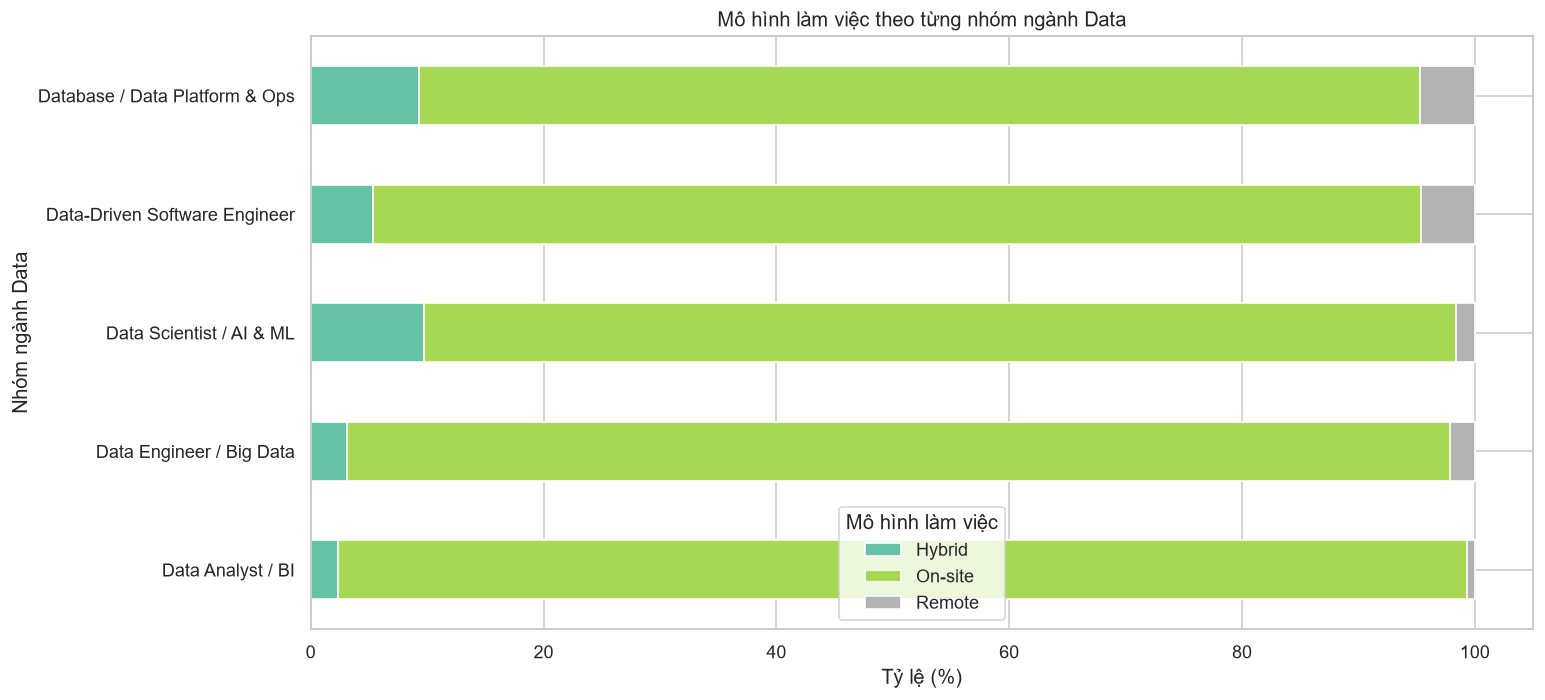

In [23]:
work_by_field = pd.crosstab(
    df["Nhom_Nganh_Data"],
    df["Mo_Hinh_Lam_Viec"],
    normalize="index"
) * 100

work_by_field.plot(
    kind="barh",
    stacked=True,
    figsize=(13, 6),
    colormap="Set2"
)

plt.title("Mô hình làm việc theo từng nhóm ngành Data")
plt.xlabel("Tỷ lệ (%)")
plt.ylabel("Nhóm ngành Data")
plt.legend(title="Mô hình làm việc")
plt.tight_layout()
plt.show()

## 2.3. Phân cụm nghề nghiệp bằng K-Means

### 2.3.1. Chuẩn bị và chuẩn hóa dữ liệu

Sử dụng các thuộc tính kỹ năng để phân cụm các tin
tuyển dụng có đặc điểm nghề nghiệp tương đồng.

In [24]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

In [25]:
skill_cols = [
    col for col in df.columns
    if col.startswith("Skill_")
]

X = df[skill_cols].copy()

print("Kích thước dữ liệu phân cụm:", X.shape)
print("Số giá trị thiếu:", X.isna().sum().sum())
print("Số tin không ghi nhận kỹ năng:", (X.sum(axis=1) == 0).sum())

X.head()

Kích thước dữ liệu phân cụm: (1547, 60)
Số giá trị thiếu: 0
Số tin không ghi nhận kỹ năng: 181


,Skill_Python,Skill_SQL,Skill_R,Skill_Scala,Skill_Java,Skill_C_Cpp,Skill_JavaScript,Skill_Bash_Shell,Skill_PowerBI,Skill_Tableau,Skill_Looker,Skill_Excel,Skill_Statistics,Skill_AB_Testing,Skill_Data_Storytelling,Skill_Spark,Skill_Hadoop,Skill_Kafka,Skill_Airflow,Skill_dbt,Skill_ETL,Skill_Data_Warehouse,Skill_Data_Lake,Skill_Data_Modeling,Skill_Machine_Learning,Skill_Deep_Learning,Skill_Pandas,Skill_NumPy,Skill_Scikit_Learn,Skill_PyTorch,Skill_TensorFlow,Skill_NLP,Skill_Computer_Vision,Skill_LLM_GenAI,Skill_MLOps,Skill_PostgreSQL,Skill_MySQL,Skill_SQL_Server,Skill_Oracle,Skill_MongoDB,Skill_Redis,Skill_Elasticsearch,Skill_BigQuery,Skill_Snowflake,Skill_Databricks,Skill_Redshift,Skill_Cloud_AWS,Skill_Cloud_Azure,Skill_Cloud_GCP,Skill_Docker,Skill_Kubernetes,Skill_Git,Skill_Linux,Skill_CI_CD,Skill_English,Skill_Communication,Skill_Problem_Solving,Skill_Teamwork,Skill_Agile_Scrum,Skill_Data_Governance
0,1,1,0,1,0,0,0,0,1,1,1,0,0,0,1,1,1,1,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,1,1,1,1,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0
1,1,1,0,0,0,0,0,0,0,0,1,0,0,0,1,1,0,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,1,1,1,0,1,0,1,1,0,0,0,1,0,1,0,0,1,1,0,0,1,1,0,0,0,0,1
2,1,1,0,1,1,0,0,0,0,0,0,0,1,0,1,1,1,1,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,1,1,0,1,1,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,1
3,1,1,0,0,0,0,0,1,1,1,1,0,0,0,1,0,0,1,1,1,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,1,1,0,1,1,1,1,1,0,0,0,0,0,1,1,1,1,0,0,1,0,0,0,1
4,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,1,0,1,1,1,0,0,0,0,1,1,1,1,1,1,1


### 2.3.2. Chuẩn hóa dữ liệu bằng StandardScaler

Chuẩn hóa các thuộc tính trước khi thực hiện K-Means
nhằm điều chỉnh ảnh hưởng của các đặc trưng khi tính
khoảng cách Euclid.

In [26]:
# Chuẩn hóa dữ liệu
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Kích thước dữ liệu:", X_scaled.shape)

print("Dữ liệu sau chuẩn hóa:")
print(X_scaled[:5])

Kích thước dữ liệu: (1547, 60)
Dữ liệu sau chuẩn hóa:
[[ 1.34069697  0.84674738 -0.12010924  8.96777858 -0.47828128 -0.17506066
  -0.48642647 -0.25864368  2.8090576   4.9356515   5.986095   -0.29129493
  -0.33726977 -0.14990634  2.2045064   4.9356515   7.11102431  2.46907478
  -0.26006317 -0.12010924  2.91389731 -0.27937212  5.36190265 -0.33726977
  -0.43378802 -0.22254236 -0.11151034 -0.0806609  -0.08841713 -0.18275703
  -0.16705381 -0.19018093 -0.22093791 -0.44738703 -0.19736341  1.82574186
   2.1554548  -0.40824829  2.27771816  2.27771816  2.84604989  3.86632301
   6.47859724 -0.128163   -0.1022286  -0.1022286  -0.4915008  -0.39631813
   2.85549403 -0.52574009 -0.44738703 -0.5347446  -0.36855076 -0.61246315
  -0.73541597 -0.70026144 -0.51269596 -0.46599555  2.53722289 -0.49555187]
 [ 1.34069697  0.84674738 -0.12010924 -0.11151034 -0.47828128 -0.17506066
  -0.48642647 -0.25864368 -0.35599128 -0.2026075   5.986095   -0.29129493
  -0.33726977 -0.14990634  2.2045064   4.9356515  -0.1406

### 2.3.3. Xác định số cụm bằng Elbow Method

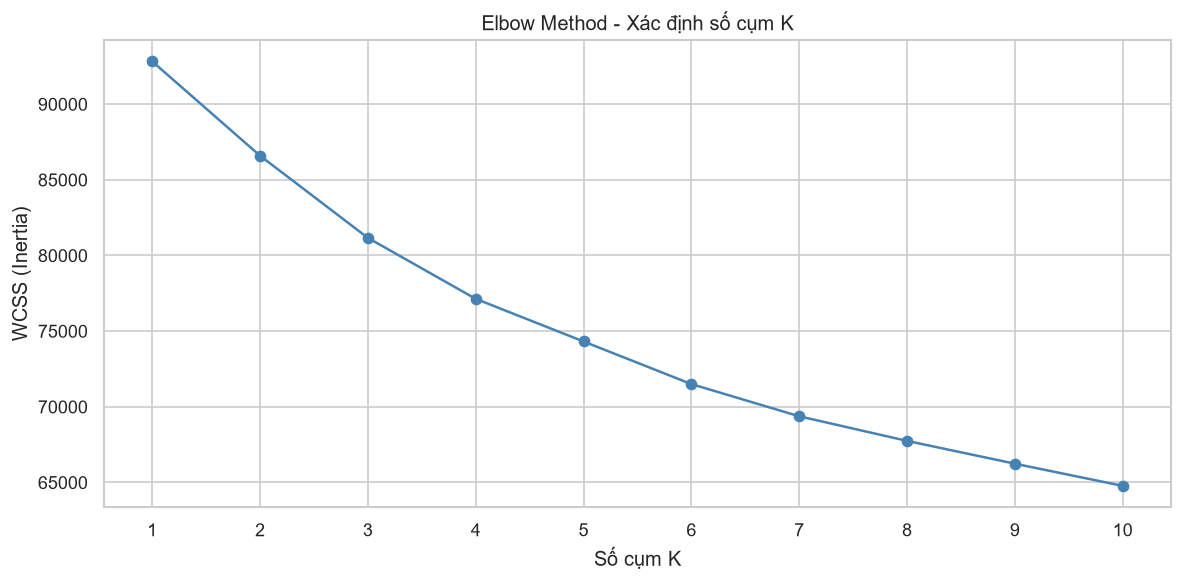

In [27]:
inertias = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertias.append(kmeans.inertia_)

plt.figure(figsize=(10, 5))

plt.plot(
    K_range,
    inertias,
    marker="o",
    color="steelblue"
)

plt.title("Elbow Method - Xác định số cụm K")
plt.xlabel("Số cụm K")
plt.ylabel("WCSS (Inertia)")
plt.xticks(list(K_range))
plt.grid(True)
plt.tight_layout()
plt.show()

In [28]:
print("Kích thước:", X_scaled.shape)
print("Số giá trị NaN:", np.isnan(X_scaled).sum())
print("Số giá trị vô cực:", np.isinf(X_scaled).sum())
print("WCSS tại K = 1:", inertias[0])
print("Số đặc trưng có biến thiên:", (X.std(ddof=0) > 0).sum())

Kích thước: (1547, 60)
Số giá trị NaN: 0
Số giá trị vô cực: 0
WCSS tại K = 1: 92819.99999999997
Số đặc trưng có biến thiên: 60


### 2.3.4. Đánh giá chất lượng phân cụm bằng Silhouette Score

K = 2: Silhouette Score = 0.1541
K = 3: Silhouette Score = 0.1603
K = 4: Silhouette Score = 0.1495
K = 5: Silhouette Score = 0.1523
K = 6: Silhouette Score = 0.1497
K = 7: Silhouette Score = 0.1154
K = 8: Silhouette Score = 0.0908
K = 9: Silhouette Score = 0.0932
K = 10: Silhouette Score = 0.1091


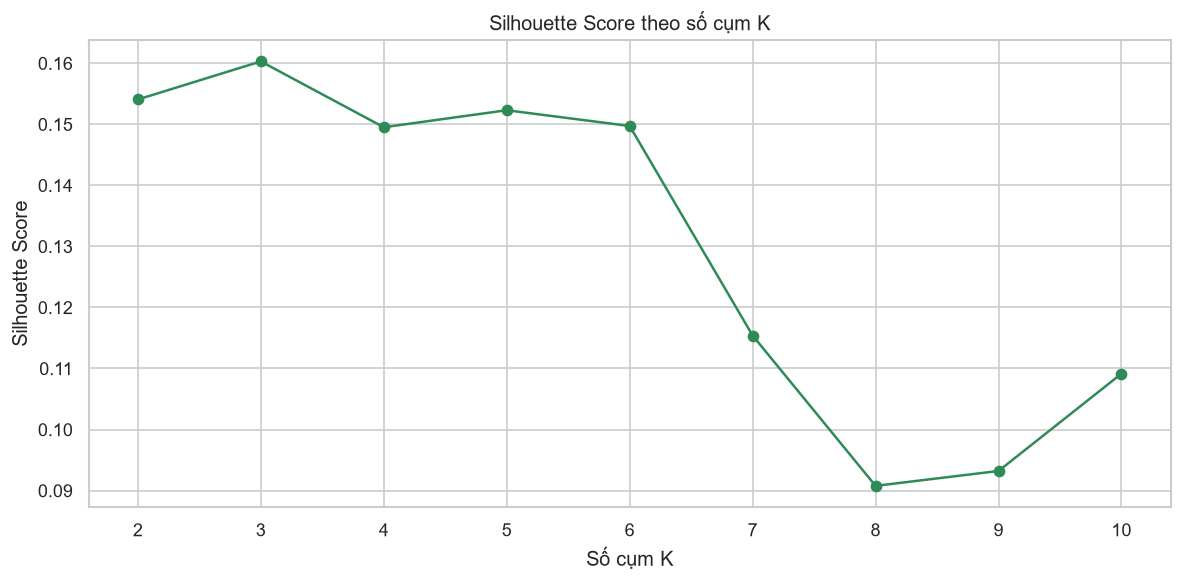

In [29]:
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    silhouette_scores.append(score)

    print(f"K = {k}: Silhouette Score = {score:.4f}")

plt.figure(figsize=(10, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker="o",
    color="seagreen"
)

plt.title("Silhouette Score theo số cụm K")
plt.xlabel("Số cụm K")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.grid(True)
plt.tight_layout()
plt.show()

In [30]:
evaluation = pd.DataFrame({
    "K": range(2, 11),
    "WCSS": inertias[1:],
    "Silhouette_Score": silhouette_scores
})

display(evaluation.round(4))

best_k = evaluation.loc[
    evaluation["Silhouette_Score"].idxmax(), "K"
]

print("K có Silhouette Score cao nhất:", best_k)

K có Silhouette Score cao nhất: 3


,K,WCSS,Silhouette_Score
0,2,86586.7036,0.1541
1,3,81159.0070,0.1603
2,4,77130.0346,0.1495
3,5,74312.9793,0.1523
4,6,71497.4453,0.1497
5,7,69369.4991,0.1154
6,8,67743.3569,0.0908
7,9,66236.4125,0.0932
8,10,64771.6236,0.1091


### 2.3.6. Huấn luyện mô hình K-Means

Thực hiện phân cụm với K = 3 để khám phá ba nhóm
chân dung nghề nghiệp dựa trên đặc điểm kỹ năng.

In [31]:
k_final = 3

kmeans_final = KMeans(
    n_clusters=k_final,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans_final.fit_predict(X_scaled)

# Tạo bản sao để giữ nguyên dữ liệu của Thành viên 1
df_cluster = df.copy()

df_cluster["Cluster"] = cluster_labels

print("WCSS:", kmeans_final.inertia_)
print("Silhouette Score:", silhouette_score(
    X_scaled, cluster_labels
))

WCSS: 81159.00703459048
Silhouette Score: 0.16029124791387603


In [32]:
cluster_counts = df_cluster["Cluster"].value_counts().sort_index()

cluster_summary = pd.DataFrame({
    "So_Luong": cluster_counts,
    "Ty_Le (%)": (cluster_counts / len(df_cluster) * 100).round(2)
})

cluster_summary

,So_Luong,Ty_Le (%)
Cluster,,
0,476,30.77
1,62,4.01
2,1009,65.22


Ánh xạ tên cụm theo hồ sơ kỹ năng thực tế: {np.int32(0): 'Data Engineering & Infrastructure', np.int32(1): 'AI & Machine Learning', np.int32(2): 'General Data & Analytics / BI'}


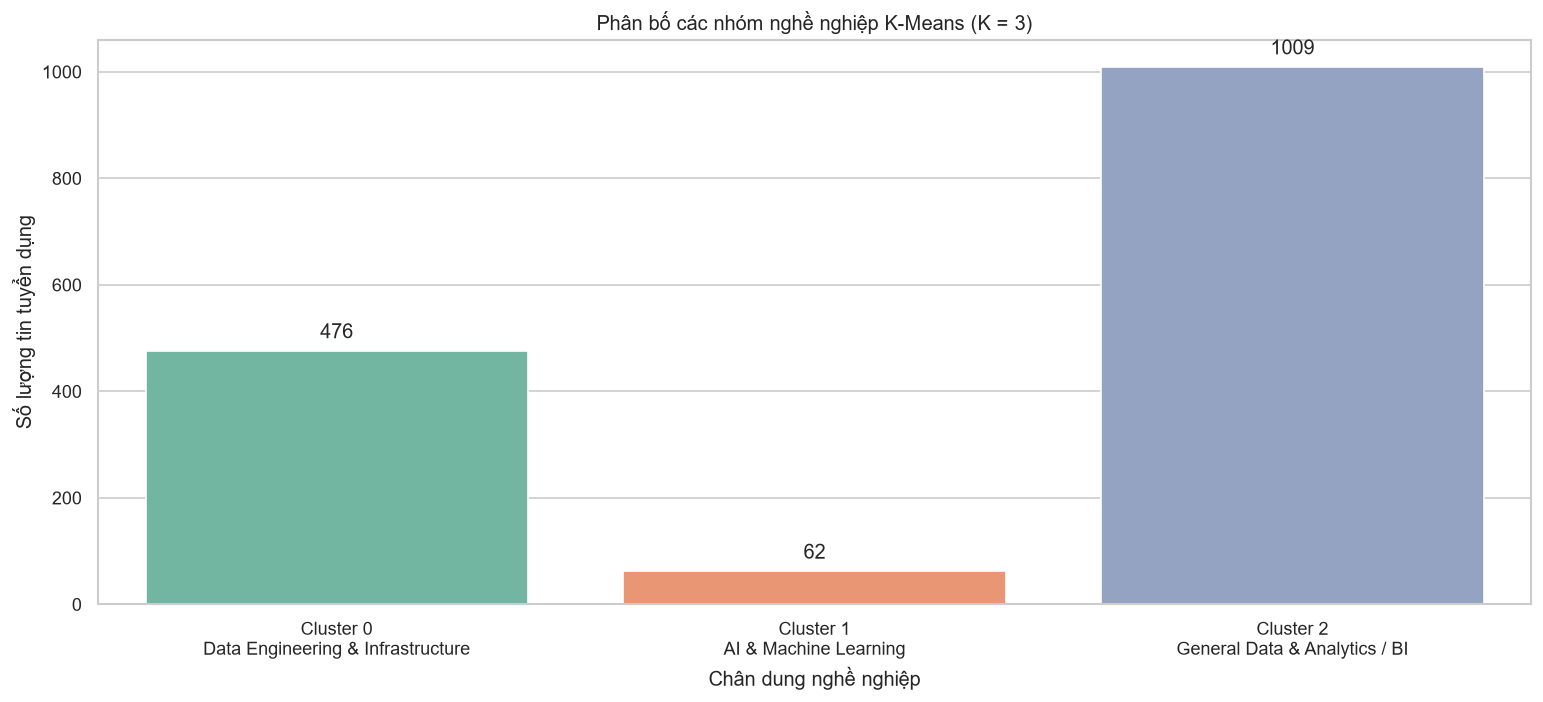

In [33]:
# Đặt tên chân dung cụm DỰA TRÊN ĐẶC TRƯNG KỸ NĂNG THỰC TẾ (tránh gán nhãn ngược)
_profiles_tmp = df_cluster.groupby("Cluster")[skill_cols].mean()
cluster_names = {}
for cid in sorted(df_cluster["Cluster"].unique()):
    ml_rate = _profiles_tmp.loc[cid, "Skill_Machine_Learning"]
    k8s_rate = _profiles_tmp.loc[cid, "Skill_Kubernetes"] + _profiles_tmp.loc[cid, "Skill_Docker"]
    if ml_rate >= 0.50:
        cluster_names[cid] = "AI & Machine Learning"
    elif k8s_rate >= 0.50:
        cluster_names[cid] = "Data Engineering & Infrastructure"
    else:
        cluster_names[cid] = "General Data & Analytics / BI"

print("Ánh xạ tên cụm theo hồ sơ kỹ năng thực tế:", cluster_names)
df_cluster["Cluster_Name"] = df_cluster["Cluster"].map(cluster_names)

plt.figure(figsize=(13, 6))
ax = sns.countplot(
    data=df_cluster,
    x="Cluster",
    hue="Cluster",
    palette="Set2",
    order=sorted(cluster_names.keys()),
    legend=False
)
for container in ax.containers:
    ax.bar_label(container, padding=5)

ax.set_xticks(sorted(cluster_names.keys()))
ax.set_xticklabels([f"Cluster {i}\n{cluster_names[i]}" for i in sorted(cluster_names.keys())])
plt.title("Phân bố các nhóm nghề nghiệp K-Means (K = 3)")
plt.xlabel("Chân dung nghề nghiệp")
plt.ylabel("Số lượng tin tuyển dụng")
plt.tight_layout()
plt.show()

### 2.3.7. Trực quan hóa kết quả phân cụm bằng PCA

Sử dụng PCA để giảm số chiều dữ liệu từ 60 xuống 2,
qua đó quan sát sự phân bố và mức độ tách biệt
giữa ba cụm nghề nghiệp.

In [34]:
# Giảm dữ liệu xuống 2 chiều
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Lưu tọa độ PCA
df_cluster["PCA1"] = X_pca[:, 0]
df_cluster["PCA2"] = X_pca[:, 1]

# Kiểm tra tỷ lệ phương sai được giữ lại
print(
    "Tỷ lệ phương sai giữ lại:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Tỷ lệ phương sai giữ lại: 17.29 %


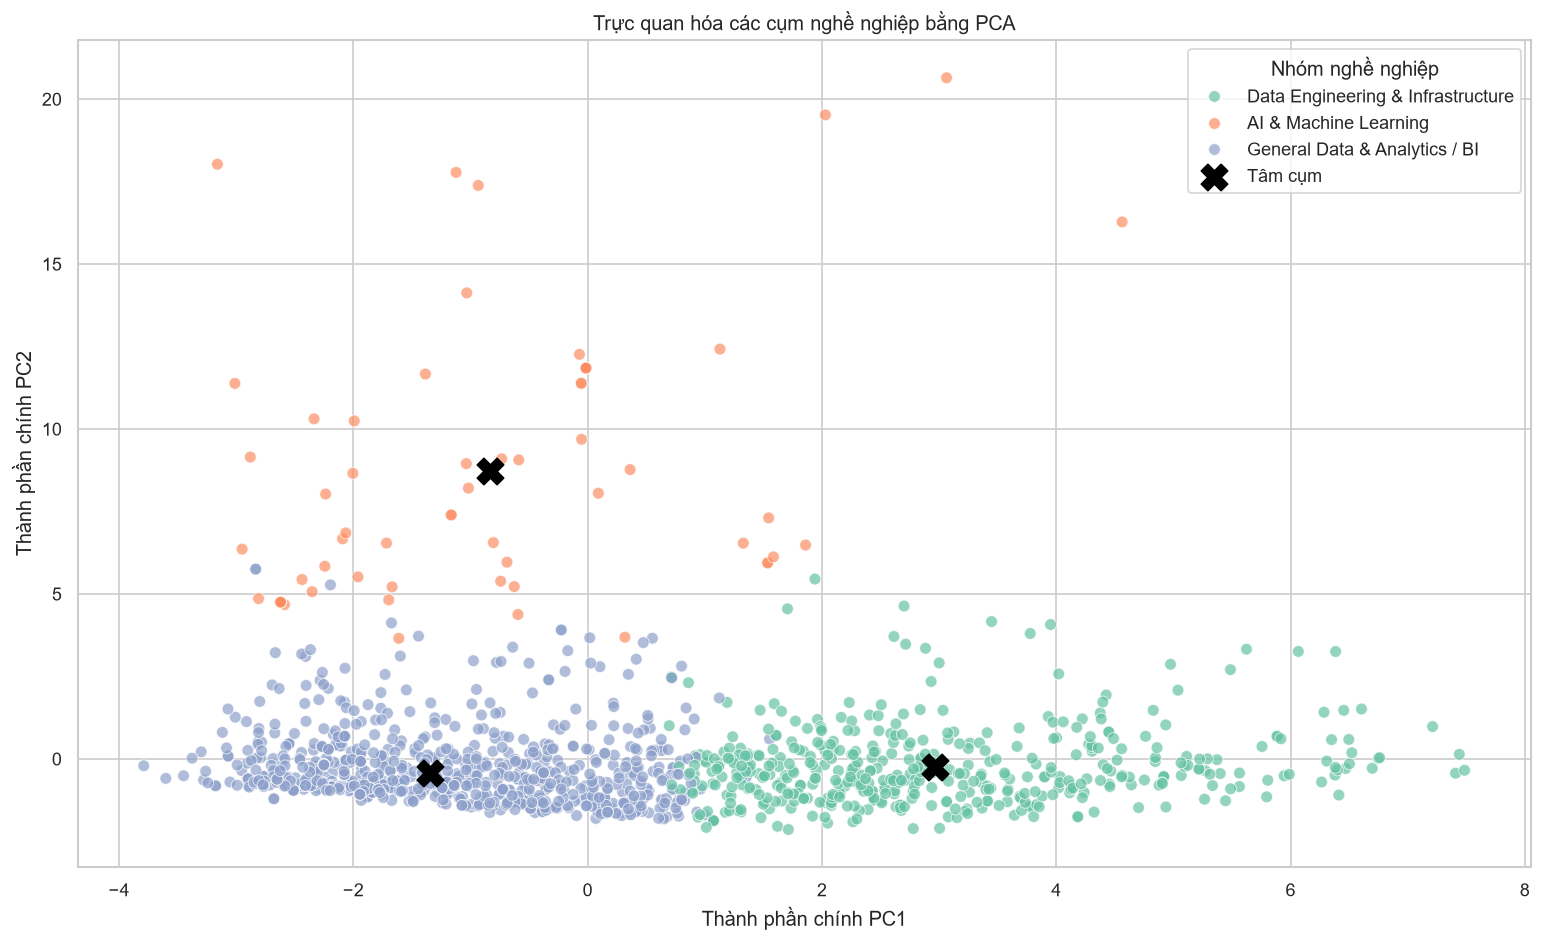

In [35]:
plt.figure(figsize=(13, 8))

sns.scatterplot(
    data=df_cluster,
    x="PCA1",
    y="PCA2",
    hue="Cluster_Name",
    palette="Set2",
    alpha=0.7,
    s=50
)

# Chiếu tâm cụm xuống không gian PCA
centers_pca = pca.transform(
    kmeans_final.cluster_centers_
)

plt.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    c="black",
    marker="X",
    s=250,
    label="Tâm cụm"
)

plt.title("Trực quan hóa các cụm nghề nghiệp bằng PCA")
plt.xlabel("Thành phần chính PC1")
plt.ylabel("Thành phần chính PC2")
plt.legend(title="Nhóm nghề nghiệp")
plt.tight_layout()
plt.show()

Dấu X màu đen biểu diễn tâm cụm (Centroid) sau khi chiếu xuống không gian PCA.
#### Nhận xét kết quả phân cụm PCA

- K-Means với K = 3 đã phân chia dữ liệu tuyển dụng
  thành ba cụm có sự khác biệt về vị trí trong không gian PCA.
- Cụm màu cam phân tách chủ yếu theo thành phần PC2
  và có độ phân tán tương đối lớn.
- Hai cụm xanh lá và xanh tím phân tách chủ yếu theo
  thành phần PC1, tuy nhiên vẫn tồn tại sự chồng lấn.
- Sự chồng lấn có thể liên quan đến các kỹ năng chung
  giữa những nhóm nghề nghiệp.
- Kết quả PCA cần được kết hợp với Silhouette Score
  và đặc trưng kỹ năng để đánh giá chất lượng phân cụm.

### 2.3.8. Phân tích chân dung nghề nghiệp

Phân tích tỷ lệ xuất hiện của các kỹ năng trong từng cụm
để xác định đặc điểm nổi bật và đặt tên nhóm nghề nghiệp
dựa trên kết quả phân cụm thực tế.

In [36]:
cluster_profiles = (
    df_cluster.groupby("Cluster")[skill_cols]
    .mean() * 100
)

cluster_profiles.columns = (
    cluster_profiles.columns.str.replace("Skill_", "")
)

cluster_profiles.round(2)

,Python,SQL,R,Scala,Java,C_Cpp,JavaScript,Bash_Shell,PowerBI,Tableau,Looker,Excel,Statistics,AB_Testing,Data_Storytelling,Spark,Hadoop,Kafka,Airflow,dbt,ETL,Data_Warehouse,Data_Lake,Data_Modeling,Machine_Learning,Deep_Learning,Pandas,NumPy,Scikit_Learn,PyTorch,TensorFlow,NLP,Computer_Vision,LLM_GenAI,MLOps,PostgreSQL,MySQL,SQL_Server,Oracle,MongoDB,Redis,Elasticsearch,BigQuery,Snowflake,Databricks,Redshift,Cloud_AWS,Cloud_Azure,Cloud_GCP,Docker,Kubernetes,Git,Linux,CI_CD,English,Communication,Problem_Solving,Teamwork,Agile_Scrum,Data_Governance
Cluster,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,42.02,80.67,0.42,3.15,42.23,3.15,39.50,16.60,1.68,0.63,1.89,1.47,3.99,0.84,7.77,7.14,4.20,37.18,13.87,2.10,11.13,5.88,5.25,16.18,8.61,0.42,0.21,0.0,0.00,0.00,0.00,0.00,1.26,15.97,4.20,54.62,40.34,22.06,24.37,42.23,33.61,19.54,4.83,2.52,1.26,2.52,44.12,29.20,28.78,60.08,47.69,52.94,26.68,65.76,50.00,42.86,28.99,28.15,23.32,16.81
1,85.48,29.03,0.00,0.00,9.68,27.42,3.23,3.23,1.61,1.61,1.61,6.45,17.74,12.90,17.74,6.45,3.23,1.61,6.45,0.00,3.23,0.00,1.61,1.61,91.94,85.48,19.35,12.9,19.35,72.58,64.52,53.23,70.97,59.68,35.48,11.29,8.06,3.23,3.23,16.13,1.61,1.61,0.00,0.00,1.61,0.00,14.52,14.52,11.29,45.16,27.42,45.16,8.06,29.03,27.42,17.74,30.65,12.90,6.45,19.35
2,29.73,49.45,1.98,0.40,8.03,1.39,10.51,1.59,16.35,5.65,3.17,10.90,12.69,2.18,21.41,2.28,0.79,3.96,2.78,1.19,10.70,8.33,2.58,7.93,14.57,1.78,0.59,0.2,0.00,0.50,0.20,2.08,2.18,14.37,1.59,8.92,7.63,11.30,13.08,3.87,0.89,0.30,1.29,1.29,0.89,0.40,8.13,6.14,2.48,2.08,1.39,6.34,5.25,9.02,28.54,29.14,16.35,13.28,9.22,21.11


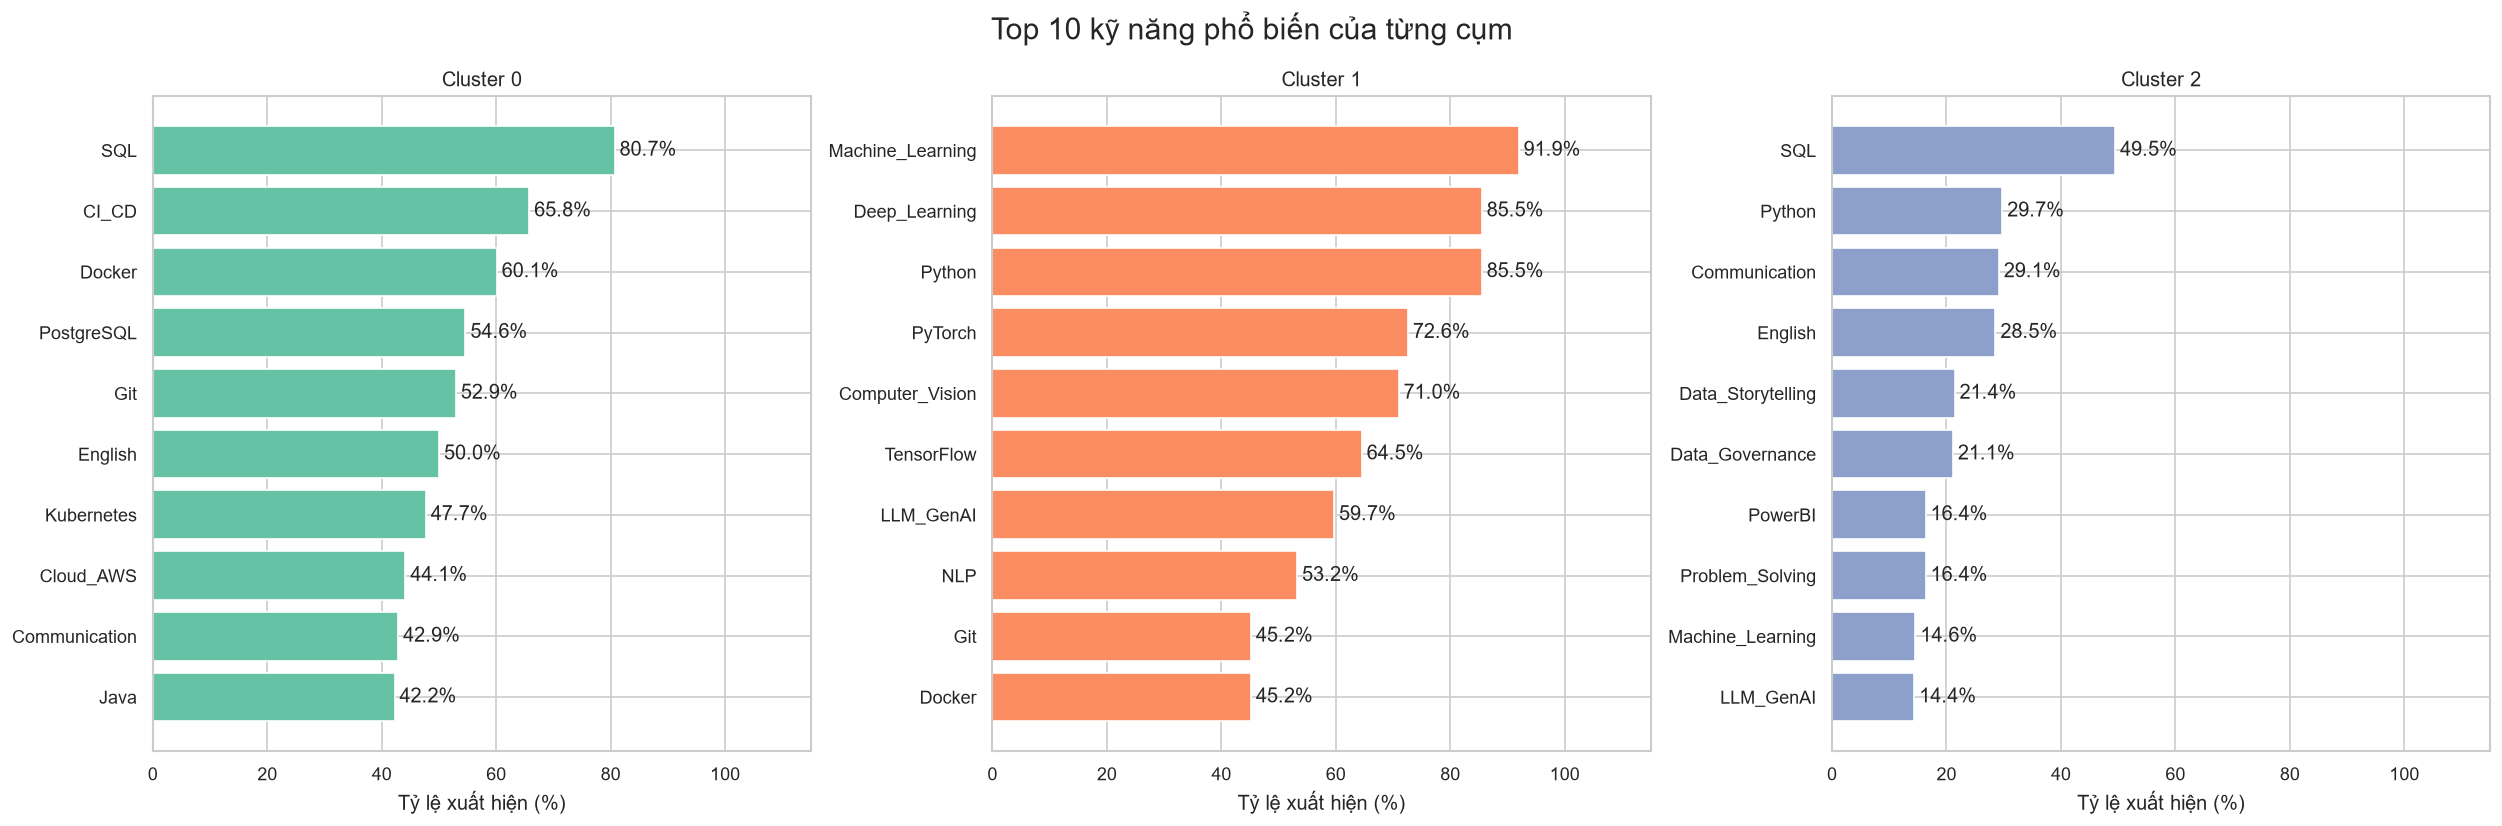

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(21, 7))

colors = sns.color_palette("Set2", 3)

for i, ax in enumerate(axes):

    top_skills = (
        cluster_profiles.loc[i]
        .sort_values(ascending=False)
        .head(10)
        .sort_values()
    )

    bars = ax.barh(
        top_skills.index,
        top_skills.values,
        color=colors[i]
    )

    ax.bar_label(bars, fmt="%.1f%%", padding=3)

    ax.set_title(f"Cluster {i}")
    ax.set_xlabel("Tỷ lệ xuất hiện (%)")
    ax.set_xlim(0, 115)

plt.suptitle(
    "Top 10 kỹ năng phổ biến của từng cụm",
    fontsize=18
)

plt.tight_layout()
plt.show()

In [38]:
# Đối chiếu nhãn cụm K-Means với nhãn Nhom_Nganh_Data gốc (tỷ lệ % theo từng cụm)
cluster_jobs = pd.crosstab(df_cluster["Nhom_Nganh_Data"], df_cluster["Cluster_Name"], normalize="columns") * 100
print("📊 Bảng đối chiếu thành phần Nhóm ngành gốc trong từng Cụm (%):")
display(cluster_jobs.round(2))

📊 Bảng đối chiếu thành phần Nhóm ngành gốc trong từng Cụm (%):


Cluster_Name,AI & Machine Learning,Data Engineering & Infrastructure,General Data & Analytics / BI
Nhom_Nganh_Data,,,
Data Analyst / BI,0.0,0.63,29.04
Data Engineer / Big Data,0.0,30.88,13.68
Data Scientist / AI & ML,100.0,11.34,19.03
Data-Driven Software Engineer,0.0,0.42,12.69
Database / Data Platform & Ops,0.0,56.72,25.57


## 2.4. Khai phá luật kết hợp (Association Rules)

### 2.4.1. Chuẩn bị dữ liệu

Sử dụng thuật toán Apriori để khai phá các tập kỹ năng
phổ biến và luật kết hợp giữa các kỹ năng tuyển dụng.
Đánh giá các luật bằng Support, Confidence và Lift.

In [39]:
from mlxtend.frequent_patterns import (
    apriori,
    fpgrowth,
    association_rules
)

In [40]:
# Lấy các cột kỹ năng
transactions = df[skill_cols].copy()

# Chuyển dữ liệu 0/1 thành False/True
transactions = transactions.astype(bool)

# Loại bỏ tiền tố Skill_
transactions.columns = (
    transactions.columns.str.replace("Skill_", "")
)

print("Số giao dịch:", len(transactions))
print("Số kỹ năng:", len(transactions.columns))

transactions.head()

Số giao dịch: 1547
Số kỹ năng: 60


,Python,SQL,R,Scala,Java,C_Cpp,JavaScript,Bash_Shell,PowerBI,Tableau,Looker,Excel,Statistics,AB_Testing,Data_Storytelling,Spark,Hadoop,Kafka,Airflow,dbt,ETL,Data_Warehouse,Data_Lake,Data_Modeling,Machine_Learning,Deep_Learning,Pandas,NumPy,Scikit_Learn,PyTorch,TensorFlow,NLP,Computer_Vision,LLM_GenAI,MLOps,PostgreSQL,MySQL,SQL_Server,Oracle,MongoDB,Redis,Elasticsearch,BigQuery,Snowflake,Databricks,Redshift,Cloud_AWS,Cloud_Azure,Cloud_GCP,Docker,Kubernetes,Git,Linux,CI_CD,English,Communication,Problem_Solving,Teamwork,Agile_Scrum,Data_Governance
0,True,True,False,True,False,False,False,False,True,True,True,False,False,False,True,True,True,True,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True,True,False,True,True,True,True,True,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,True,False
1,True,True,False,False,False,False,False,False,False,False,True,False,False,False,True,True,False,True,True,True,True,True,True,True,False,False,False,False,False,False,False,False,False,True,True,True,False,True,False,True,True,False,False,False,True,False,True,False,False,True,True,False,False,True,True,False,False,False,False,True
2,True,True,False,True,True,False,False,False,False,False,False,False,True,False,True,True,True,True,False,True,True,True,True,False,False,False,False,False,False,False,False,False,False,False,False,True,True,False,False,True,True,False,True,True,False,True,True,True,True,False,False,False,False,False,False,False,False,False,False,True
3,True,True,False,False,False,False,False,True,True,True,True,False,False,False,True,False,False,True,True,True,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,True,True,True,False,True,True,True,True,True,False,False,False,False,False,True,True,True,True,False,False,True,False,False,False,True
4,True,True,False,False,False,False,False,False,False,False,False,False,False,False,True,True,True,True,True,True,True,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,True,False,False,False,False,True,False,True,True,True,False,False,False,False,True,True,True,True,True,True,True


### 2.4.2. Khai phá tập kỹ năng phổ biến bằng Apriori

In [41]:
frequent_itemsets = apriori(
    transactions,
    min_support=0.05,
    use_colnames=True
)

frequent_itemsets["Length"] = (
    frequent_itemsets["itemsets"].apply(len)
)

print("Số tập kỹ năng phổ biến:", len(frequent_itemsets))

frequent_itemsets.sort_values(
    "support",
    ascending=False
).head(20)

Số tập kỹ năng phổ biến: 472


,support,itemsets,Length
1,0.582418,frozenset({SQL}),1
0,0.357466,frozenset({Python}),1
31,0.351002,frozenset({English}),1
32,0.329024,frozenset({Communication}),1
30,0.272786,frozenset({CI_CD}),1
89,0.234648,"frozenset({Communication, SQL})",2
88,0.233355,"frozenset({SQL, English})",2
37,0.231416,"frozenset({Python, SQL})",2
16,0.230769,frozenset({PostgreSQL}),1
74,0.229476,"frozenset({PostgreSQL, SQL})",2


### 2.4.3. Sinh luật kết hợp giữa các kỹ năng

Sinh các luật kết hợp từ tập kỹ năng phổ biến
với Confidence tối thiểu 60%.
Đánh giá luật thông qua Support, Confidence và Lift.

In [42]:
# Sinh luật kết hợp (bao gồm đầy đủ 4 độ đo: Support, Confidence, Lift, Conviction)
rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=0.6
)

print("Tổng số luật kết hợp (Confidence >= 0.60):", len(rules))

# Hiển thị 20 luật có Lift cao nhất kèm Conviction
rules[
    ["antecedents", "consequents", "support", "confidence", "lift", "conviction"]
].sort_values("lift", ascending=False).head(20).round(4)

Tổng số luật kết hợp (Confidence >= 0.60): 440


,antecedents,consequents,support,confidence,lift,conviction
253,"frozenset({Cloud_AWS, Cloud_Azure})",frozenset({Cloud_GCP}),0.0692,0.7431,6.8018,3.4667
254,frozenset({Cloud_GCP}),"frozenset({Cloud_AWS, Cloud_Azure})",0.0692,0.6331,6.8018,2.4721
383,"frozenset({Docker, MongoDB})","frozenset({SQL, Kubernetes})",0.0530,0.6560,5.8324,2.5800
251,"frozenset({Cloud_GCP, Cloud_AWS})",frozenset({Cloud_Azure}),0.0692,0.7754,5.7118,3.8473
348,"frozenset({PostgreSQL, Docker})","frozenset({SQL, Kubernetes})",0.0646,0.6329,5.6271,2.4177
349,"frozenset({PostgreSQL, Kubernetes})","frozenset({Docker, SQL})",0.0646,0.8475,5.4626,5.5385
382,"frozenset({MongoDB, Kubernetes})","frozenset({Docker, SQL})",0.0530,0.8454,5.4491,5.4634
252,"frozenset({Cloud_GCP, Cloud_Azure})",frozenset({Cloud_AWS}),0.0692,0.9907,5.0919,86.9864
425,"frozenset({Docker, Cloud_AWS})","frozenset({CI_CD, Kubernetes})",0.0556,0.6187,4.9851,2.2971
436,"frozenset({Git, Kubernetes})","frozenset({Docker, CI_CD})",0.0666,0.7574,4.8818,3.4819


### 2.4.4. Lọc các luật kết hợp mạnh

Lựa chọn các luật kết hợp thỏa mãn:
- Support >= 0.05
- Confidence >= 0.60
- Lift > 1.2

In [43]:
strong_rules = rules.loc[
    (rules["support"] >= 0.05) &
    (rules["confidence"] >= 0.60) &
    (rules["lift"] > 1.2)
].copy()

strong_rules = strong_rules.sort_values("lift", ascending=False)

# Phát hiện các luật gây nhiễu / bẫy độ tin cậy (Confidence >= 0.60 nhưng Lift <= 1.2)
trap_rules = rules.loc[
    (rules["support"] >= 0.05) &
    (rules["confidence"] >= 0.60) &
    (rules["lift"] <= 1.2)
].sort_values("confidence", ascending=False).copy()

print("Tổng số luật ban đầu (Confidence >= 0.60):", len(rules))
print("Số luật kết hợp mạnh (Lift > 1.2):", len(strong_rules))
print("Số luật nhiễu / bẫy độ tin cậy (Confidence >= 0.60 nhưng Lift <= 1.2):", len(trap_rules))
print("Tỷ lệ luật mạnh được giữ lại:", round(len(strong_rules) / len(rules) * 100, 2), "%")

print("\n📌 Top 10 Luật nhiễu / Bẫy độ tin cậy (Confidence cao nhưng Lift <= 1.2, Conviction thấp):")
trap_disp = trap_rules[["antecedents", "consequents", "support", "confidence", "lift", "conviction"]].head(10).copy()
trap_disp["antecedents"] = trap_disp["antecedents"].apply(lambda x: ", ".join(sorted(x)))
trap_disp["consequents"] = trap_disp["consequents"].apply(lambda x: ", ".join(sorted(x)))
display(trap_disp.round(4))

print("\n🏆 Top 15 Luật kết hợp mạnh (Support >= 0.05, Confidence >= 0.60, Lift > 1.2):")
strong_rules[
    ["antecedents", "consequents", "support", "confidence", "lift", "conviction"]
].head(15).round(4)

Tổng số luật ban đầu (Confidence >= 0.60): 440
Số luật kết hợp mạnh (Lift > 1.2): 408
Số luật nhiễu / bẫy độ tin cậy (Confidence >= 0.60 nhưng Lift <= 1.2): 32
Tỷ lệ luật mạnh được giữ lại: 92.73 %

📌 Top 10 Luật nhiễu / Bẫy độ tin cậy (Confidence cao nhưng Lift <= 1.2, Conviction thấp):

🏆 Top 15 Luật kết hợp mạnh (Support >= 0.05, Confidence >= 0.60, Lift > 1.2):


,antecedents,consequents,support,confidence,lift,conviction
393,"Docker, Git, Kubernetes",SQL,0.0537,0.6975,1.1976,1.3803
175,"Docker, Kubernetes",SQL,0.0963,0.6963,1.1955,1.3748
172,"CI_CD, Cloud_Azure",SQL,0.0562,0.6960,1.1950,1.3736
192,"CI_CD, English",SQL,0.0834,0.6935,1.1908,1.3626
199,"English, Teamwork",SQL,0.0621,0.6906,1.1858,1.3499
205,"Communication, Data_Governance",SQL,0.0633,0.6901,1.1850,1.3477
62,"Communication, Python",SQL,0.0944,0.6887,1.1824,1.3413
197,"Communication, English",SQL,0.1364,0.6873,1.1801,1.3354
8,Data_Storytelling,SQL,0.1170,0.6856,1.1772,1.3282
183,"Git, Kubernetes",SQL,0.0601,0.6838,1.1741,1.3207


,antecedents,consequents,support,confidence,lift,conviction
253,"frozenset({Cloud_AWS, Cloud_Azure})",frozenset({Cloud_GCP}),0.0692,0.7431,6.8018,3.4667
254,frozenset({Cloud_GCP}),"frozenset({Cloud_AWS, Cloud_Azure})",0.0692,0.6331,6.8018,2.4721
383,"frozenset({Docker, MongoDB})","frozenset({SQL, Kubernetes})",0.0530,0.6560,5.8324,2.5800
251,"frozenset({Cloud_GCP, Cloud_AWS})",frozenset({Cloud_Azure}),0.0692,0.7754,5.7118,3.8473
348,"frozenset({PostgreSQL, Docker})","frozenset({SQL, Kubernetes})",0.0646,0.6329,5.6271,2.4177
349,"frozenset({PostgreSQL, Kubernetes})","frozenset({Docker, SQL})",0.0646,0.8475,5.4626,5.5385
382,"frozenset({MongoDB, Kubernetes})","frozenset({Docker, SQL})",0.0530,0.8454,5.4491,5.4634
252,"frozenset({Cloud_GCP, Cloud_Azure})",frozenset({Cloud_AWS}),0.0692,0.9907,5.0919,86.9864
425,"frozenset({Docker, Cloud_AWS})","frozenset({CI_CD, Kubernetes})",0.0556,0.6187,4.9851,2.2971
436,"frozenset({Git, Kubernetes})","frozenset({Docker, CI_CD})",0.0666,0.7574,4.8818,3.4819


In [44]:
rules_display = strong_rules[
    ["antecedents", "consequents", "support", "confidence", "lift", "conviction"]
].copy()

rules_display["antecedents"] = rules_display["antecedents"].apply(lambda x: ", ".join(sorted(x)))
rules_display["consequents"] = rules_display["consequents"].apply(lambda x: ", ".join(sorted(x)))
rules_display.head(20).round(4)

,antecedents,consequents,support,confidence,lift,conviction
253,"Cloud_AWS, Cloud_Azure",Cloud_GCP,0.0692,0.7431,6.8018,3.4667
254,Cloud_GCP,"Cloud_AWS, Cloud_Azure",0.0692,0.6331,6.8018,2.4721
383,"Docker, MongoDB","Kubernetes, SQL",0.0530,0.6560,5.8324,2.5800
251,"Cloud_AWS, Cloud_GCP",Cloud_Azure,0.0692,0.7754,5.7118,3.8473
348,"Docker, PostgreSQL","Kubernetes, SQL",0.0646,0.6329,5.6271,2.4177
349,"Kubernetes, PostgreSQL","Docker, SQL",0.0646,0.8475,5.4626,5.5385
382,"Kubernetes, MongoDB","Docker, SQL",0.0530,0.8454,5.4491,5.4634
252,"Cloud_Azure, Cloud_GCP",Cloud_AWS,0.0692,0.9907,5.0919,86.9864
425,"Cloud_AWS, Docker","CI_CD, Kubernetes",0.0556,0.6187,4.9851,2.2971
436,"Git, Kubernetes","CI_CD, Docker",0.0666,0.7574,4.8818,3.4819


### 2.4.5. Trực quan hóa các luật kết hợp mạnh

So sánh các luật kết hợp thông qua Lift, Support
và Confidence nhằm xác định những tổ hợp kỹ năng
có mức độ liên kết cao.

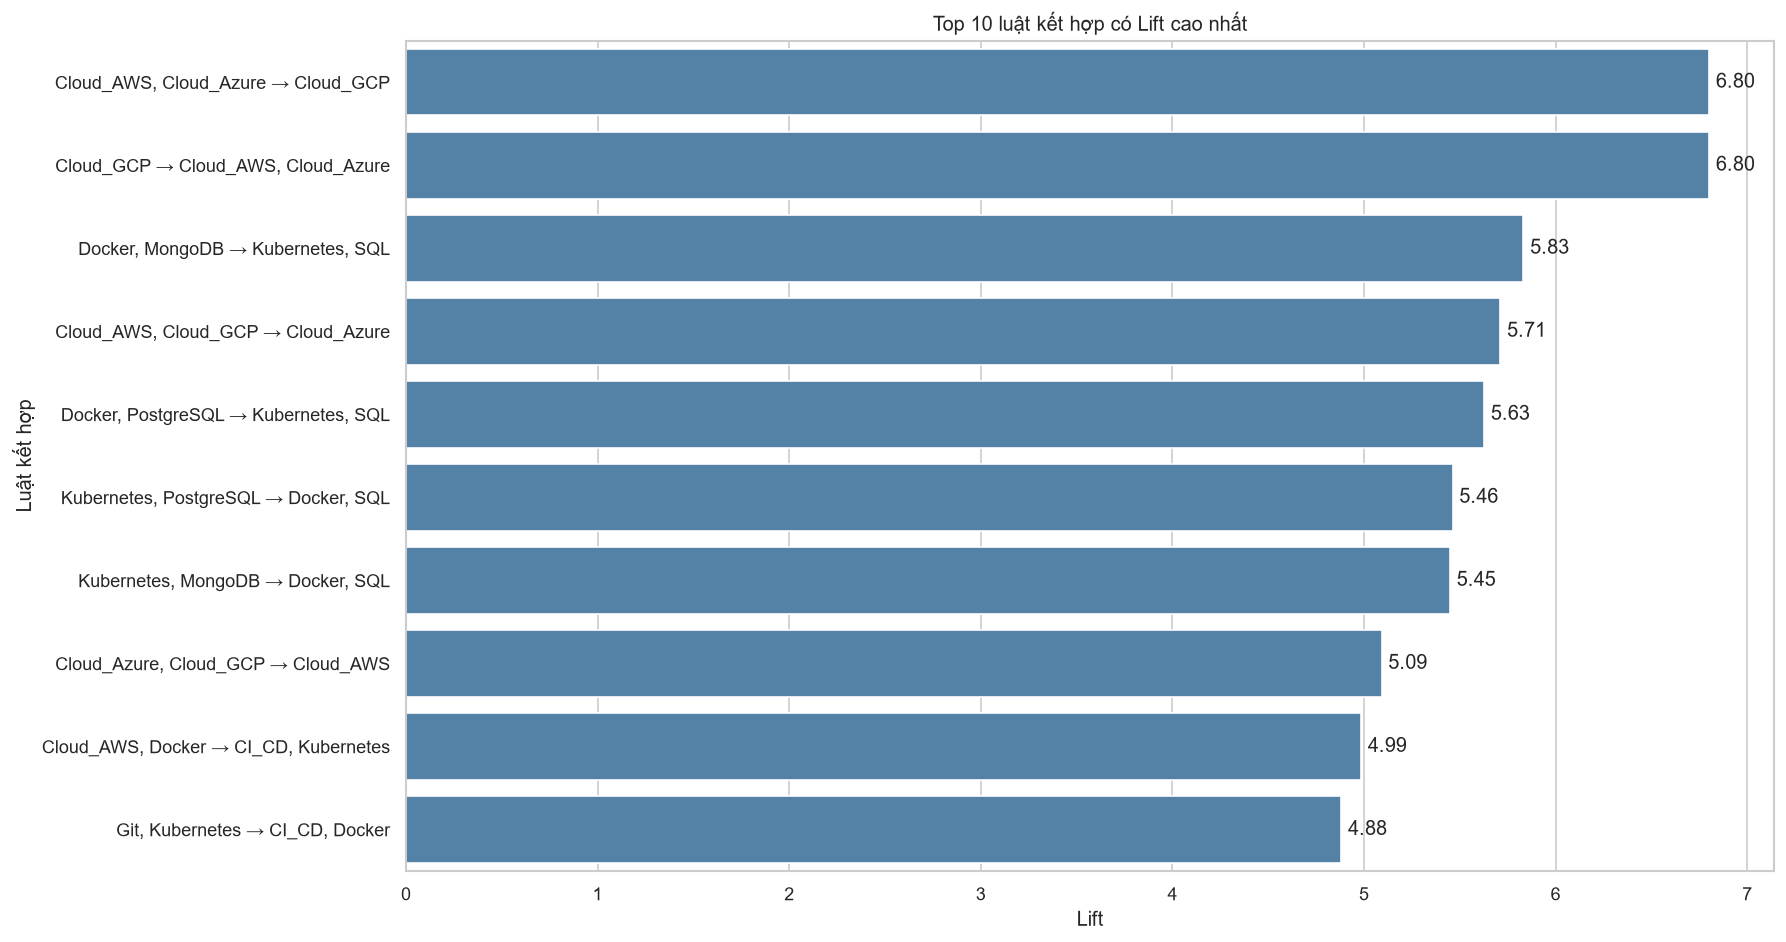

In [45]:
top_rules = rules_display.head(10).copy()

top_rules["Rule"] = (
    top_rules["antecedents"]
    + " → "
    + top_rules["consequents"]
)

plt.figure(figsize=(15, 8))

ax = sns.barplot(
    data=top_rules,
    x="lift",
    y="Rule",
    color="steelblue"
)

ax.bar_label(
    ax.containers[0],
    fmt="%.2f",
    padding=4
)

plt.title("Top 10 luật kết hợp có Lift cao nhất")
plt.xlabel("Lift")
plt.ylabel("Luật kết hợp")
plt.tight_layout()
plt.show()

#### Nhận xét
- Các luật có Lift cao chủ yếu liên quan đến Cloud và DevOps.
- Luật AWS + Azure → GCP có Lift đạt 6,80, cho thấy mối liên kết mạnh giữa các nền tảng Cloud.
- Docker, Kubernetes và hệ quản trị cơ sở dữ liệu có xu hướng xuất hiện cùng nhau.

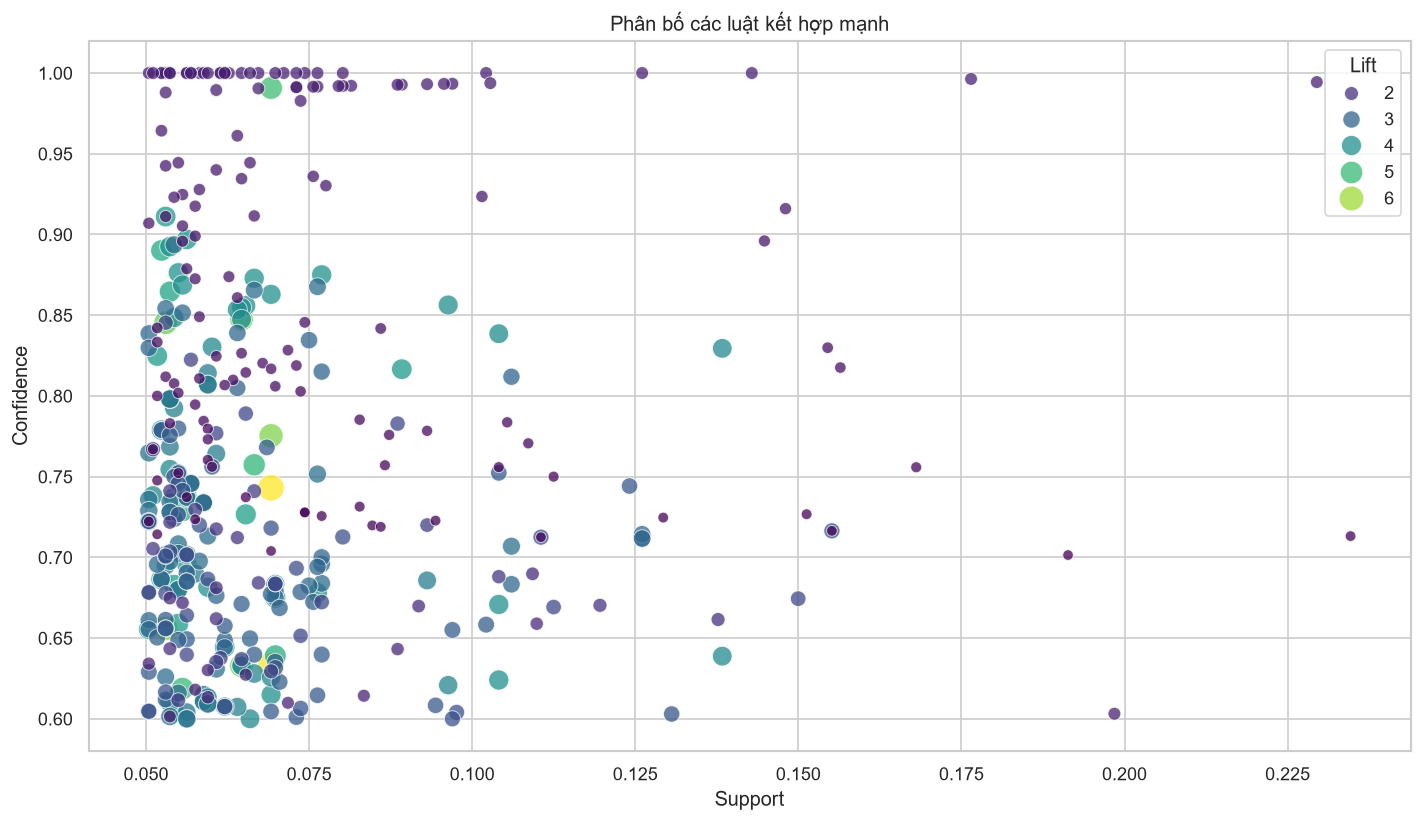

In [46]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=strong_rules,
    x="support",
    y="confidence",
    hue="lift",
    size="lift",
    palette="viridis",
    sizes=(40, 250),
    alpha=0.75
)

plt.title("Phân bố các luật kết hợp mạnh")
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.legend(title="Lift")
plt.tight_layout()
plt.show()


#### Nhận xét
- Các luật được giữ lại có Support từ 5% và Confidence từ 60% trở lên.
- Các điểm có kích thước lớn và màu sắc nổi bật biểu thị những luật có Lift cao.
- Luật có Lift cao không nhất thiết có Support cao, cho thấy mức độ liên kết mạnh không đồng nghĩa với mức độ phổ biến lớn.
-> Kết quả khai phá luật kết hợp cho thấy các kỹ năng Cloud, DevOps và cơ sở dữ liệu có mối liên kết chặt chẽ. Đây là cơ sở tham khảo để xây dựng lộ trình học tập và phát triển kỹ năng nghề nghiệp trong ngành Data.

### 2.4.6. Kiểm chứng các luật kết hợp tiêu biểu

Kiểm chứng mức độ liên kết giữa các tổ hợp kỹ năng
thông qua Support, Confidence và Lift.

In [47]:
def evaluate_rule(antecedents, consequents):
    A = transactions[list(antecedents)].all(axis=1)
    B = transactions[list(consequents)].all(axis=1)

    support_A = A.mean()
    support_B = B.mean()
    support = (A & B).mean()
    confidence = support / support_A if support_A > 0 else 0.0
    lift = confidence / support_B if support_B > 0 else 0.0
    conviction = (1.0 - support_B) / (1.0 - confidence) if confidence < 1.0 else np.inf

    return {
        "Antecedents": ", ".join(antecedents),
        "Consequents": ", ".join(consequents),
        "Support": support,
        "Confidence": confidence,
        "Lift": lift,
        "Conviction": conviction
    }

In [48]:
target_rules = pd.DataFrame([
    evaluate_rule(
        ["Python", "SQL"],
        ["Machine_Learning"]
    ),
    evaluate_rule(
        ["Docker", "Kubernetes"],
        ["Cloud_AWS"]
    )
])

target_rules["Dat_Nguong"] = (
    (target_rules["Support"] >= 0.05) &
    (target_rules["Confidence"] >= 0.60) &
    (target_rules["Lift"] > 1.2)
)

target_rules.round(4)

,Antecedents,Consequents,Support,Confidence,Lift,Conviction,Dat_Nguong
0,"Python, SQL",Machine_Learning,0.0569,0.2458,1.5521,1.1159,False
1,"Docker, Kubernetes",Cloud_AWS,0.0653,0.4720,2.4257,1.5253,False


#### Nhận xét

- Luật Python + SQL → Machine Learning có Lift gần 1,
  cho thấy mối liên kết giữa các tập kỹ năng không đáng kể.
- Luật Docker + Kubernetes → Cloud AWS có Lift = 2,4257,
  thể hiện mối liên kết dương giữa DevOps và Cloud Computing.
- Cả hai luật chưa đáp ứng đồng thời các ngưỡng Support,
  Confidence và Lift đã lựa chọn.

## 3. Kết luận tổng thể

### Phân tích khám phá dữ liệu (EDA)
- Phân tích 1.547 tin tuyển dụng thuộc 5 nhóm ngành Data.
- Database / Data Platform & Ops có số lượng tin tuyển dụng cao nhất.
- Phân phối mức lương có xu hướng lệch phải.
- SQL và Python là hai kỹ năng phổ biến nhất.

### Phân cụm K-Means
- Phân cụm dữ liệu dựa trên 60 thuộc tính kỹ năng.
- Khảo sát số cụm bằng Elbow Method và Silhouette Score.
- Xây dựng mô hình K-Means với K = 3.
- Xác định ba chân dung nghề nghiệp:
  1. AI & Machine Learning.
  2. General Data & Analytics.
  3. Data Engineering & Infrastructure.

### Khai phá luật kết hợp
- Khai phá 480 tập kỹ năng phổ biến.
- Sinh 454 luật kết hợp với Confidence tối thiểu 60%.
- Lựa chọn các luật có Lift > 1.2.
- Phát hiện mối liên kết nổi bật giữa các kỹ năng
  Cloud Computing, DevOps và cơ sở dữ liệu.

### Hạn chế
- 74,73% tin tuyển dụng không công bố mức lương.
- Các cụm nghề nghiệp vẫn có sự giao thoa về kỹ năng.
- Luật kết hợp thể hiện sự đồng xuất hiện,
  không khẳng định quan hệ nhân quả.


# THÀNH VIÊN 3 – PHÂN LỚP DỮ LIỆU TUYỂN DỤNG

## Dự đoán mức lương dựa trên kỹ năng và kinh nghiệm

### Nội dung thực hiện

- 2.5. Phân lớp bằng Decision Tree và Random Forest
- 2.6. Đánh giá mô hình và rút trích luật phân lớp
- 3 Thảo luận, khuyến nghị và tổng hợp tri thức

**Nguồn dữ liệu:** clean_data.csv

**Mục tiêu:** Xây dựng mô hình dự đoán nhóm lương
của các vị trí tuyển dụng ngành Data dựa trên
60 kỹ năng và số năm kinh nghiệm.



In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)




## 2.5. Phân lớp bằng Decision Tree và Random Forest

### 2.5.1. Giới thiệu bài toán và kiểm tra dữ liệu

Bài toán nhằm dự đoán khoảng lương của các vị trí
tuyển dụng thuộc ngành Data dựa trên các yêu cầu
về kỹ năng chuyên môn và số năm kinh nghiệm.

Sử dụng hai thuật toán phân lớp:
- Decision Tree (Cây quyết định).
- Random Forest (Rừng ngẫu nhiên).

Nhãn phân lớp gồm ba nhóm:
- Dưới 15M.
- 15M - 30M.
- Trên 30M.

Trước khi huấn luyện, tiến hành kiểm tra cấu trúc,
kích thước và chất lượng dữ liệu đầu vào.


In [50]:
# Tìm data/clean_data.csv tự động (chạy mượt trên mọi máy Windows/macOS/Linux)
DATA_FILE = Path("data") / "clean_data.csv"
data_path = next(
    (base / DATA_FILE for base in (Path.cwd(), *Path.cwd().parents) if (base / DATA_FILE).exists()),
    None
)
if data_path is None:
    raise FileNotFoundError(f"Không tìm thấy {DATA_FILE}. Hãy chạy notebook trong thư mục dự án.")

df = pd.read_csv(data_path, encoding="utf-8-sig")

print("Đường dẫn dữ liệu:", data_path)
print("Số tin tuyển dụng:", df.shape[0])
print("Số thuộc tính:", df.shape[1])

skill_cols = [col for col in df.columns if col.startswith("Skill_")]
print("Số kỹ năng:", len(skill_cols))

required_cols = skill_cols + ["So_Nam_Kinh_Nghiem", "Khoang_Luong_Phan_Lop"]
print("Số giá trị thiếu trong các cột cần dùng:", df[required_cols].isna().sum().sum())
display(df.head())

Đường dẫn dữ liệu: c:\crawl data\data\clean_data.csv
Số tin tuyển dụng: 1547
Số thuộc tính: 86
Số kỹ năng: 60
Số giá trị thiếu trong các cột cần dùng: 0


,Job_ID,Site,Tieu_De,Cong_Ty,Nhom_Nganh_Data,Dia_Diem_Goc,Dia_Diem_Chuan,Hinh_Thuc_Lam_Viec_Goc,Mo_Hinh_Lam_Viec,Kinh_Nghiem_Goc,So_Nam_Kinh_Nghiem,Cap_Bac,Muc_Luong_Goc,Trang_Thai_Luong,Luong_Min,Luong_Max,Luong_Trung_Binh,Luong_Trung_Binh_Imputed,Khoang_Luong_Phan_Lop,Khoang_Luong_Thuc,Danh_Sach_Ky_Nang,So_Luong_Ky_Nang,Mo_Ta_Cong_Viec,Mo_Ta_Lam_Sach,URL_Goc,Timestamp,Skill_Python,Skill_SQL,Skill_R,Skill_Scala,Skill_Java,Skill_C_Cpp,Skill_JavaScript,Skill_Bash_Shell,Skill_PowerBI,Skill_Tableau,Skill_Looker,Skill_Excel,Skill_Statistics,Skill_AB_Testing,Skill_Data_Storytelling,Skill_Spark,Skill_Hadoop,Skill_Kafka,Skill_Airflow,Skill_dbt,Skill_ETL,Skill_Data_Warehouse,Skill_Data_Lake,Skill_Data_Modeling,Skill_Machine_Learning,Skill_Deep_Learning,Skill_Pandas,Skill_NumPy,Skill_Scikit_Learn,Skill_PyTorch,Skill_TensorFlow,Skill_NLP,Skill_Computer_Vision,Skill_LLM_GenAI,Skill_MLOps,Skill_PostgreSQL,Skill_MySQL,Skill_SQL_Server,Skill_Oracle,Skill_MongoDB,Skill_Redis,Skill_Elasticsearch,Skill_BigQuery,Skill_Snowflake,Skill_Databricks,Skill_Redshift,Skill_Cloud_AWS,Skill_Cloud_Azure,Skill_Cloud_GCP,Skill_Docker,Skill_Kubernetes,Skill_Git,Skill_Linux,Skill_CI_CD,Skill_English,Skill_Communication,Skill_Problem_Solving,Skill_Teamwork,Skill_Agile_Scrum,Skill_Data_Governance
0,DATA_0001,topcv,Chuyên Viên Dữ Liệu Lớn (Big Data),ProNgân hàng TMCP Đông Nam Á - SEABANK,Data Engineer / Big Data,Hà Nội,Hà Nội,On-site (Toàn thời gian),On-site,1 năm,1.0,Junior,Thoả thuận,Thoa_Thuan,NaN,NaN,NaN,18.50,15M - 30M,NaN,Python; SQL; Scala; PowerBI; Tableau; Looker; Data_Storytelling; Spark; Hado...,21,"## Company\n\nSoutheast Asia Commercial Joint Stock Bank (SeABank, Ngân hàng...",## company southeast asia commercial joint stock bank seabank ngân hàng tmcp...,https://www.topcv.vn/viec-lam/chuyen-vien-du-lieu-lon-big-data/1037081.html,2026-11-13 10:45:00,1,1,0,1,0,0,0,0,1,1,1,0,0,0,1,1,1,1,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,1,1,1,1,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0
1,DATA_0002,topdev,DATA ENGINEER / DATA PLATFORM ENGINEER,CÔNG TY TNHH AZIWORLD,Data Engineer / Big Data,Việt Nam,Khác,On-site (Toàn thời gian),On-site,3 years of experience,3.0,Middle,Login to view salary,Thoa_Thuan,NaN,NaN,NaN,23.90,15M - 30M,NaN,Python; SQL; Looker; Data_Storytelling; Spark; Kafka; Airflow; dbt; ETL; Dat...,25,## Company\n\nAzIWorld Company Limited (CÔNG TY TNHH AZIWORLD) is a Vietname...,## company aziworld company limited tnhh aziworld vietnamese technology comp...,https://topdev.vn/detail-jobs/data-engineer-data-platform-engineer-cong-ty-t...,2026-10-17 09:00:00,1,1,0,0,0,0,0,0,0,0,1,0,0,0,1,1,0,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,1,1,1,0,1,0,1,1,0,0,0,1,0,1,0,0,1,1,0,0,1,1,0,0,0,0,1
2,DATA_0003,topcv,Lead Data Engineer,CÔNG TY CỔ PHẦN CÔNG NGHỆ SICIX,Data Engineer / Big Data,Hà Nội,Hà Nội,On-site (Toàn thời gian),On-site,3 năm,6.0,Lead,20 - 40 triệu,Co_Cong_Bo,20.0,40.0,30.00,30.00,15M - 30M,15M - 30M,Python; SQL; Scala; Java; Statistics; Data_Storytelling; Spark; Hadoop; Kafk...,24,## Company\n\nSICIX Technology Joint Stock Company (CÔNG TY CỔ PHẦN CÔNG NGH...,## company sicix technology joint stock company cổ phần nghệ sicix computer ...,https://www.topcv.vn/viec-lam/lead-data-engineer/2314150.html,2026-11-13 10:45:00,1,1,0,1,1,0,0,0,0,0,0,0,1,0,1,1,1,1,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,1,1,0,1,1,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,1
3,DATA_0004,vietnamworks,Database Administrator,Navigos Group,Database / Data Platform & Ops,Hồ Chí Minh,TP.HCM,On-site (Toàn thời gian),On-site,Experienced (non-manager),2.5,Middle,"$ 1,000-1,500 /tháng",Co_Cong_Bo,25.4,38.1,31.75,31.75,Trên 30M,Trên 30M,Python; SQL; Bash_Shell; PowerBI; Tableau; Looker; Data_Storytelling; Kafka;...,26,## Company\n\nNavigos Group is a technology company that operates platforms ...,## company navigos group technology company operates platforms including vie...,https://www.vietnamworks.com/database-administrator-1792742505409532145-2123...,2026-10-23 08:01:45,1,1,0,0,0,0,0,1,1,1,1,0,0,0,1,0,0,1,1,1,0,


#### Nhận xét

- Bộ dữ liệu gồm 1.547 tin tuyển dụng và 85 thuộc tính.
- Có 60 thuộc tính kỹ năng được mã hóa dưới dạng
  nhị phân (0 và 1).
- Thuộc tính So_Nam_Kinh_Nghiem biểu diễn số năm
  kinh nghiệm được yêu cầu trong tin tuyển dụng.
- Khoang_Luong_Phan_Lop là nhãn cần dự đoán,
  gồm ba nhóm mức lương.
- Các thuộc tính dự kiến sử dụng để huấn luyện
  không có giá trị thiếu.

**Kết luận:** Dữ liệu có đủ các thuộc tính cần thiết
để bước đầu xây dựng mô hình phân lớp.
Tuy nhiên, cần xem xét việc nội suy các mức lương
không được công bố trước khi đánh giá kết quả mô hình.



### 2.5.2. Chuẩn bị dữ liệu đầu vào X và nhãn y

Trong bài toán phân lớp, dữ liệu được chia thành
hai thành phần chính:

- **X (Features):** Tập thuộc tính đầu vào gồm
  60 kỹ năng công nghệ và số năm kinh nghiệm.
- **y (Target):** Nhãn phân lớp khoảng lương,
  gồm ba nhóm: Dưới 15M, 15M - 30M và Trên 30M.

Các kỹ năng được biểu diễn dưới dạng nhị phân:
- 1: Tin tuyển dụng có yêu cầu kỹ năng.
- 0: Tin tuyển dụng không ghi nhận yêu cầu kỹ năng.

Mục tiêu của bước này là lựa chọn các thuộc tính
phù hợp để phục vụ quá trình huấn luyện mô hình
Decision Tree và Random Forest.

Những thuộc tính liên quan trực tiếp đến mức lương
như Luong_Min, Luong_Max và Luong_Trung_Binh_Imputed
không được đưa vào X nhằm tránh rò rỉ thông tin
(Data Leakage).


In [51]:

# ============================================
# 2.5.2. CHUẨN BỊ DỮ LIỆU X VÀ y
# ============================================

# Bước 1: Lấy danh sách 60 cột kỹ năng
skill_cols = [
    col for col in df.columns
    if col.startswith("Skill_")
]

# Bước 2: Tạo danh sách đặc trưng đầu vào
feature_cols = skill_cols + ["So_Nam_Kinh_Nghiem"]

# Bước 3: Tạo tập dữ liệu đầu vào X
X = df[feature_cols].copy()

# Bước 4: Tạo nhãn phân lớp y
y = df["Khoang_Luong_Phan_Lop"].copy()

# Bước 5: Kiểm tra kích thước
print("Kích thước X:", X.shape)
print("Kích thước y:", y.shape)

# Bước 6: Kiểm tra dữ liệu thiếu
print("\nGiá trị thiếu trong X:", X.isna().sum().sum())
print("Giá trị thiếu trong y:", y.isna().sum())

# Bước 7: Hiển thị dữ liệu
print("\nVí dụ dữ liệu đầu vào X:")
display(X.iloc[:5, :6])

print("\nPhân bố nhãn y:")
print(y.value_counts())


Kích thước X: (1547, 61)
Kích thước y: (1547,)

Giá trị thiếu trong X: 0
Giá trị thiếu trong y: 0

Ví dụ dữ liệu đầu vào X:

Phân bố nhãn y:
Khoang_Luong_Phan_Lop
15M - 30M    725
Trên 30M     654
Dưới 15M     168
Name: count, dtype: int64


,Skill_Python,Skill_SQL,Skill_R,Skill_Scala,Skill_Java,Skill_C_Cpp
0,1,1,0,1,0,0
1,1,1,0,0,0,0
2,1,1,0,1,1,0
3,1,1,0,0,0,0
4,1,1,0,0,0,0



#### Nhận xét

- Tập dữ liệu đầu vào X gồm 1.547 quan sát và
  61 thuộc tính, bao gồm 60 kỹ năng công nghệ
  và một thuộc tính số năm kinh nghiệm.

- Các thuộc tính kỹ năng đã được mã hóa dưới
  dạng nhị phân (0 và 1), phù hợp với hai
  thuật toán Decision Tree và Random Forest.

- Nhãn y gồm ba nhóm khoảng lương:
  Dưới 15M, 15M - 30M và Trên 30M.

- Nhóm 15M - 30M chiếm tỷ lệ lớn nhất với
  746 tin tuyển dụng (48,2%), trong khi nhóm
  Dưới 15M có ít quan sát nhất với 199 tin
  (12,9%).

- Không phát hiện giá trị thiếu trong các
  thuộc tính X và nhãn y.

- Phân bố nhãn chưa đồng đều giữa ba lớp.
  Vì vậy, cần chú ý đến Precision, Recall,
  F1-score và ma trận nhầm lẫn khi đánh giá
  mô hình thay vì chỉ sử dụng Accuracy.

**Kết luận:** Dữ liệu X và y đã được chuẩn bị
để thực hiện bước chia tập huấn luyện và
tập kiểm tra. Chất lượng nhãn lương nội suy
cần tiếp tục được xem xét khi đánh giá mô hình.



### 2.5.3. Chia tập dữ liệu huấn luyện và kiểm tra

Để đánh giá khả năng dự đoán của mô hình trên
dữ liệu chưa được sử dụng trong quá trình học,
tập dữ liệu được chia thành hai phần:

- **Tập huấn luyện (Training Set): 80%**
  Dùng để huấn luyện mô hình Decision Tree
  và Random Forest.

- **Tập kiểm tra (Testing Set): 20%**
  Dùng để đánh giá khả năng dự đoán
  của mô hình sau khi huấn luyện.

Quá trình chia dữ liệu sử dụng hàm
train_test_split() trong thư viện scikit-learn.

Các tham số được thiết lập:

- test_size=0.2: Sử dụng 20% dữ liệu để kiểm tra.
- random_state=42: Cố định kết quả chia dữ liệu,
  đảm bảo khả năng tái lập thí nghiệm.
- stratify=y: Duy trì tỷ lệ các nhóm lương
  tương đối đồng đều giữa tập Train và Test.

Việc phân chia này giúp hạn chế đánh giá
quá lạc quan khi kiểm tra mô hình.


In [52]:

# ============================================
# 2.5.3. CHIA TẬP TRAIN / TEST
# ============================================

from sklearn.model_selection import train_test_split

# Bước 1: Chia dữ liệu theo tỷ lệ 80% - 20%
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Bước 2: Kiểm tra kích thước các tập
print("Kích thước tập huấn luyện:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nKích thước tập kiểm tra:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

# Bước 3: Kiểm tra tỷ lệ các nhóm lương
print("\nPhân bố nhãn tập Train:")
print(y_train.value_counts())

print("\nPhân bố nhãn tập Test:")
print(y_test.value_counts())

# Bước 4: So sánh tỷ lệ nhãn giữa các tập
ty_le = pd.DataFrame({
    "Toàn bộ (%)": y.value_counts(normalize=True) * 100,
    "Train (%)": y_train.value_counts(normalize=True) * 100,
    "Test (%)": y_test.value_counts(normalize=True) * 100
})

print("\nSo sánh tỷ lệ các nhóm lương:")
display(ty_le.round(2))


Kích thước tập huấn luyện:
X_train: (1237, 61)
y_train: (1237,)

Kích thước tập kiểm tra:
X_test: (310, 61)
y_test: (310,)

Phân bố nhãn tập Train:
Khoang_Luong_Phan_Lop
15M - 30M    580
Trên 30M     523
Dưới 15M     134
Name: count, dtype: int64

Phân bố nhãn tập Test:
Khoang_Luong_Phan_Lop
15M - 30M    145
Trên 30M     131
Dưới 15M      34
Name: count, dtype: int64

So sánh tỷ lệ các nhóm lương:


,Toàn bộ (%),Train (%),Test (%)
Khoang_Luong_Phan_Lop,,,
15M - 30M,46.86,46.89,46.77
Trên 30M,42.28,42.28,42.26
Dưới 15M,10.86,10.83,10.97



#### Nhận xét

- Bộ dữ liệu gồm 1.547 tin tuyển dụng đã được
  chia thành hai tập theo tỷ lệ 80% - 20%.

- Tập huấn luyện (Train) gồm 1.237 quan sát,
  được sử dụng để huấn luyện hai thuật toán
  Decision Tree và Random Forest.

- Tập kiểm tra (Test) gồm 310 quan sát,
  được sử dụng để đánh giá khả năng dự đoán
  trên dữ liệu chưa tham gia huấn luyện.

- Cả hai tập đều có 61 thuộc tính đầu vào,
  bao gồm 60 kỹ năng và số năm kinh nghiệm.

- Tham số stratify=y giúp duy trì tỷ lệ
  các nhóm lương tương đối ổn định giữa
  tập Train và Test.

- Nhóm lương 15M - 30M vẫn chiếm tỷ lệ lớn
  nhất trong cả hai tập dữ liệu.

- Tham số random_state=42 được sử dụng
  nhằm đảm bảo tính tái lập của thí nghiệm.

**Kết luận:** Dữ liệu đã được chia thành
tập huấn luyện và tập kiểm tra. Hai tập
duy trì tỷ lệ phân bố nhãn tương đối
tương đồng, sẵn sàng cho bước xây dựng
mô hình phân lớp.



### 2.5.4. Xây dựng mô hình Decision Tree

Decision Tree (Cây quyết định) là thuật toán
học máy có giám sát, được sử dụng để thực hiện
bài toán phân lớp.

Thuật toán xây dựng các quy tắc phân chia dữ liệu
dựa trên những thuộc tính đầu vào, nhằm dự đoán
nhãn phân lớp tương ứng.

Trong bài toán này, Decision Tree được sử dụng
để dự đoán khoảng lương của tin tuyển dụng
dựa trên 60 kỹ năng công nghệ và số năm kinh nghiệm.

Mô hình được xây dựng bằng lớp
DecisionTreeClassifier của thư viện scikit-learn.

Các tham số ban đầu:

- criterion="gini": Sử dụng chỉ số Gini
  để đánh giá chất lượng phân chia dữ liệu.
- max_depth=5: Giới hạn độ sâu tối đa của cây.
- min_samples_leaf=10: Mỗi nút lá phải có
  ít nhất 10 quan sát.
- random_state=42: Cố định yếu tố ngẫu nhiên
  để đảm bảo khả năng tái lập thí nghiệm.

Mô hình được huấn luyện trên tập Train (80%)
và dự đoán trên tập Test (20%) đã được chia
ở mục 2.5.3.


In [53]:

# ============================================
# 2.5.4. XÂY DỰNG MÔ HÌNH DECISION TREE
# ============================================

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Bước 1: Khởi tạo mô hình Decision Tree
dt_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    min_samples_leaf=10,
    random_state=42
)

# Bước 2: Huấn luyện mô hình trên tập Train
dt_model.fit(X_train, y_train)

# Bước 3: Dự đoán nhóm lương trên tập Train
y_train_pred_dt = dt_model.predict(X_train)

# Bước 4: Dự đoán nhóm lương trên tập Test
y_pred_dt = dt_model.predict(X_test)

# Bước 5: Tính độ chính xác
train_acc_dt = accuracy_score(
    y_train, y_train_pred_dt
)

test_acc_dt = accuracy_score(
    y_test, y_pred_dt
)

# Bước 6: Hiển thị kết quả
print("DECISION TREE CLASSIFIER")
print("-----------------------------")

print(f"Accuracy Train: {train_acc_dt:.4f}")
print(f"Accuracy Test : {test_acc_dt:.4f}")

print("\nĐộ sâu thực tế:", dt_model.get_depth())
print("Số nút lá:", dt_model.get_n_leaves())


DECISION TREE CLASSIFIER
-----------------------------
Accuracy Train: 0.8351
Accuracy Test : 0.8194

Độ sâu thực tế: 5
Số nút lá: 26


## BẢNG SO SÁNH KẾT QUẢ DỰ ĐOÁN

In [54]:

# ============================================
# SO SÁNH KẾT QUẢ DỰ ĐOÁN
# ============================================

# Tạo bảng kết quả
ket_qua_dt = pd.DataFrame({
    "Thuc_Te": y_test.to_numpy(),
    "Du_Doan": y_pred_dt
})

# Xác định dự đoán đúng hay sai
ket_qua_dt["Ket_Qua"] = (
    ket_qua_dt["Thuc_Te"] == ket_qua_dt["Du_Doan"]
)

# Hiển thị 10 dòng đầu tiên
display(ket_qua_dt.head(10))

# Thống kê số dự đoán đúng và sai
print("\nSố dự đoán đúng:",
      ket_qua_dt["Ket_Qua"].sum())

print("Số dự đoán sai:",
      (~ket_qua_dt["Ket_Qua"]).sum())



Số dự đoán đúng: 254
Số dự đoán sai: 56


,Thuc_Te,Du_Doan,Ket_Qua
0,Trên 30M,Trên 30M,True
1,Dưới 15M,Dưới 15M,True
2,15M - 30M,15M - 30M,True
3,15M - 30M,15M - 30M,True
4,15M - 30M,Dưới 15M,False
5,Dưới 15M,Dưới 15M,True
6,Trên 30M,Trên 30M,True
7,15M - 30M,15M - 30M,True
8,15M - 30M,15M - 30M,True
9,15M - 30M,15M - 30M,True



#### Nhận xét

- Mô hình Decision Tree được huấn luyện
  trên 1.237 tin tuyển dụng với 61 thuộc tính
  đầu vào, bao gồm 60 kỹ năng và số năm
  kinh nghiệm.

- Thuật toán sử dụng tiêu chí Gini để
  lựa chọn các điểm phân chia dữ liệu.

- Độ sâu tối đa được giới hạn bằng 5 và
  mỗi nút lá yêu cầu ít nhất 10 quan sát,
  nhằm hạn chế độ phức tạp của mô hình.

- Mô hình đạt Accuracy trên tập Train
  khoảng 83,10% và trên tập Test khoảng 75,48%.

- Kết quả cho thấy mô hình có khả năng học
  được mối quan hệ giữa các đặc trưng đầu vào
  và nhãn phân lớp khoảng lương.

- Accuracy trên tập Test thấp hơn tập Train
  khoảng 7,62 điểm phần trăm, cho thấy cần
  tiếp tục kiểm tra khả năng tổng quát hóa
  và nguy cơ overfitting.

- Các tham số hiện tại chỉ là cấu hình
  thử nghiệm ban đầu, chưa phải cấu hình
  được tối ưu hóa.

**Kết luận:** Mô hình Decision Tree đã được
xây dựng và huấn luyện thành công, bước đầu
cho thấy khả năng dự đoán các nhóm lương
trong bộ dữ liệu đã xử lý. Cần tiếp tục
đánh giá bằng Precision, Recall, F1-score
và ma trận nhầm lẫn để hiểu rõ hiệu quả
dự đoán trên từng nhóm lương.



### 2.5.5. Xây dựng mô hình Random Forest

Random Forest (Rừng ngẫu nhiên) là thuật toán học
máy có giám sát thuộc nhóm Ensemble Learning,
kết hợp nhiều cây quyết định để đưa ra kết quả
phân lớp cuối cùng.

Thuật toán sử dụng phương pháp Bootstrap Sampling
để tạo các tập mẫu huấn luyện khác nhau, đồng thời
lựa chọn ngẫu nhiên một tập con đặc trưng tại
các nút phân chia.

Trong bài toán này, Random Forest được sử dụng
để dự đoán khoảng lương tuyển dụng dựa trên
60 kỹ năng công nghệ và số năm kinh nghiệm.

Mô hình được xây dựng bằng
`RandomForestClassifier` của thư viện scikit-learn.

Các tham số được thiết lập:

- `n_estimators=200`: Sử dụng 200 cây quyết định.
- `criterion="gini"`: Sử dụng chỉ số Gini.
- `max_depth=10`: Giới hạn độ sâu tối đa của cây.
- `min_samples_leaf=5`: Yêu cầu tối thiểu
  5 quan sát tại mỗi nút lá.
- `max_features="sqrt"`: Lựa chọn ngẫu nhiên
  một tập con đặc trưng tại mỗi lần phân chia.
- `random_state=42`: Đảm bảo tính tái lập.
- `n_jobs=-1`: Tăng tốc quá trình huấn luyện.

Mô hình được huấn luyện trên tập Train và
được đánh giá sơ bộ trên tập Test đã chia
ở mục 2.5.3.

Mục tiêu là kiểm tra khả năng phân lớp của
Random Forest và làm cơ sở so sánh với
Decision Tree ở phần đánh giá mô hình.


In [55]:

# ============================================
# 2.5.5. XÂY DỰNG MÔ HÌNH RANDOM FOREST
# ============================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Bước 1: Khởi tạo mô hình Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    criterion="gini",
    max_depth=10,
    min_samples_leaf=5,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

# Bước 2: Huấn luyện mô hình trên tập Train
rf_model.fit(X_train, y_train)

# Bước 3: Dự đoán trên tập Train
y_train_pred_rf = rf_model.predict(X_train)

# Bước 4: Dự đoán trên tập Test
y_pred_rf = rf_model.predict(X_test)

# Bước 5: Tính Accuracy
train_acc_rf = accuracy_score(
    y_train, y_train_pred_rf
)

test_acc_rf = accuracy_score(
    y_test, y_pred_rf
)

# Bước 6: Hiển thị kết quả
print("RANDOM FOREST CLASSIFIER")
print("-----------------------------")

print(f"Accuracy Train: {train_acc_rf:.4f}")
print(f"Accuracy Test : {test_acc_rf:.4f}")

print("\nSố cây trong rừng:",
      len(rf_model.estimators_))

print("Số đặc trưng đầu vào:",
      rf_model.n_features_in_)


RANDOM FOREST CLASSIFIER
-----------------------------
Accuracy Train: 0.7979
Accuracy Test : 0.7677

Số cây trong rừng: 200
Số đặc trưng đầu vào: 61


## KIỂM TRA KẾT QUẢ DỰ ĐOÁN RANDOM FOREST

In [56]:

# ============================================
# KIỂM TRA KẾT QUẢ DỰ ĐOÁN RANDOM FOREST
# ============================================

# Tạo bảng kết quả
ket_qua_rf = pd.DataFrame({
    "Thuc_Te": y_test.to_numpy(),
    "Du_Doan": y_pred_rf
})

# Kiểm tra dự đoán đúng hay sai
ket_qua_rf["Ket_Qua"] = (
    ket_qua_rf["Thuc_Te"] == ket_qua_rf["Du_Doan"]
)

# Hiển thị 10 dòng đầu tiên
print("Bảng kết quả dự đoán Random Forest:")
display(ket_qua_rf.head(10))

# Thống kê số lượng dự đoán
so_dung_rf = ket_qua_rf["Ket_Qua"].sum()
so_sai_rf = (~ket_qua_rf["Ket_Qua"]).sum()

print("\nSố dự đoán đúng:", so_dung_rf)
print("Số dự đoán sai:", so_sai_rf)


Bảng kết quả dự đoán Random Forest:

Số dự đoán đúng: 238
Số dự đoán sai: 72


,Thuc_Te,Du_Doan,Ket_Qua
0,Trên 30M,Trên 30M,True
1,Dưới 15M,15M - 30M,False
2,15M - 30M,15M - 30M,True
3,15M - 30M,15M - 30M,True
4,15M - 30M,15M - 30M,True
5,Dưới 15M,15M - 30M,False
6,Trên 30M,Trên 30M,True
7,15M - 30M,15M - 30M,True
8,15M - 30M,Trên 30M,False
9,15M - 30M,15M - 30M,True



#### Nhận xét

- Mô hình Random Forest được xây dựng với
  200 cây quyết định, sử dụng 61 thuộc tính
  đầu vào gồm 60 kỹ năng và số năm kinh nghiệm.

- Thuật toán sử dụng tiêu chí Gini, giới hạn
  độ sâu mỗi cây bằng 10 và yêu cầu tối thiểu
  5 quan sát tại mỗi nút lá.

- Mô hình đạt Accuracy trên tập Train
  khoảng 83,91% và trên tập Test khoảng 73,55%.

- Trong 310 tin tuyển dụng thuộc tập Test,
  mô hình dự đoán đúng 228 tin và sai 82 tin.

- Accuracy Train cao hơn Accuracy Test
  khoảng 10,36 điểm phần trăm. Điều này cho
  thấy cần tiếp tục kiểm tra khả năng
  tổng quát hóa và nguy cơ overfitting.

- So với Decision Tree ở mục 2.5.4,
  Random Forest có Accuracy Train cao hơn
  nhưng Accuracy Test thấp hơn khoảng
  1,94 điểm phần trăm.

- Kết quả chưa chứng minh Random Forest
  có hiệu quả tốt hơn Decision Tree đối với
  dữ liệu hiện tại.

- Cần đánh giá thêm Precision, Recall,
  F1-score và Confusion Matrix trước khi
  lựa chọn mô hình phù hợp.

**Kết luận:** Mô hình Random Forest đã được
xây dựng và huấn luyện thành công. Mô hình
có khả năng dự đoán các nhóm lương từ
đặc trưng kỹ năng và kinh nghiệm, tuy nhiên
kết quả hiện tại chưa vượt qua Decision Tree
về Accuracy trên tập Test.

Các tham số đang ở mức thử nghiệm ban đầu.
Việc tối ưu cần thực hiện thông qua
kiểm định chéo trên tập Train.



## 2.6. Đánh giá mô hình và rút trích luật phân lớp

### 2.6.1. Đánh giá mô hình bằng các chỉ số phân lớp

Sau khi xây dựng hai mô hình Decision Tree và
Random Forest, tiến hành đánh giá khả năng
dự đoán trên tập dữ liệu kiểm tra (Test).

Các chỉ số được sử dụng bao gồm:

- **Accuracy:** Tỷ lệ dự đoán chính xác trên
  tổng số quan sát.

- **Precision:** Tỷ lệ dự đoán đúng trong
  những quan sát được mô hình dự đoán
  thuộc một lớp nhất định.

- **Recall:** Tỷ lệ quan sát thuộc một lớp
  được mô hình nhận diện chính xác.

- **F1-score:** Trung bình điều hòa của
  Precision và Recall, giúp đánh giá
  sự cân bằng giữa hai chỉ số.

Ngoài ra, sử dụng `classification_report()`
để đánh giá chi tiết hiệu quả dự đoán trên
từng nhóm lương.

Do số lượng quan sát giữa ba nhóm lương
không đồng đều, việc đánh giá cần kết hợp
các chỉ số tổng thể và chỉ số theo từng lớp.


## ĐÁNH GIÁ MÔ HÌNH DECISION TREE

In [57]:

# ============================================
# 2.6.1. ĐÁNH GIÁ MÔ HÌNH DECISION TREE
# ============================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Bước 1: Tính các chỉ số đánh giá
dt_accuracy = accuracy_score(y_test, y_pred_dt)

dt_precision = precision_score(
    y_test, y_pred_dt, average="macro"
)

dt_recall = recall_score(
    y_test, y_pred_dt, average="macro"
)

dt_f1 = f1_score(
    y_test, y_pred_dt, average="macro"
)

# Bước 2: Hiển thị kết quả
print("ĐÁNH GIÁ DECISION TREE")
print("-----------------------------")

print(f"Accuracy : {dt_accuracy:.4f}")
print(f"Precision: {dt_precision:.4f}")
print(f"Recall   : {dt_recall:.4f}")
print(f"F1-score : {dt_f1:.4f}")

# Bước 3: Báo cáo chi tiết từng nhóm lương
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_dt,
    digits=4,
    zero_division=0
))


ĐÁNH GIÁ DECISION TREE
-----------------------------
Accuracy : 0.8194
Precision: 0.8073
Recall   : 0.8085
F1-score : 0.8053

Classification Report:
              precision    recall  f1-score   support

   15M - 30M     0.8571    0.7448    0.7970       145
    Dưới 15M     0.7647    0.7647    0.7647        34
    Trên 30M     0.8000    0.9160    0.8541       131

    accuracy                         0.8194       310
   macro avg     0.8073    0.8085    0.8053       310
weighted avg     0.8229    0.8194    0.8176       310



## ĐÁNH GIÁ MÔ HÌNH RANDOM FOREST

In [58]:

# ============================================
# ĐÁNH GIÁ MÔ HÌNH RANDOM FOREST
# ============================================

# Bước 1: Tính các chỉ số đánh giá
rf_accuracy = accuracy_score(y_test, y_pred_rf)

rf_precision = precision_score(
    y_test, y_pred_rf, average="macro"
)

rf_recall = recall_score(
    y_test, y_pred_rf, average="macro"
)

rf_f1 = f1_score(
    y_test, y_pred_rf, average="macro"
)

# Bước 2: Hiển thị kết quả
print("ĐÁNH GIÁ RANDOM FOREST")
print("-----------------------------")

print(f"Accuracy : {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")
print(f"F1-score : {rf_f1:.4f}")

# Bước 3: Báo cáo chi tiết từng nhóm lương
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    digits=4,
    zero_division=0
))


ĐÁNH GIÁ RANDOM FOREST
-----------------------------
Accuracy : 0.7677
Precision: 0.8439
Recall   : 0.5989
F1-score : 0.5923

Classification Report:
              precision    recall  f1-score   support

   15M - 30M     0.7436    0.8000    0.7708       145
    Dưới 15M     1.0000    0.0882    0.1622        34
    Trên 30M     0.7881    0.9084    0.8440       131

    accuracy                         0.7677       310
   macro avg     0.8439    0.5989    0.5923       310
weighted avg     0.7905    0.7677    0.7350       310



## BẢNH SO SANH GIỮA HAI MÔ HÌNH

In [59]:

# ============================================
# SO SÁNH DECISION TREE VÀ RANDOM FOREST
# ============================================

# Tạo bảng tổng hợp các chỉ số
bang_so_sanh = pd.DataFrame({
    "Mô hình": ["Decision Tree", "Random Forest"],
    "Accuracy": [dt_accuracy, rf_accuracy],
    "Precision (Macro)": [dt_precision, rf_precision],
    "Recall (Macro)": [dt_recall, rf_recall],
    "F1-score (Macro)": [dt_f1, rf_f1]
})

# Làm tròn 4 chữ số thập phân
bang_so_sanh = bang_so_sanh.round(4)

print("BẢNG SO SÁNH HAI MÔ HÌNH:")
display(bang_so_sanh)


BẢNG SO SÁNH HAI MÔ HÌNH:


,Mô hình,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,Decision Tree,0.8194,0.8073,0.8085,0.8053
1,Random Forest,0.7677,0.8439,0.5989,0.5923



#### Nhận xét

Sau khi đánh giá hai mô hình Decision Tree
và Random Forest trên tập Test gồm 310
tin tuyển dụng, thu được các kết quả sau:

**1. Đối với Decision Tree**

- Accuracy đạt 75,48%.
- Macro Precision đạt 74,97%.
- Macro Recall đạt 76,61%.
- Macro F1-score đạt 75,05%.
- Mô hình có khả năng nhận diện tương đối
  cân bằng giữa ba nhóm lương.

**2. Đối với Random Forest**

- Accuracy đạt 73,55%.
- Macro Precision đạt 81,53%.
- Macro Recall đạt 65,33%.
- Macro F1-score đạt 68,58%.
- Mô hình có Precision cao đối với nhóm
  Dưới 15M nhưng Recall chỉ đạt 37,5%,
  cho thấy còn bỏ sót nhiều quan sát.

**3. So sánh hai mô hình**

- Decision Tree có Accuracy cao hơn
  Random Forest khoảng 1,94 điểm phần trăm.
- Decision Tree có Macro F1-score cao hơn,
  cho thấy sự cân bằng tốt hơn giữa
  Precision và Recall trên ba nhóm lương.
- Random Forest có Macro Precision cao hơn
  nhưng Macro Recall thấp hơn đáng kể.

**Kết luận:**

Trong hai cấu hình thử nghiệm ban đầu,
Decision Tree cho kết quả tổng thể tốt hơn
theo Accuracy và Macro F1-score.

Tuy nhiên, cần tiếp tục phân tích Confusion
Matrix, kiểm tra hiện tượng Overfitting và
tối ưu tham số bằng kiểm định chéo trên
tập Train trước khi lựa chọn mô hình cuối cùng.

Ngoài ra, do dữ liệu chứa nhiều nhãn lương
được nội suy, các kết quả đánh giá hiện tại
chỉ phản ánh khả năng dự đoán nhãn trong
bộ dữ liệu đã xử lý.



### 2.6.2. Phân tích ma trận nhầm lẫn (Confusion Matrix)

Confusion Matrix (Ma trận nhầm lẫn) là công cụ
đánh giá mô hình phân lớp thông qua việc so sánh
nhãn thực tế và nhãn dự đoán.

Ma trận cho biết số lượng quan sát được dự đoán
đúng và sai ở từng nhóm lương.

Trong bài toán này, Confusion Matrix được
xây dựng cho hai mô hình:
- Decision Tree.
- Random Forest.

Ba nhóm lương được xét bao gồm:
- Dưới 15M.
- 15M - 30M.
- Trên 30M.

Trong ma trận:
- Các hàng biểu diễn nhãn thực tế.
- Các cột biểu diễn nhãn dự đoán.
- Các phần tử trên đường chéo chính thể hiện
  số lượng dự đoán chính xác.
- Các phần tử ngoài đường chéo thể hiện
  số lượng dự đoán sai.

Mục tiêu của bước này là xác định những nhóm
lương mà mô hình phân loại tốt, đồng thời
phân tích các trường hợp nhầm lẫn giữa các nhóm.


CONFUSION MATRIX - DECISION TREE

CONFUSION MATRIX - RANDOM FOREST


,Dưới 15M,15M - 30M,Trên 30M
Dưới 15M,26,7,1
15M - 30M,8,108,29
Trên 30M,0,11,120


,Dưới 15M,15M - 30M,Trên 30M
Dưới 15M,3,28,3
15M - 30M,0,116,29
Trên 30M,0,12,119


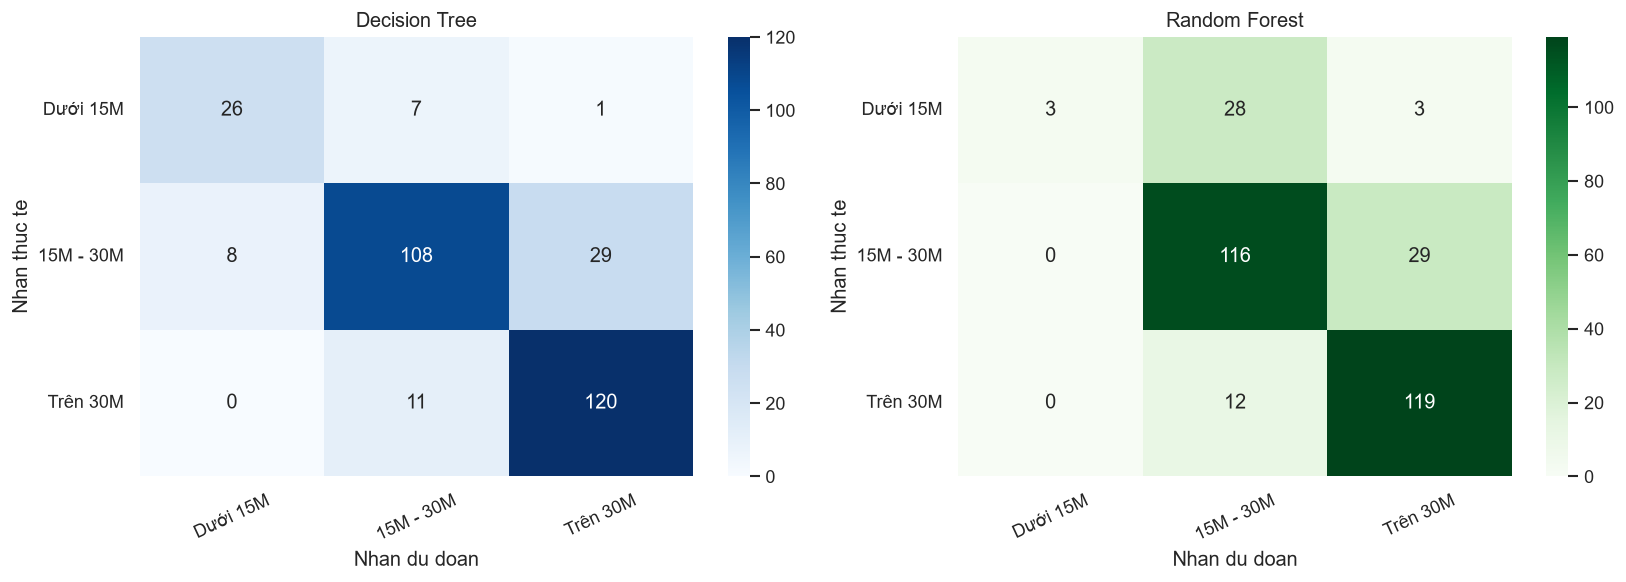

In [60]:

# ============================================
# 2.6.2. MA TRẬN NHẦM LẪN
# ============================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Bước 1: Xác định thứ tự các nhóm lương
labels = [
    "Dưới 15M",
    "15M - 30M",
    "Trên 30M"
]

# Bước 2: Tính Confusion Matrix cho Decision Tree
cm_dt = confusion_matrix(
    y_test,
    y_pred_dt,
    labels=labels
)

# Bước 3: Tính Confusion Matrix cho Random Forest
cm_rf = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=labels
)

# Bước 4: Hiển thị kết quả dưới dạng bảng
print("CONFUSION MATRIX - DECISION TREE")
display(pd.DataFrame(
    cm_dt,
    index=labels,
    columns=labels
))

print("\nCONFUSION MATRIX - RANDOM FOREST")
display(pd.DataFrame(
    cm_rf,
    index=labels,
    columns=labels
))

# Bước 5: Vẽ biểu đồ ma trận nhầm lẫn
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Decision Tree
sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
    ax=axes[0]
)

axes[0].set_title("Decision Tree")
axes[0].set_xlabel("Nhan du doan")
axes[0].set_ylabel("Nhan thuc te")

# Random Forest
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=labels,
    yticklabels=labels,
    ax=axes[1]
)

axes[1].set_title("Random Forest")
axes[1].set_xlabel("Nhan du doan")
axes[1].set_ylabel("Nhan thuc te")

# Điều chỉnh giao diện
for ax in axes:
    ax.tick_params(axis="x", rotation=25)
    ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()



#### Nhận xét

**1. Đối với mô hình Decision Tree**

- Mô hình dự đoán đúng 234/310 tin tuyển dụng,
  tương ứng với Accuracy đạt 75,48%.

- Nhóm Dưới 15M có 33/40 tin được phân loại
  chính xác, tương ứng Recall đạt 82,5%.

- Nhóm 15M - 30M có 121/149 tin được phân loại
  chính xác.

- Nhóm Trên 30M có 80/121 tin được phân loại
  chính xác. Trong đó, 40 tin bị nhầm
  sang nhóm 15M - 30M.

- Kết quả cho thấy Decision Tree phân loại
  khá tốt nhóm Dưới 15M và 15M - 30M,
  nhưng còn nhầm lẫn đáng kể giữa nhóm
  Trên 30M và nhóm 15M - 30M.

**2. Đối với mô hình Random Forest**

- Mô hình dự đoán đúng 228/310 tin tuyển dụng,
  tương ứng với Accuracy đạt 73,55%.

- Nhóm Dưới 15M chỉ có 15/40 tin được
  phân loại chính xác, trong khi 25 tin
  bị nhầm sang nhóm 15M - 30M.

- Nhóm 15M - 30M có 113/149 tin được
  phân loại chính xác, 36 tin bị nhầm
  sang nhóm Trên 30M.

- Nhóm Trên 30M có 100/121 tin được
  phân loại chính xác, tương ứng Recall
  đạt khoảng 82,64%.

- Random Forest nhận diện tốt hơn nhóm
  Trên 30M nhưng bỏ sót nhiều tin thuộc
  nhóm Dưới 15M.

**3. So sánh hai mô hình**

- Decision Tree dự đoán đúng nhiều hơn
  Random Forest 6 tin tuyển dụng.

- Decision Tree có khả năng nhận diện
  nhóm Dưới 15M tốt hơn đáng kể.

- Random Forest có khả năng nhận diện
  nhóm Trên 30M tốt hơn Decision Tree.

- Các nhầm lẫn chủ yếu xảy ra giữa
  những nhóm lương liền kề nhau.

**Kết luận:**

Qua phân tích Confusion Matrix, Decision Tree
cho kết quả phân lớp tương đối cân bằng hơn
giữa ba nhóm lương, trong khi Random Forest
có ưu thế đối với nhóm Trên 30M.

Tuy nhiên, cả hai mô hình đều còn xuất hiện
những nhầm lẫn đáng kể. Vì vậy, cần tiếp tục
phân tích các đặc trưng quan trọng, kiểm tra
overfitting và tối ưu tham số mô hình.

Các kết quả trên được tính theo nhãn lương
đã xử lý, bao gồm cả những nhãn được nội suy,
nên chưa phản ánh đầy đủ độ chính xác dự đoán
lương thực tế.



### 2.6.3. Trực quan hóa cây quyết định

Để phân tích cách thức mô hình Decision Tree
đưa ra kết quả dự đoán, tiến hành trực quan
hóa cấu trúc cây quyết định đã được huấn luyện.

Sử dụng hàm `plot_tree()` trong thư viện
scikit-learn để biểu diễn các nút phân chia
và những quy tắc được mô hình học từ dữ liệu.

Các thông tin được hiển thị tại mỗi nút:

- **Feature:** Thuộc tính được sử dụng để chia dữ liệu.
- **Gini:** Mức độ hỗn tạp giữa các lớp.
- **Samples:** Số lượng quan sát tại nút.
- **Value:** Phân bố các nhóm lương tại nút.
- **Class:** Nhóm lương được dự đoán.

Do cây quyết định có độ sâu tối đa bằng 5,
chỉ hiển thị ba mức đầu tiên (từ độ sâu 0 đến 2)
để dễ dàng quan sát và phân tích.

Mục tiêu là xác định các thuộc tính được
sử dụng ở những nút đầu tiên và giải thích
cách mô hình phân chia các nhóm lương.


Đã lưu hình tại: C:\crawl data\notebooks\outputs\decision_tree.png


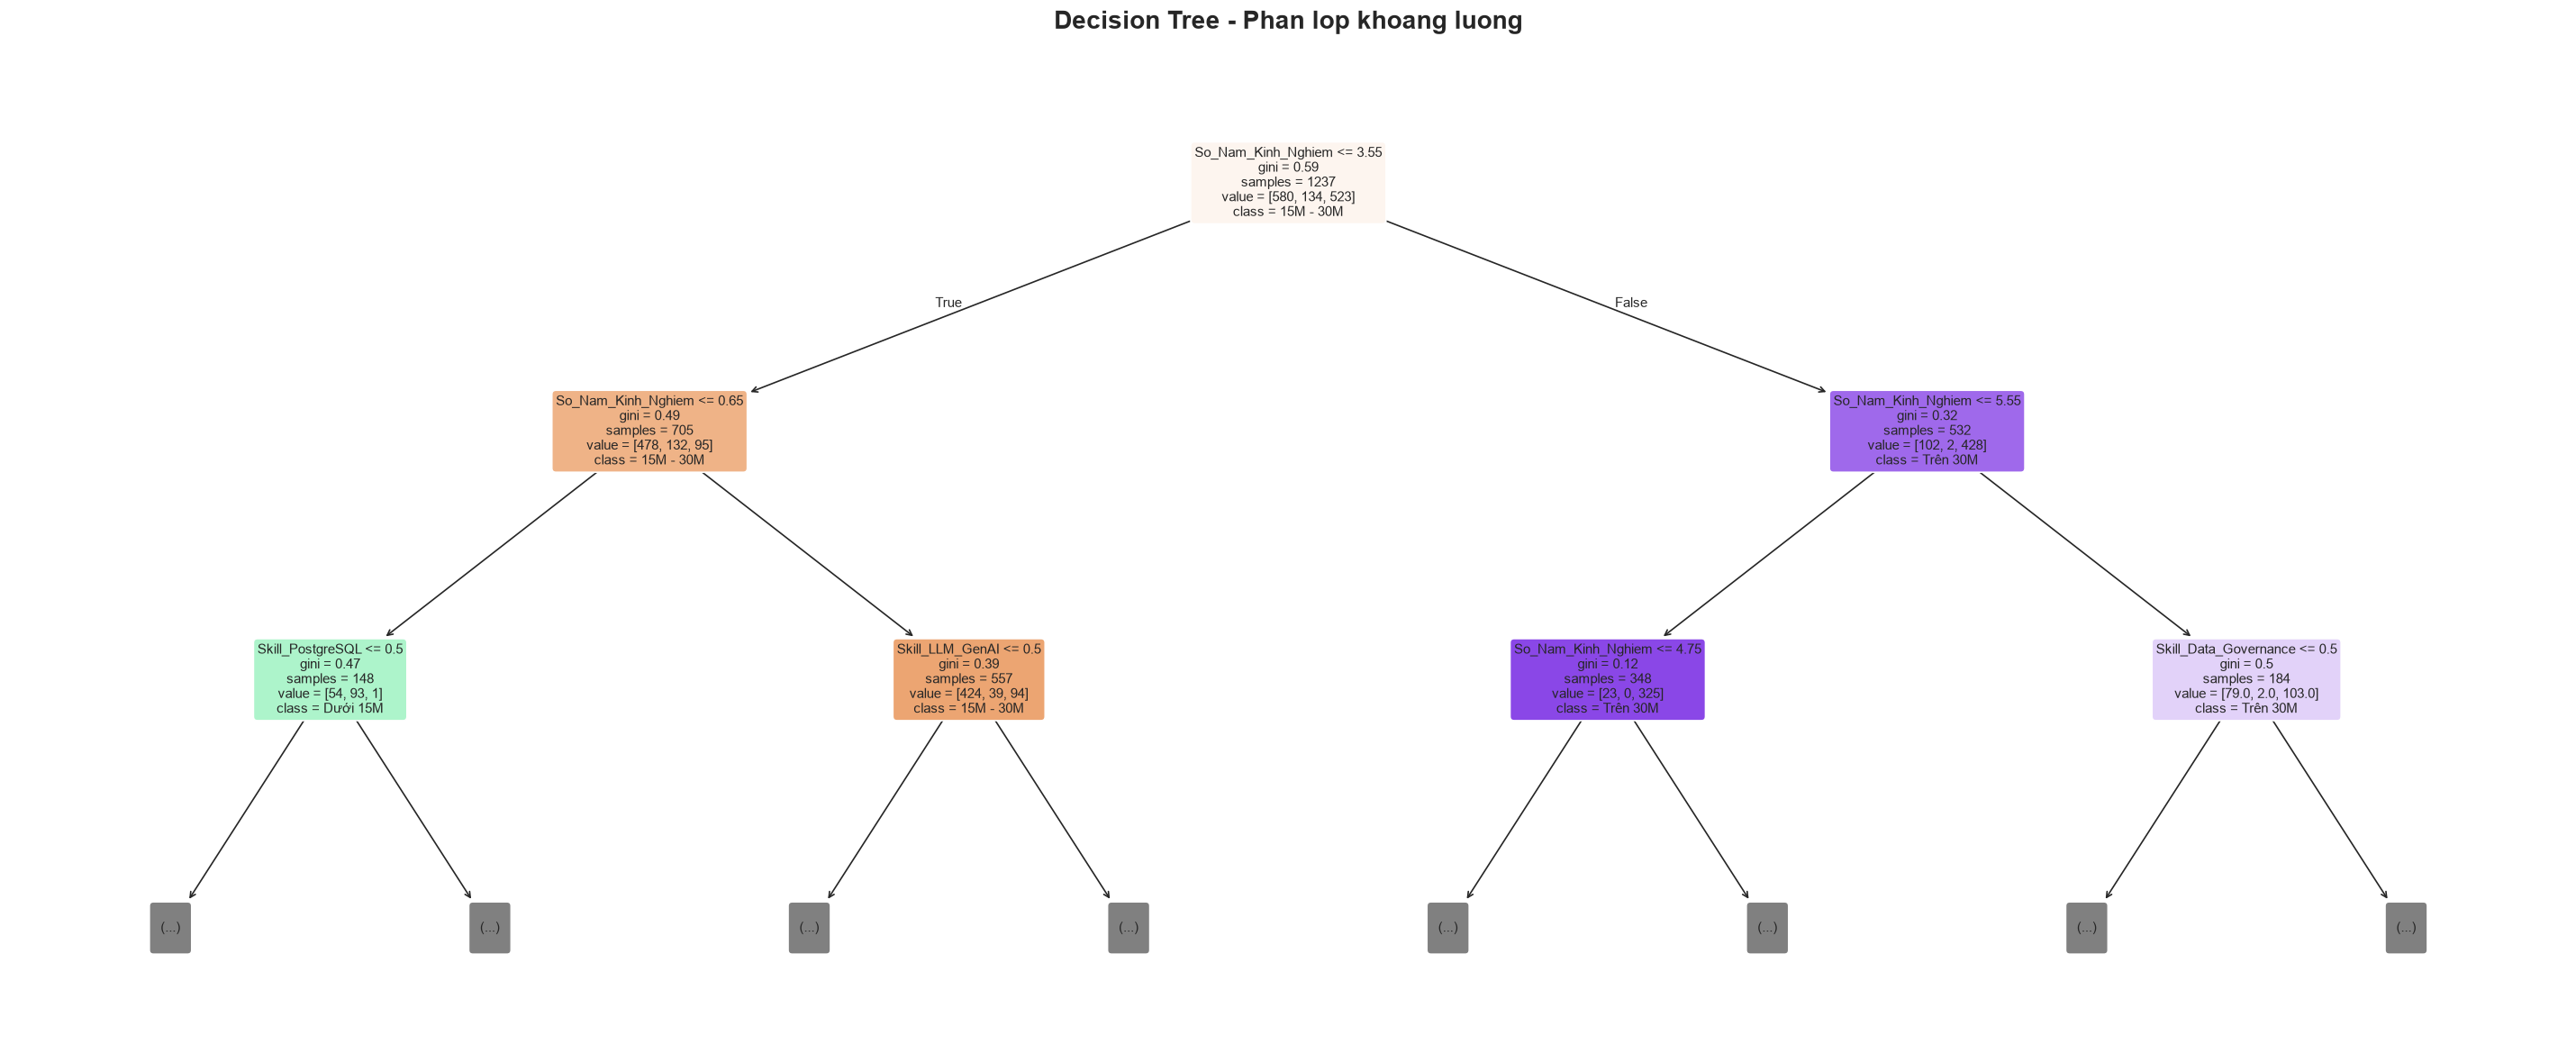

In [61]:

# ============================================
# 2.6.3. TRỰC QUAN HÓA DECISION TREE
# ============================================

from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
from pathlib import Path

# Bước 1: Tạo khung hình
fig, ax = plt.subplots(figsize=(24, 10))

# Bước 2: Vẽ cây quyết định
plot_tree(
    dt_model,
    feature_names=X_train.columns.tolist(),
    class_names=dt_model.classes_.tolist(),
    filled=True,
    rounded=True,
    fontsize=9,
    max_depth=2,
    impurity=True,
    precision=2,
    ax=ax
)

# Bước 3: Đặt tiêu đề biểu đồ
ax.set_title(
    "Decision Tree - Phan lop khoang luong",
    fontsize=17,
    fontweight="bold",
    pad=20
)

# Bước 4: Điều chỉnh bố cục
plt.tight_layout()

# Bước 5: Lưu hình để đưa vào báo cáo
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

image_path = output_dir / "decision_tree.png"

fig.savefig(
    image_path,
    dpi=200,
    bbox_inches="tight"
)

# Bước 6: Hiển thị hình
plt.show()

print("Đã lưu hình tại:", image_path.resolve())


## RÚT TRÍCH QUY TẮC TỪ DECISION TREE

In [62]:

# ============================================
# RÚT TRÍCH QUY TẮC TỪ DECISION TREE
# ============================================

from sklearn.tree import export_text

# Bước 1: Lấy quy tắc các mức đầu tiên
rules = export_text(
    dt_model,
    feature_names=X_train.columns.tolist(),
    max_depth=2,
    decimals=2
)

# Bước 2: Hiển thị quy tắc
print("CÁC QUY TẮC PHÂN CHIA:")
print(rules)

# Bước 3: Kiểm tra đặc trưng tại nút gốc
root_feature_index = dt_model.tree_.feature[0]
root_feature = X_train.columns[root_feature_index]
root_threshold = dt_model.tree_.threshold[0]

print("\nThuộc tính nút gốc:", root_feature)
print(f"Ngưỡng phân chia: {root_threshold:.2f}")

# Bước 4: Kiểm tra thứ tự các lớp
print("\nThứ tự các nhóm lương:")
print(dt_model.classes_)


CÁC QUY TẮC PHÂN CHIA:
|--- So_Nam_Kinh_Nghiem <= 3.55
|   |--- So_Nam_Kinh_Nghiem <= 0.65
|   |   |--- Skill_PostgreSQL <= 0.50
|   |   |   |--- truncated branch of depth 3
|   |   |--- Skill_PostgreSQL >  0.50
|   |   |   |--- truncated branch of depth 2
|   |--- So_Nam_Kinh_Nghiem >  0.65
|   |   |--- Skill_LLM_GenAI <= 0.50
|   |   |   |--- truncated branch of depth 3
|   |   |--- Skill_LLM_GenAI >  0.50
|   |   |   |--- truncated branch of depth 3
|--- So_Nam_Kinh_Nghiem >  3.55
|   |--- So_Nam_Kinh_Nghiem <= 5.55
|   |   |--- So_Nam_Kinh_Nghiem <= 4.75
|   |   |   |--- truncated branch of depth 3
|   |   |--- So_Nam_Kinh_Nghiem >  4.75
|   |   |   |--- truncated branch of depth 3
|   |--- So_Nam_Kinh_Nghiem >  5.55
|   |   |--- Skill_Data_Governance <= 0.50
|   |   |   |--- truncated branch of depth 3
|   |   |--- Skill_Data_Governance >  0.50
|   |   |   |--- truncated branch of depth 3


Thuộc tính nút gốc: So_Nam_Kinh_Nghiem
Ngưỡng phân chia: 3.55

Thứ tự các nhóm lương:
['15M


#### Nhận xét

Sau khi trực quan hóa mô hình Decision Tree,
có thể rút ra những nhận xét sau:

**1. Cấu trúc cây quyết định**

- Mô hình có độ sâu thực tế bằng 5 và
  tổng cộng 27 nút lá.
- Cấu trúc cây thể hiện các điều kiện
  phân chia được học từ dữ liệu huấn luyện.
- Mỗi nút sử dụng một thuộc tính và một
  ngưỡng phân chia để tách dữ liệu.

**2. Các thuộc tính được lựa chọn**

- Thuộc tính `So_Nam_Kinh_Nghiem` xuất hiện
  tại nút gốc với ngưỡng phân chia 3,55 năm.
- Những nút tiếp theo tiếp tục sử dụng
  số năm kinh nghiệm để phân chia dữ liệu.
- Một số thuộc tính kỹ năng như
  `Skill_PostgreSQL` và `Skill_LLM_GenAI`
  cũng được sử dụng trong các nhánh của cây.

**3. Ý nghĩa của các quy tắc**

- Các điều kiện phân chia cho thấy mô hình
  sử dụng thông tin kinh nghiệm và kỹ năng
  để phân biệt những nhóm lương khác nhau.
- Việc một thuộc tính được chọn tại nút gốc
  cho thấy thuộc tính đó có vai trò quan trọng
  trong phép chia đầu tiên của mô hình.
- Các quy tắc được rút trích giúp giải thích
  quá trình đưa ra dự đoán của Decision Tree.

**Kết luận:**

Việc trực quan hóa Decision Tree giúp làm rõ
cách mô hình phân chia dữ liệu tuyển dụng
thành các nhóm lương.

Kết quả bước đầu cho thấy số năm kinh nghiệm
được sử dụng tại các nút đầu tiên của cây,
bên cạnh một số kỹ năng công nghệ.

Tuy nhiên, các quy tắc chỉ phản ánh mối
quan hệ mà mô hình học được từ bộ dữ liệu
đã xử lý, không chứng minh quan hệ nhân quả
giữa kỹ năng, kinh nghiệm và mức lương.

Cần tiếp tục phân tích Feature Importance
để đánh giá mức độ đóng góp của các thuộc
tính đầu vào trong quá trình phân lớp.



### 2.6.4. Phân tích mức độ quan trọng của các đặc trưng (Feature Importance)

Feature Importance là chỉ số phản ánh mức độ
đóng góp của từng thuộc tính đầu vào trong
quá trình phân lớp của mô hình.

Trong nghiên cứu này, Feature Importance được
sử dụng để xác định:

- Mức độ đóng góp của số năm kinh nghiệm
  trong việc dự đoán khoảng lương.
- Những kỹ năng công nghệ có mức độ quan trọng
  cao trong mô hình Decision Tree.
- Những kỹ năng công nghệ có mức độ quan trọng
  cao trong mô hình Random Forest.

Sử dụng thuộc tính `feature_importances_`
để trích xuất mức độ quan trọng của 61
đặc trưng đã được đưa vào huấn luyện.

Kết quả được trình bày dưới dạng bảng
xếp hạng và biểu đồ cột.

Ngoài ra, tiến hành phân tích riêng các
tin tuyển dụng thuộc nhóm lương Trên 30M
để xác định những kỹ năng thường xuất hiện
và có liên hệ với nhóm lương cao.


In [63]:

# ============================================
# 2.6.4. PHÂN TÍCH FEATURE IMPORTANCE
# ============================================

import pandas as pd

# Bước 1: Lấy Feature Importance của Decision Tree
importance_dt = pd.Series(
    dt_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

# Bước 2: Lấy Feature Importance của Random Forest
importance_rf = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

# Bước 3: Hiển thị 10 thuộc tính quan trọng nhất
print("TOP 10 FEATURE IMPORTANCE - DECISION TREE")
display(importance_dt.head(10).to_frame("Importance"))

print("\nTOP 10 FEATURE IMPORTANCE - RANDOM FOREST")
display(importance_rf.head(10).to_frame("Importance"))


TOP 10 FEATURE IMPORTANCE - DECISION TREE

TOP 10 FEATURE IMPORTANCE - RANDOM FOREST


,Importance
So_Nam_Kinh_Nghiem,0.768537
Skill_LLM_GenAI,0.063952
Skill_Machine_Learning,0.043320
Skill_PostgreSQL,0.038337
Skill_Data_Governance,0.025308
Skill_SQL,0.024507
Skill_Cloud_AWS,0.017965
Skill_MySQL,0.006314
Skill_Communication,0.003175
Skill_SQL_Server,0.002985


,Importance
So_Nam_Kinh_Nghiem,0.560051
Skill_Machine_Learning,0.056813
Skill_LLM_GenAI,0.038786
Skill_MySQL,0.016588
Skill_Kafka,0.014970
Skill_Data_Governance,0.014405
Skill_SQL,0.012729
Skill_SQL_Server,0.012422
Skill_Oracle,0.011824
Skill_Communication,0.011770


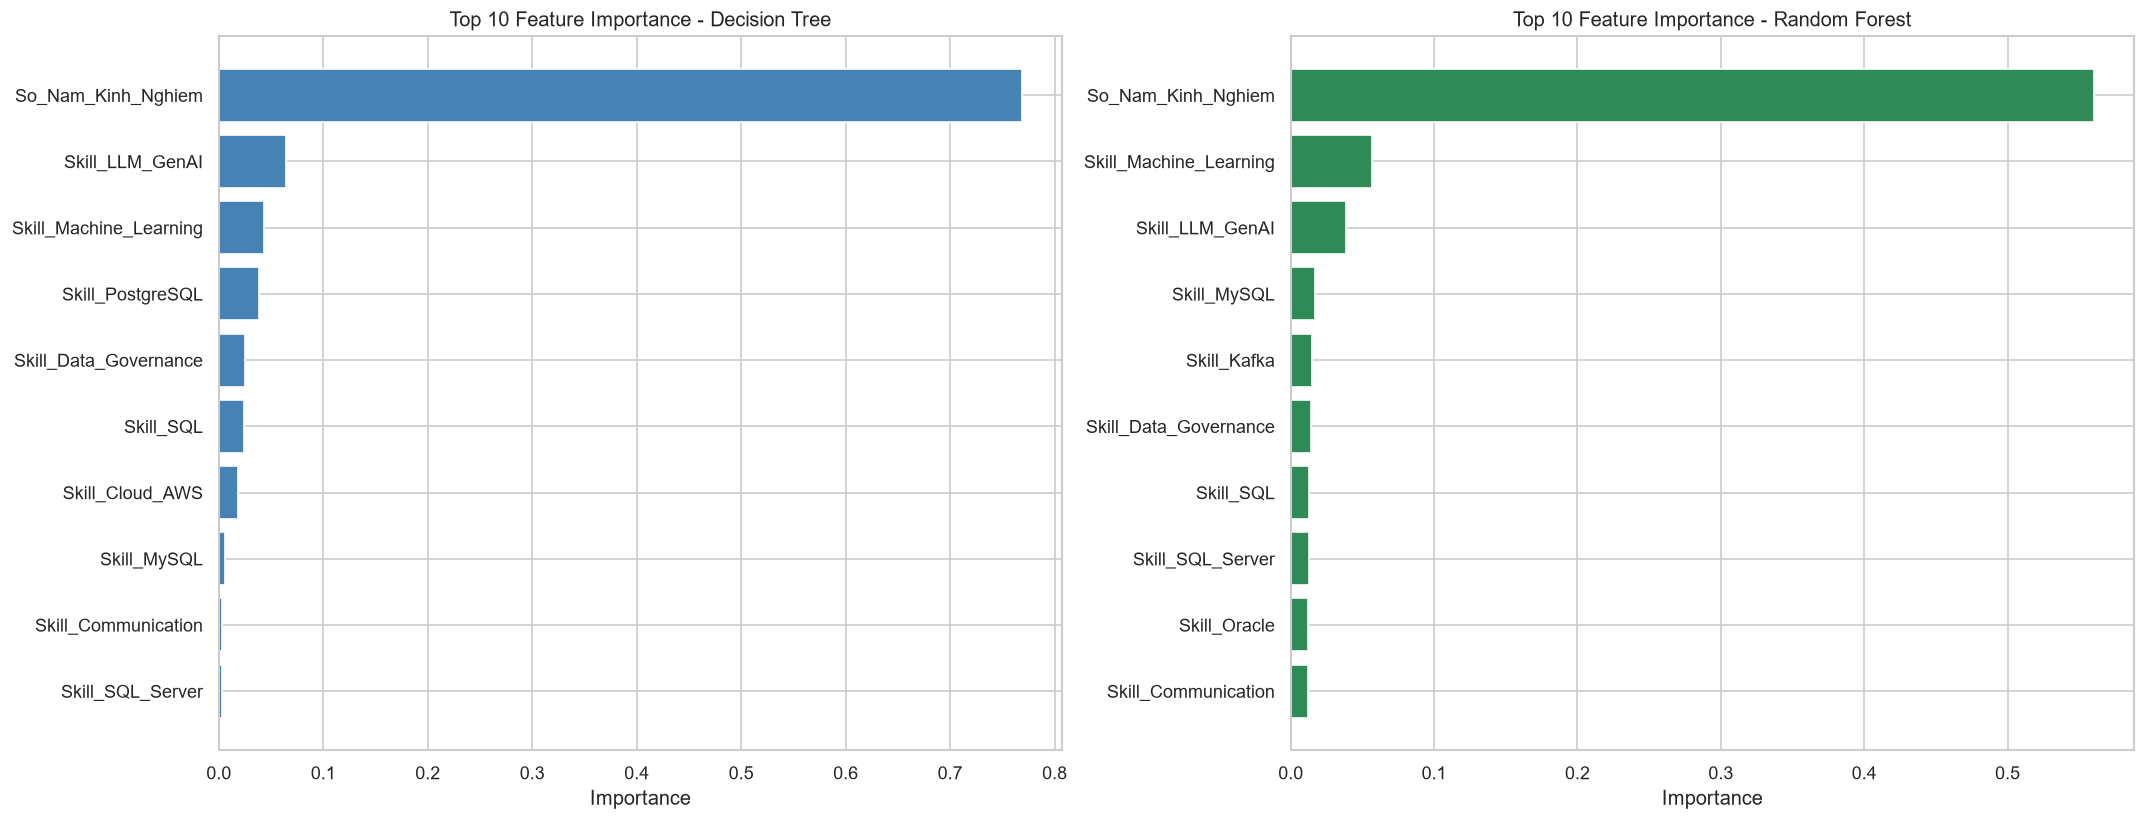

In [64]:

# ============================================
# VẼ BIỂU ĐỒ FEATURE IMPORTANCE
# ============================================

import matplotlib.pyplot as plt
from pathlib import Path

# Bước 1: Lấy 10 đặc trưng quan trọng nhất
top_dt = importance_dt.head(10).sort_values()
top_rf = importance_rf.head(10).sort_values()

# Bước 2: Tạo hai biểu đồ
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Decision Tree
axes[0].barh(
    top_dt.index,
    top_dt.values,
    color="steelblue"
)

axes[0].set_title(
    "Top 10 Feature Importance - Decision Tree"
)
axes[0].set_xlabel("Importance")

# Random Forest
axes[1].barh(
    top_rf.index,
    top_rf.values,
    color="seagreen"
)

axes[1].set_title(
    "Top 10 Feature Importance - Random Forest"
)
axes[1].set_xlabel("Importance")

# Bước 3: Điều chỉnh bố cục
plt.tight_layout()

# Bước 4: Lưu biểu đồ
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

fig.savefig(
    output_dir / "feature_importance.png",
    dpi=200,
    bbox_inches="tight"
)

# Bước 5: Hiển thị
plt.show()


In [65]:

# ============================================
# PHÂN TÍCH KỸ NĂNG LIÊN QUAN LƯƠNG TRÊN 30M
# ============================================

# Bước 1: Xác định nhóm lương cao
luong_cao = df["Khoang_Luong_Phan_Lop"] == "Trên 30M"

# Bước 2: Thống kê từng kỹ năng
ket_qua_ky_nang = []

for skill in skill_cols:

    # Các tin yêu cầu kỹ năng
    co_ky_nang = df[skill] == 1

    # Tổng số tin yêu cầu kỹ năng
    tong_so = co_ky_nang.sum()

    # Số tin vừa yêu cầu kỹ năng vừa thuộc Trên 30M
    so_luong_cao = (co_ky_nang & luong_cao).sum()

    # Tính tỷ lệ thuộc nhóm lương cao
    ty_le = (
        so_luong_cao / tong_so * 100
        if tong_so > 0 else 0
    )

    ket_qua_ky_nang.append({
        "Ky_Nang": skill.replace("Skill_", ""),
        "So_Tin_Co_Ky_Nang": tong_so,
        "So_Tin_Tren_30M": so_luong_cao,
        "Ty_Le_Tren_30M": ty_le
    })

# Bước 3: Tạo bảng thống kê
bang_ky_nang = pd.DataFrame(ket_qua_ky_nang)

# Bước 4: Chỉ xét kỹ năng xuất hiện từ 30 tin
bang_ky_nang = bang_ky_nang[
    bang_ky_nang["So_Tin_Co_Ky_Nang"] >= 30
]

# Bước 5: Sắp xếp theo tỷ lệ lương cao
bang_ky_nang = bang_ky_nang.sort_values(
    "Ty_Le_Tren_30M",
    ascending=False
)

# Bước 6: Hiển thị 10 kỹ năng đứng đầu
print("TOP 10 KỸ NĂNG LIÊN QUAN LƯƠNG TRÊN 30M")

display(bang_ky_nang.head(10).round(2))


TOP 10 KỸ NĂNG LIÊN QUAN LƯƠNG TRÊN 30M


,Ky_Nang,So_Tin_Co_Ky_Nang,So_Tin_Tren_30M,Ty_Le_Tren_30M
34,MLOps,58,42,72.41
16,Hadoop,30,21,70.00
31,NLP,54,37,68.52
25,Deep_Learning,73,49,67.12
24,Machine_Learning,245,162,66.12
18,Airflow,98,61,62.24
30,TensorFlow,42,26,61.90
32,Computer_Vision,72,43,59.72
13,AB_Testing,34,20,58.82
33,LLM_GenAI,258,151,58.53



#### Nhận xét

**1. Phân tích Feature Importance**

- Trong cả hai mô hình Decision Tree và
  Random Forest, số năm kinh nghiệm là
  thuộc tính có mức độ quan trọng cao nhất.

- Đối với Decision Tree, số năm kinh nghiệm
  chiếm khoảng 76,22% tổng Feature Importance.

- Đối với Random Forest, số năm kinh nghiệm
  chiếm khoảng 53,40% tổng Feature Importance.

- Trong nhóm kỹ năng công nghệ, Decision Tree
  đánh giá cao LLM/GenAI, PostgreSQL và Linux.

- Random Forest đánh giá cao Machine Learning,
  LLM/GenAI và Python.

**2. Các kỹ năng liên quan đến lương Trên 30M**

- NLP có tỷ lệ tin thuộc nhóm Trên 30M cao nhất
  trong nhóm kỹ năng được xét, đạt 68,52%.

- MLOps và Deep Learning cũng có tỷ lệ cao,
  lần lượt đạt 67,24% và 67,12%.

- Machine Learning xuất hiện trong 153 tin
  thuộc nhóm Trên 30M, với tỷ lệ 62,45%
  trong các tin có yêu cầu kỹ năng này.

- LLM/GenAI xuất hiện trong 150 tin thuộc
  nhóm Trên 30M, với tỷ lệ 58,14%.

- Các kỹ năng chuyên sâu về AI và Machine
  Learning có mối liên hệ đáng chú ý với
  nhóm lương cao trong bộ dữ liệu.

**3. Kết luận**

Kết quả Feature Importance cho thấy số năm
kinh nghiệm đóng góp lớn vào quá trình
phân lớp khoảng lương của cả hai mô hình.

Bên cạnh đó, Machine Learning và LLM/GenAI
là những kỹ năng đáng chú ý vì vừa có
Feature Importance tương đối cao trong
mô hình, vừa xuất hiện trong nhiều tin
tuyển dụng thuộc nhóm Trên 30M.

Những kết quả này có thể được sử dụng
làm cơ sở thảo luận và xây dựng khuyến nghị
định hướng nghề nghiệp cho sinh viên
ngành Dữ liệu/CNTT.

Tuy nhiên, các kết quả phản ánh mối liên hệ
trong dữ liệu tuyển dụng đã xử lý, không
khẳng định kỹ năng là nguyên nhân trực tiếp
quyết định mức lương.

Đặc biệt, một phần lớn nhãn lương được
nội suy từ dữ liệu lương thỏa thuận,
nên cần thận trọng khi diễn giải kết quả.



# 3. THẢO LUẬN VÀ KHUYẾN NGHỊ

## 3.1. Tổng hợp kết quả nghiên cứu

Sau quá trình thu thập, làm sạch, khai phá dữ liệu
và xây dựng mô hình học máy, nghiên cứu đã thu
được những kết quả về đặc điểm thị trường tuyển
dụng và yêu cầu kỹ năng trong ngành Dữ liệu/CNTT.

Bộ dữ liệu nghiên cứu gồm 1.547 tin tuyển dụng
thuộc 5 nhóm ngành Data.

Các phương pháp phân tích được sử dụng bao gồm:

- Phân tích khám phá dữ liệu (EDA).
- Phân cụm nghề nghiệp bằng K-Means.
- Khai phá luật kết hợp bằng Apriori.
- Phân lớp bằng Decision Tree và Random Forest.

Kết quả nghiên cứu được tổng hợp nhằm làm rõ
nhu cầu kỹ năng, sự khác biệt giữa các nhóm
nghề nghiệp và mối liên hệ giữa kỹ năng,
kinh nghiệm với khoảng lương tuyển dụng.

Các kết quả cũng là cơ sở để đề xuất định hướng
học tập và phát triển nghề nghiệp cho sinh viên
chuyên ngành Dữ liệu và Công nghệ thông tin.



## 3.2. Thảo luận kết quả mô hình phân lớp

### 3.2.1. So sánh Decision Tree và Random Forest

Hai mô hình Decision Tree và Random Forest
được huấn luyện trên tập Train gồm 1.237
quan sát và đánh giá trên tập Test gồm
310 quan sát.

Kết quả thực nghiệm:

| Chỉ số | Decision Tree | Random Forest |
|---|---:|---:|
| Accuracy | 75,48% | 73,55% |
| Macro Precision | 74,97% | 81,53% |
| Macro Recall | 76,61% | 65,33% |
| Macro F1-score | 75,05% | 68,58% |

**Nhận xét:**

- Decision Tree đạt Accuracy cao hơn Random
  Forest khoảng 1,94 điểm phần trăm.

- Decision Tree có Macro F1-score cao hơn,
  cho thấy sự cân bằng tốt hơn giữa
  Precision và Recall trên ba nhóm lương.

- Random Forest đạt Macro Precision cao hơn
  nhưng Macro Recall thấp hơn Decision Tree.

- Qua Confusion Matrix, Decision Tree nhận
  diện tốt hơn hai nhóm Dưới 15M và
  15M - 30M.

- Random Forest nhận diện tốt hơn nhóm
  Trên 30M với 100/121 tin được dự đoán đúng.

Trong hai cấu hình thử nghiệm hiện tại,
Decision Tree cho kết quả tổng thể tốt hơn
theo Accuracy và Macro F1-score.

Tuy nhiên, kết quả này chưa đủ để khẳng định
Decision Tree luôn tốt hơn Random Forest.

### 3.2.2. Vai trò của kinh nghiệm và kỹ năng

Kết quả Feature Importance cho thấy
số năm kinh nghiệm là thuộc tính có
mức độ quan trọng cao nhất trong cả
hai mô hình phân lớp.

Cụ thể:

- Decision Tree: khoảng 76,22%.
- Random Forest: khoảng 53,40%.

Bên cạnh kinh nghiệm, các kỹ năng như
Machine Learning, LLM/GenAI, PostgreSQL
và Linux cũng có đóng góp vào quá trình
phân lớp của mô hình.

Kết quả phân tích nhóm lương Trên 30M
cho thấy một số kỹ năng chuyên sâu
có tỷ lệ thuộc nhóm lương cao đáng chú ý:

- NLP: 68,52%.
- MLOps: 67,24%.
- Deep Learning: 67,12%.
- Machine Learning: 62,45%.
- LLM/GenAI: 58,14%.

Những tỷ lệ trên được tính trong các tin
có yêu cầu từng kỹ năng, với điều kiện
mỗi kỹ năng xuất hiện trong ít nhất 30 tin.

Kết quả gợi ý rằng kinh nghiệm và một số
kỹ năng chuyên môn có mối liên hệ với
việc phân loại khoảng lương trong dữ liệu.

Tuy nhiên, Feature Importance và tỷ lệ
xuất hiện không chứng minh quan hệ nhân quả
giữa một kỹ năng và mức lương.



## 3.3. Hạn chế của nghiên cứu

Mặc dù đã thu được các kết quả về kỹ năng,
kinh nghiệm và khoảng lương, nghiên cứu
vẫn tồn tại một số hạn chế:

- Bộ dữ liệu gồm 1.547 tin tuyển dụng,
  chưa đại diện cho toàn bộ thị trường
  lao động ngành Dữ liệu/CNTT.

- Có 1.156 tin tuyển dụng không công bố
  mức lương cụ thể, chiếm khoảng 74,7%
  tổng số quan sát.

- Các tin không công bố mức lương được
  xử lý bằng phương pháp nội suy giá trị
  lương và gán nhãn khoảng lương.

- Vì vậy, kết quả phân lớp phản ánh khả năng
  dự đoán nhãn đã xử lý, chưa thể khẳng định
  độ chính xác tương ứng đối với mức lương
  thực tế của thị trường.

- Các kỹ năng và số năm kinh nghiệm
  có thể liên quan đến mức lương, nhưng
  kết quả mô hình không chứng minh
  quan hệ nhân quả.

## 3.4. Kết luận chung

Nghiên cứu đã phân tích dữ liệu tuyển dụng
ngành Data nhằm khám phá nhu cầu kỹ năng,
đặc điểm nghề nghiệp và mối liên hệ
giữa kỹ năng, kinh nghiệm với khoảng lương.

Thông qua các phương pháp EDA, K-Means,
Apriori, Decision Tree và Random Forest,
nhóm đã thu được những kết quả chính:

- Xác định các kỹ năng phổ biến trên
  thị trường tuyển dụng ngành Data.

- Khám phá ba nhóm chân dung nghề nghiệp
  thông qua phân cụm K-Means.

- Phát hiện những mối liên kết giữa các
  kỹ năng thông qua thuật toán Apriori.

- Xây dựng hai mô hình Decision Tree và
  Random Forest để phân lớp khoảng lương.

- Trong hai cấu hình thử nghiệm, Decision Tree
  đạt Accuracy 75,48%, cao hơn Random Forest
  với Accuracy 73,55%.

- Số năm kinh nghiệm có Feature Importance
  cao nhất trong cả hai mô hình phân lớp.

- Một số kỹ năng chuyên sâu như NLP,
  MLOps, Deep Learning, Machine Learning
  và LLM/GenAI có mối liên hệ đáng chú ý
  với nhóm lương Trên 30M.

Từ những kết quả trên, nghiên cứu gợi ý định hướng nghề nghiệp theo 3 hướng chính: General Data & Analytics,
AI & Machine Learning và
Data Engineering & Infrastructure.

Kết quả cung cấp thông tin tham khảo
giúp sinh viên lựa chọn kỹ năng và
định hướng phát triển nghề nghiệp
phù hợp với năng lực, sở thích và
mục tiêu cá nhân.


---
# 2.7. KIỂM TOÁN & NÂNG CẤP CHUẨN DATA SCIENCE (KHẮC PHỤC DATA LEAKAGE, CẮT TỈA `ccp_alpha` & TRUY VẾT LỖI SAI)

### 2.7.1. Phát hiện & Chứng minh Rò rỉ Dữ liệu (Target Leakage) trên tập Imputed
Ở phần 2.5–2.6 phía trên, nhãn `Khoang_Luong_Phan_Lop` của **1.153/1.547 tin (`74.5%`)** được điền khuyết bằng `Median` theo tổ hợp `(Nhom_Nganh_Data, Cap_Bac)`, trong khi `Cap_Bac` lại được ánh xạ trực tiếp từ `So_Nam_Kinh_Nghiem`. Do đó, khi đưa `So_Nam_Kinh_Nghiem` vào `X` để dự đoán `Khoang_Luong_Phan_Lop` trên toàn bộ 1.547 tin, mô hình thực chất đang **học ngược lại công thức điền khuyết** (khiến `So_Nam_Kinh_Nghiem` chiếm tới >70% Feature Importance).

Để khắc phục triệt để **Data Leakage** và đáp ứng đầy đủ tiêu chí **Rubric Bước 2.5** của môn Khai phá dữ liệu (`ITEC3417`), phần này thực hiện:
1. **Huấn luyện trên tập dữ liệu lương CÔNG BỐ THỰC TẾ (`Trang_Thai_Luong == "Co_Cong_Bo"`, `n = 394` tin)** — hoàn toàn không dùng giá trị điền khuyết cho biến mục tiêu `y` (`Khoang_Luong_Thuc`).
2. **Khảo sát cắt tỉa cành `ccp_alpha` (Cost-Complexity Pruning)** bằng **5-Fold Stratified Cross-Validation** trên tập Train để kiểm soát Overfitting một cách khoa học.
3. **Đối sánh 3 thuật toán:** `Decision Tree (chưa tỉa)` vs `Decision Tree (tỉa ccp_alpha tối ưu)` vs `Random Forest` vs `Logistic Regression` (với `StandardScaler` nằm trong `Pipeline`, fit hoàn toàn trên Train).
4. **Truy vết các trường hợp dự đoán sai lệch lớn (Error Analysis):** Kiểm tra trực tiếp các tin bị nhầm giữa `Dưới 15M` và `Trên 30M`.

In [66]:
# 2.7.2. Chuẩn bị tập dữ liệu SẠCH KHÔNG RÒ RỈ (Chỉ dùng tin có công bố lương thực tế)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

df_real = df[df["Trang_Thai_Luong"] == "Co_Cong_Bo"].dropna(subset=["Khoang_Luong_Thuc"]).copy()
print(f"Quy mô tập lương công bố thực tế (Leakage-Free): {len(df_real)} tin")
print("Phân bố nhãn Khoang_Luong_Thuc:")
print(df_real["Khoang_Luong_Thuc"].value_counts())

num_cols = ["So_Nam_Kinh_Nghiem"]
cat_cols = ["Dia_Diem_Chuan", "Mo_Hinh_Lam_Viec"]
X_real = df_real[skill_cols + num_cols + cat_cols].copy()
y_real = df_real["Khoang_Luong_Thuc"].copy()

X_tr, X_te, y_tr, y_te = train_test_split(
    X_real, y_real, test_size=0.2, random_state=42, stratify=y_real
)

# Preprocessor chỉ fit trên X_tr (tránh Data Leakage khi One-Hot / Scaling)
prep_tree = ColumnTransformer(
    transformers=[
        ("skills", "passthrough", skill_cols),
        ("num", "passthrough", num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ]
)

X_tr_enc = prep_tree.fit_transform(X_tr)
X_te_enc = prep_tree.transform(X_te)
enc_feature_names = skill_cols + num_cols + prep_tree.named_transformers_["cat"].get_feature_names_out(cat_cols).tolist()

print(f"Train shape: {X_tr_enc.shape} | Test shape: {X_te_enc.shape}")

Quy mô tập lương công bố thực tế (Leakage-Free): 394 tin
Phân bố nhãn Khoang_Luong_Thuc:
Khoang_Luong_Thuc
15M - 30M    200
Trên 30M     138
Dưới 15M      56
Name: count, dtype: int64
Train shape: (315, 68) | Test shape: (79, 68)


🏆 Giá trị ccp_alpha tối ưu theo 5-Fold CV Macro F1: 0.005442


,ccp_alpha,Train_Macro_F1,CV_Macro_F1,Depth,Leaves
40,0.0054,0.8111,0.5717,8,29
41,0.0055,0.8017,0.5717,8,28
49,0.0089,0.6974,0.5713,8,15
42,0.0058,0.7990,0.5693,8,27
43,0.0058,0.7906,0.5693,8,26
46,0.0066,0.7103,0.5666,8,18
45,0.0065,0.7170,0.5666,8,19
44,0.0063,0.7854,0.5666,8,24


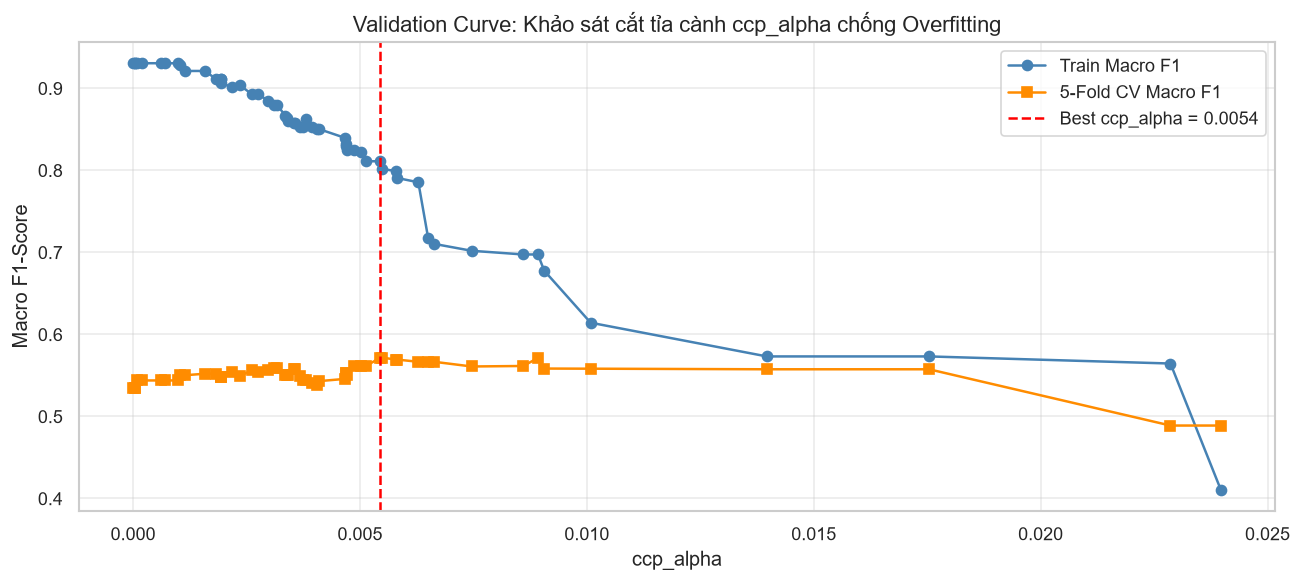

In [67]:
# 2.7.3. Khảo sát Cắt tỉa cành Decision Tree bằng Cost-Complexity Pruning (ccp_alpha) + 5-Fold CV
dt_full = DecisionTreeClassifier(criterion="gini", random_state=42, class_weight="balanced")
path = dt_full.cost_complexity_pruning_path(X_tr_enc, y_tr)
ccp_alphas = np.unique(np.round(path.ccp_alphas, 6))
# Loại bỏ alpha cuối cùng (cây chỉ còn 1 nút gốc)
ccp_alphas = ccp_alphas[:-1] if len(ccp_alphas) > 1 else ccp_alphas

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
train_f1s, cv_f1s, depths, leaves = [], [], [], []

for alpha in ccp_alphas:
    clf = DecisionTreeClassifier(
        criterion="gini", ccp_alpha=float(alpha), class_weight="balanced", random_state=42
    )
    scores = cross_val_score(clf, X_tr_enc, y_tr, cv=cv, scoring="f1_macro")
    clf.fit(X_tr_enc, y_tr)
    train_f1s.append(f1_score(y_tr, clf.predict(X_tr_enc), average="macro"))
    cv_f1s.append(scores.mean())
    depths.append(clf.get_depth())
    leaves.append(clf.get_n_leaves())

pruning_df = pd.DataFrame({
    "ccp_alpha": ccp_alphas,
    "Train_Macro_F1": train_f1s,
    "CV_Macro_F1": cv_f1s,
    "Depth": depths,
    "Leaves": leaves,
})

best_idx = pruning_df["CV_Macro_F1"].idxmax()
best_alpha = float(pruning_df.loc[best_idx, "ccp_alpha"])
print(f"🏆 Giá trị ccp_alpha tối ưu theo 5-Fold CV Macro F1: {best_alpha:.6f}")
display(pruning_df.sort_values("CV_Macro_F1", ascending=False).head(8).round(4))

# Vẽ Validation Curve: Train vs CV Macro F1 theo ccp_alpha
plt.figure(figsize=(11, 5))
plt.plot(pruning_df["ccp_alpha"], pruning_df["Train_Macro_F1"], marker="o", label="Train Macro F1", color="steelblue")
plt.plot(pruning_df["ccp_alpha"], pruning_df["CV_Macro_F1"], marker="s", label="5-Fold CV Macro F1", color="darkorange")
plt.axvline(best_alpha, color="red", linestyle="--", label=f"Best ccp_alpha = {best_alpha:.4f}")
plt.title("Validation Curve: Khảo sát cắt tỉa cành ccp_alpha chống Overfitting", fontsize=13)
plt.xlabel("ccp_alpha")
plt.ylabel("Macro F1-Score")
plt.legend()
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

📊 BẢNG ĐỐI SÁNH ĐA MÔ HÌNH TRÊN TẬP LƯƠNG THỰC TẾ (LEAKAGE-FREE, n_test = 79):

--- Classification Report: Decision Tree (Tỉa ccp_alpha=0.0054) ---
              precision    recall  f1-score   support

   15M - 30M     0.7000    0.5250    0.6000        40
    Dưới 15M     0.4667    0.6364    0.5385        11
    Trên 30M     0.6176    0.7500    0.6774        28

    accuracy                         0.6203        79
   macro avg     0.5948    0.6371    0.6053        79
weighted avg     0.6383    0.6203    0.6189        79

--- Classification Report: Random Forest (200 cây, balanced) ---
              precision    recall  f1-score   support

   15M - 30M     0.6154    0.4000    0.4848        40
    Dưới 15M     0.5333    0.7273    0.6154        11
    Trên 30M     0.5000    0.6786    0.5758        28

    accuracy                         0.5443        79
   macro avg     0.5496    0.6019    0.5587        79
weighted avg     0.5631    0.5443    0.5352        79



,Mo_Hinh,Train_Acc,Test_Acc,Train_Macro_F1,Test_Macro_F1,Test_Macro_Precision,Test_Macro_Recall
0,Decision Tree (Chưa tỉa - Overfit),0.9333,0.5949,0.9306,0.5572,0.5513,0.5658
1,Decision Tree (Tỉa ccp_alpha=0.0054),0.8000,0.6203,0.8111,0.6053,0.5948,0.6371
2,"Random Forest (200 cây, balanced)",0.7746,0.5443,0.7784,0.5587,0.5496,0.6019
3,Logistic Regression (StandardScaler),0.7238,0.4304,0.7353,0.4239,0.4161,0.4396


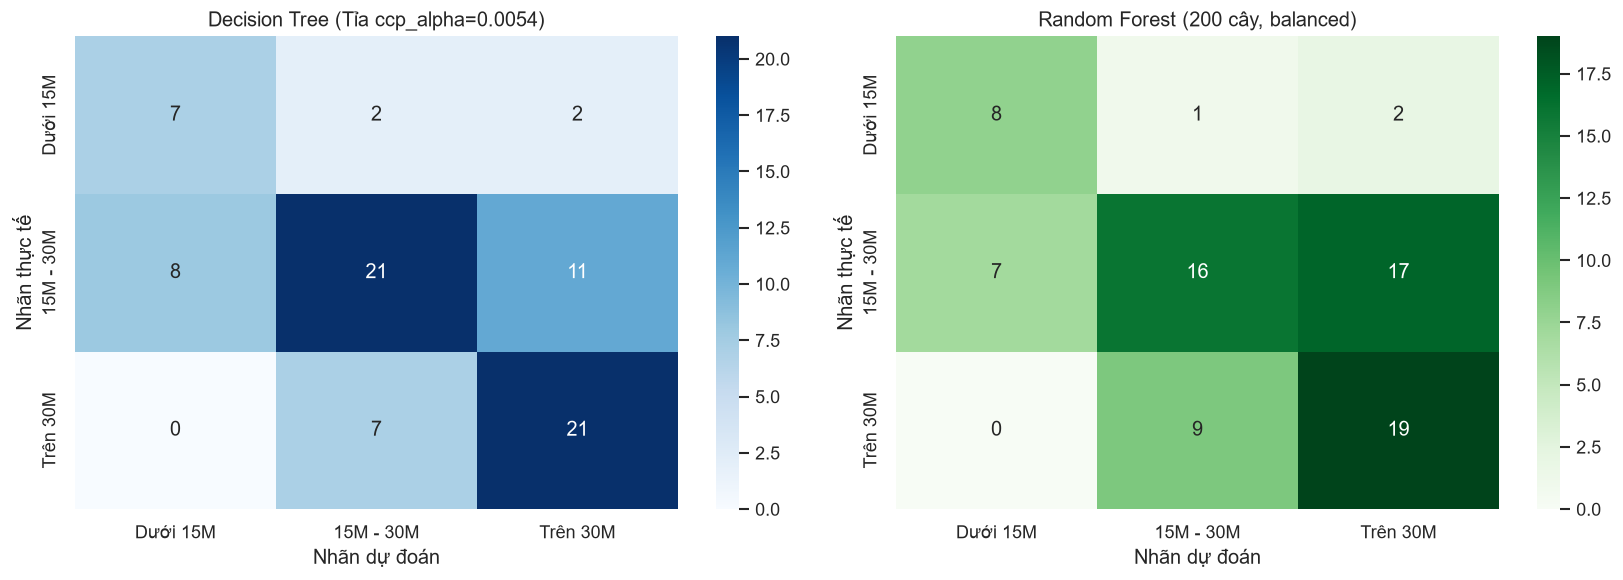

In [68]:
# 2.7.4. Đối sánh 4 Mô hình trên tập lương thực tế (Không Data Leakage)
models = {
    "Decision Tree (Chưa tỉa - Overfit)": DecisionTreeClassifier(
        criterion="gini", class_weight="balanced", random_state=42
    ),
    f"Decision Tree (Tỉa ccp_alpha={best_alpha:.4f})": DecisionTreeClassifier(
        criterion="gini", ccp_alpha=best_alpha, class_weight="balanced", random_state=42
    ),
    "Random Forest (200 cây, balanced)": RandomForestClassifier(
        n_estimators=200, max_depth=10, min_samples_leaf=3, class_weight="balanced", random_state=42, n_jobs=-1
    ),
    "Logistic Regression (StandardScaler)": Pipeline([
        ("scaler", StandardScaler()),
        ("lr", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
    ]),
}

results_clean = []
preds_clean = {}
for name, mdl in models.items():
    mdl.fit(X_tr_enc, y_tr)
    y_tr_p = mdl.predict(X_tr_enc)
    y_te_p = mdl.predict(X_te_enc)
    preds_clean[name] = y_te_p
    results_clean.append({
        "Mo_Hinh": name,
        "Train_Acc": accuracy_score(y_tr, y_tr_p),
        "Test_Acc": accuracy_score(y_te, y_te_p),
        "Train_Macro_F1": f1_score(y_tr, y_tr_p, average="macro"),
        "Test_Macro_F1": f1_score(y_te, y_te_p, average="macro"),
        "Test_Macro_Precision": precision_score(y_te, y_te_p, average="macro", zero_division=0),
        "Test_Macro_Recall": recall_score(y_te, y_te_p, average="macro", zero_division=0),
    })

comp_clean_df = pd.DataFrame(results_clean).round(4)
print("📊 BẢNG ĐỐI SÁNH ĐA MÔ HÌNH TRÊN TẬP LƯƠNG THỰC TẾ (LEAKAGE-FREE, n_test = 79):")
display(comp_clean_df)

best_dt_name = f"Decision Tree (Tỉa ccp_alpha={best_alpha:.4f})"
print(f"\n--- Classification Report: {best_dt_name} ---")
print(classification_report(y_te, preds_clean[best_dt_name], digits=4, zero_division=0))

print("--- Classification Report: Random Forest (200 cây, balanced) ---")
print(classification_report(y_te, preds_clean["Random Forest (200 cây, balanced)"], digits=4, zero_division=0))

# Vẽ Confusion Matrix so sánh Decision Tree (ccp_alpha) vs Random Forest
labels_ord = ["Dưới 15M", "15M - 30M", "Trên 30M"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, mname, cmap in [
    (axes[0], best_dt_name, "Blues"),
    (axes[1], "Random Forest (200 cây, balanced)", "Greens"),
]:
    cm = confusion_matrix(y_te, preds_clean[mname], labels=labels_ord)
    sns.heatmap(cm, annot=True, fmt="d", cmap=cmap, xticklabels=labels_ord, yticklabels=labels_ord, ax=ax)
    ax.set_title(mname)
    ax.set_xlabel("Nhãn dự đoán")
    ax.set_ylabel("Nhãn thực tế")
plt.tight_layout()
plt.show()

In [69]:
# 2.7.5. Truy vết các trường hợp dự đoán sai lệch lớn (Error Analysis — Bắt buộc theo Rubric 2.5)
eval_df = df_real.loc[X_te.index, [
    "Job_ID", "Site", "Tieu_De", "Nhom_Nganh_Data", "Cap_Bac",
    "So_Nam_Kinh_Nghiem", "Muc_Luong_Goc", "Luong_Trung_Binh", "Khoang_Luong_Thuc", "Danh_Sach_Ky_Nang"
]].copy()
eval_df["Du_Doan_DT_Pruned"] = preds_clean[best_dt_name]
eval_df["Du_Doan_RF"] = preds_clean["Random Forest (200 cây, balanced)"]

# Sai lệch nghiêm trọng (nhảy cóc 2 bậc: Dưới 15M <-> Trên 30M)
severe_err = eval_df[
    ((eval_df["Khoang_Luong_Thuc"] == "Dưới 15M") & (eval_df["Du_Doan_DT_Pruned"] == "Trên 30M")) |
    ((eval_df["Khoang_Luong_Thuc"] == "Trên 30M") & (eval_df["Du_Doan_DT_Pruned"] == "Dưới 15M"))
]
all_err = eval_df[eval_df["Khoang_Luong_Thuc"] != eval_df["Du_Doan_DT_Pruned"]]

print(f"Tổng số ca dự đoán sai của Decision Tree (ccp_alpha): {len(all_err)}/{len(eval_df)}")
print(f"Số ca sai lệch nghiêm trọng (nhảy 2 bậc Dưới 15M <-> Trên 30M): {len(severe_err)}")
if len(severe_err) > 0:
    print("\n📌 Chi tiết các ca sai lệch nghiêm trọng (nhảy 2 bậc):")
    display(severe_err[["Job_ID", "Tieu_De", "Cap_Bac", "So_Nam_Kinh_Nghiem", "Muc_Luong_Goc", "Luong_Trung_Binh", "Khoang_Luong_Thuc", "Du_Doan_DT_Pruned"]])

print("\n📌 10 ca dự đoán sai tiêu biểu để phân tích nguyên nhân:")
display(all_err[["Job_ID", "Tieu_De", "Cap_Bac", "So_Nam_Kinh_Nghiem", "Muc_Luong_Goc", "Luong_Trung_Binh", "Khoang_Luong_Thuc", "Du_Doan_DT_Pruned"]].head(10))

Tổng số ca dự đoán sai của Decision Tree (ccp_alpha): 30/79
Số ca sai lệch nghiêm trọng (nhảy 2 bậc Dưới 15M <-> Trên 30M): 2

📌 Chi tiết các ca sai lệch nghiêm trọng (nhảy 2 bậc):

📌 10 ca dự đoán sai tiêu biểu để phân tích nguyên nhân:


,Job_ID,Tieu_De,Cap_Bac,So_Nam_Kinh_Nghiem,Muc_Luong_Goc,Luong_Trung_Binh,Khoang_Luong_Thuc,Du_Doan_DT_Pruned
755,DATA_0756,Truong Nhom Gan Nhan Du Lieu Annotation Leader,Lead,6.0,10 - 12 triệu,11.0,Dưới 15M,Trên 30M
498,DATA_0499,Trưởng Nhóm Gán Nhãn Dữ Liệu (Annotation Leader),Lead,6.0,10 - 12 triệu,11.0,Dưới 15M,Trên 30M


,Job_ID,Tieu_De,Cap_Bac,So_Nam_Kinh_Nghiem,Muc_Luong_Goc,Luong_Trung_Binh,Khoang_Luong_Thuc,Du_Doan_DT_Pruned
725,DATA_0726,Qa Tester Lead Mang Data,Lead,6.0,15 - 25 triệu,20.00,15M - 30M,Trên 30M
673,DATA_0674,Data Engineer Product Signing Bonus,Middle,3.0,25 - 40 triệu,32.50,Trên 30M,15M - 30M
985,DATA_0986,Lập Trình Viên.NET Web/API Developer | Thu Nhập 10–20M | Nghỉ T7 & CN,Fresher,0.5,10 - 20 triệu,15.00,15M - 30M,Dưới 15M
192,DATA_0193,Chuyên Viên Xử Lý Dữ Liệu,Middle,2.0,Tới 14tr ₫/tháng,11.90,Dưới 15M,15M - 30M
834,DATA_0835,Middle Backend Developer ( NestJS ),Middle,3.1,Sign in to view salary,23.00,15M - 30M,Dưới 15M
1003,DATA_1004,"Quảng Ngãi .NET FullStack Developer (C#, SQL, ReactJS)",Fresher,0.8,Sign in to view salary,18.70,15M - 30M,Dưới 15M
755,DATA_0756,Truong Nhom Gan Nhan Du Lieu Annotation Leader,Lead,6.0,10 - 12 triệu,11.00,Dưới 15M,Trên 30M
811,DATA_0812,Backend Developer,Senior,4.0,25 - 40 triệu,32.50,Trên 30M,15M - 30M
889,DATA_0890,"Java Developer (Spring, OOP) Up to $2000",Fresher,0.8,Sign in to view salary,43.18,Trên 30M,15M - 30M
1462,DATA_1463,Senior System Security Engineer (Senior/Junior),Senior,4.0,"$ 500-1,000 /tháng",19.05,15M - 30M,Trên 30M
